# 05 · Adaptive Bayesian multi-agent model: development, controls and ablations

# Part A · Rossmann daily store sales

In [1]:
import json, hashlib, warnings, platform, sys, os, gc, gzip, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image, display


from importlib.metadata import version as package_version

PACKAGE_VERSIONS = {
    name: package_version(name)
    for name in [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "lightgbm",
        "xgboost",
        "catboost",
        "torch",
        "matplotlib",
        "cloudpickle",
    ]
}

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = (
    ROOT / "outputs" / "data" / "interim",
    ROOT / "outputs" / "data" / "processed",
    ROOT / "outputs" / "data" / "splits",
)
TABLES, FIGURES, MANIFESTS, CONFIGS = (
    ROOT / "outputs" / "tables",
    ROOT / "outputs" / "figures",
    ROOT / "outputs" / "manifests",
    ROOT / "outputs" / "configs",
)
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB05_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """18–20 pt masters; inspect readability at 180 mm full-width placement.
    Wide multi-panel masters are exported as separate panels, without shrinking text.
    """
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


# ---- study design, features, preprocessing parameters (all fitted on train in NB02) ----
design = json.loads((CONFIGS / "study_design.json").read_text())
prep = json.loads((CONFIGS / "preprocessing.json").read_text())
FEATURES, CATEGORICAL, NUMERIC, GROUPS = (
    prep["features"],
    prep["categorical"],
    prep["numeric"],
    prep["groups"],
)
data = pd.read_parquet(
    PROCESSED / "rossmann_features.parquet",
    filters=[("partition", "in", ["train", "valid"])],
)
PART = {
    p: data[data["partition"] == p].reset_index(drop=True) for p in ("train", "valid")
}  # locked / external partitions are not loaded before NB06

PART["train"] = PART["train"][
    PART["train"]["Date"] <= design["fit_label_cutoff"]
].reset_index(drop=True)
PART["valid"] = PART["valid"][
    PART["valid"]["Date"] <= design["selection_label_cutoff"]
].reset_index(drop=True)


def fold_stats(fit_df):
    """Imputation and scaling parameters estimated on a fold's fit rows only (used for inner-fold out-of-fold predictions)."""
    return {
        "median": fit_df[NUMERIC].median().fillna(0).to_dict(),
        "mean": fit_df[NUMERIC].mean().fillna(0).to_dict(),
        "std": fit_df[NUMERIC].std().replace(0, 1).fillna(1).to_dict(),
        "categorical_levels": {
            c: sorted(fit_df[c].dropna().unique().tolist()) for c in CATEGORICAL
        },
    }


def design_matrix(df, kind, stats=None):
    """kind = 'tree': raw features, NaN kept, categoricals as integer codes.
    kind = 'dense': median imputation + missing indicators + standardisation + one-hot categoricals (for linear / kNN / neural models);
    the parameters come from Configs/preprocessing.json (fitted on train) unless fold-specific `stats` are given.
    """
    X = df[FEATURES].copy()
    if kind == "tree":
        return X
    st = stats or prep
    for c in prep["missing_indicator_for"]:
        X[f"{c}__na"] = X[c].isna().astype(np.float32)
    for c in NUMERIC:
        X[c] = ((X[c].fillna(st["median"][c]) - st["mean"][c]) / st["std"][c]).astype(
            np.float32
        )
    for c in CATEGORICAL:
        for lvl in prep["categorical_levels"][c]:
            X[f"{c}__{lvl}"] = (
                (X[c] == lvl)
                & (lvl in st.get("categorical_levels", prep["categorical_levels"])[c])
            ).astype(np.float32)
        X = X.drop(columns=c)
    return X


# ---- metrics ------------------------------------------------------------------
def rmspe(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y != 0
    return float(np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2)))


def point_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "RMSPE": rmspe(y, p),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE": float(np.mean(np.abs(y - p))),
        "sMAPE": float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


def interval_metrics(y, lo, hi):
    y, lo, hi = (np.asarray(a, float) for a in (y, lo, hi))
    return {
        "PICP90": float(np.mean((y >= lo) & (y <= hi))),
        "MPIW90": float(np.mean(hi - lo)),
        "MPIW90_rel": float(np.mean((hi - lo) / y)),
    }


def bootstrap_ci(y, p, clusters, B=2000, seed=SEED, metric="RMSPE"):
    """Store-cluster bootstrap: resample stores, retaining each complete observed history."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    d = pd.factorize(pd.Series(clusters))[0]
    nd = d.max() + 1
    if metric == "RMSPE":
        v = ((y - p) / y) ** 2
    elif metric == "RMSE":
        v = (y - p) ** 2
    else:
        v = np.abs(y - p)
    s = np.bincount(d, weights=v, minlength=nd)
    n = np.bincount(d, minlength=nd).astype(float)
    g = np.random.default_rng(seed)
    idx = g.integers(0, nd, size=(B, nd))
    stat = s[idx].sum(1) / n[idx].sum(1)
    if metric in ("RMSPE", "RMSE"):
        stat = np.sqrt(stat)
    return float(np.percentile(stat, 2.5)), float(np.percentile(stat, 97.5))


# ---- experiment and run folder ---------------------------------------------------
experiment = json.loads((CONFIGS / "current_experiment.json").read_text())
EXPERIMENT_ID = experiment["experiment_id"]

assert PART["train"].Date.max() <= pd.Timestamp(design["fit_label_cutoff"])
assert PART["valid"].Date.max() <= pd.Timestamp(design["selection_label_cutoff"])
assert experiment["selection_label_cutoff"] == design["selection_label_cutoff"]

RUNS = ROOT / "outputs" / "artifacts" / "runs" / EXPERIMENT_ID
RUNS.mkdir(parents=True, exist_ok=True)


N_TRIALS = (
    8  # identical random-search budget for every tunable model (NB03, NB04, NB05)
)
N_JOBS = (
    8  # initial cap; training-only resource probe selects the execution cap in NB03
)
INNER_FOLDS = prep[
    "inner_folds"
]  # expanding-window folds inside train (NB02, Table 2.12)

## 1. Agents: the seven NB03 and NB04 experts and seven LightGBM views, refitted at each development origin

In [2]:
import lightgbm as lgb, xgboost as xgb, catboost as cb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
NB = "NB05"
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)  # one-hot design matrix of the Ridge expert
BLOCKS = {"F1": ("2014-03-25", "2014-04-01", "2014-06-30"), "F2": ("2014-06-24", "2014-07-01", "2014-09-30"), "F3": ("2014-09-24", "2014-10-01", "2014-12-25"), "V": ("2014-12-25", "2015-01-01", "2015-04-24")}
assert all(BLOCKS[f][:2] == (INNER_FOLDS[f]["fit_end"], INNER_FOLDS[f]["eval_start"]) for f in ("F1", "F2", "F3"))
tv = pd.concat([PART["train"], PART["valid"]], ignore_index=True).sort_values(["Date", "Store"], kind="stable").reset_index(drop=True)
assert tv["Date"].max() <= pd.Timestamp("2015-04-30")
stream = tv[(tv["Date"] >= "2014-04-01") & (tv["Date"] <= "2015-04-24")].copy()
stream["block"] = np.select([stream["Date"] <= b[2] for b in BLOCKS.values()], list(BLOCKS), default="gap")
stream = stream[stream["block"] != "gap"].reset_index(drop=True)
PRIOR_EXPERIMENT = "EXP_20261031T034919677897Z"  # NB03 and NB04 selected the expert configurations in this experiment (43 features); the experts are refitted here on the current features
_FROZEN_CFG = {"LightGBM": {"learning_rate": 0.03239262302773627, "num_leaves": 255, "min_child_samples": 200, "subsample": 0.9189849262085731, "colsample_bytree": 0.8033548383424896, "reg_lambda": 0.02401056140498692, "n_estimators": 2073}, "XGBoost": {"learning_rate": 0.03239262302773627, "max_depth": 12, "min_child_weight": 50, "subsample": 0.9189849262085731, "colsample_bytree": 0.8033548383424896, "reg_lambda": 0.02401056140498692, "n_estimators": 1168}, "CatBoost": {"learning_rate": 0.18818437900476234, "depth": 8, "l2_leaf_reg": 7.873788753244426, "bagging_temperature": 0.34510057866729216, "random_strength": 4.060863806938319, "iterations": 877}, "Random forest": {"n_estimators": 300, "max_features": 0.3789816604133416, "min_samples_leaf": 1, "max_samples": 0.3}, "Ridge": {"alpha": 269.68886781259545}, "MLP": {"width": 256, "depth": 3, "dropout": 0.22581962912372597, "lr": 0.0005766927269660663, "weight_decay": 0.00030039021043598666, "epochs": 7, "best_epoch": 2, "n_params": 160009}, "ResNet": {"d": 512, "depth": 2, "dropout": 0.19197394971454637, "lr": 0.0004900180604520187, "weight_decay": 1.2927114077328799e-05, "epochs": 8, "best_epoch": 3, "n_params": 2159881}}  # configurations selected by NB03 and NB04 on the validation window of experiment PRIOR_EXPERIMENT
_RUN_EXPERT = {"NB03_LightGBM_valid": "LightGBM", "NB03_XGBoost_valid": "XGBoost", "NB03_CatBoost_valid": "CatBoost", "NB03_Random_forest_valid": "Random forest", "NB03_Ridge_regression_valid": "Ridge", "NB04_MLP_valid": "MLP", "NB04_ResNet_valid": "ResNet"}
def prior_cfg(run):
    """Configuration selected in NB03/NB04 for this run (experiment PRIOR_EXPERIMENT)."""
    return dict(_FROZEN_CFG[_RUN_EXPERT[run]])
EXPERT_CFG = {"LightGBM": prior_cfg("NB03_LightGBM_valid"), "XGBoost": prior_cfg("NB03_XGBoost_valid"), "CatBoost": prior_cfg("NB03_CatBoost_valid"), "Random forest": prior_cfg("NB03_Random_forest_valid"), "Ridge": {"alpha": prior_cfg("NB03_Ridge_regression_valid")["alpha"]}, "MLP": prior_cfg("NB04_MLP_valid"), "ResNet": prior_cfg("NB04_ResNet_valid")}
lgb_cfg = EXPERT_CFG["LightGBM"]
VIEW = {"LGB relative": dict(weight="relative"), "LGB L1": dict(objective="l1"), "LGB recency": dict(weight="recency"), "LGB 1-year": dict(window=365), "LGB deep": dict(params=dict(num_leaves=127, min_child_samples=50, colsample_bytree=0.5, n_estimators=min(800, lgb_cfg["n_estimators"]))), "LGB ratio to level": dict(target="rmean_28"), "LGB ratio to profile": dict(target="sdp_mean_12w")}
LEVEL_FALLBACK = float(PART["train"]["log_sales"].median())
def level(df, kind):
    """Lagged store level in log units (labels at least seven days old): 28-day mean, or the store x weekday x promotion mean of the last twelve weeks; falls back to coarser levels where history is short."""
    base = df["rmean_28"].fillna(df["expanding_mean"]).fillna(LEVEL_FALLBACK)
    return (df["sdp_mean_12w"].fillna(base) if kind == "sdp_mean_12w" else base).to_numpy()
def cb_x(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL: X[c] = X[c].astype(int)
    return X
def fit_view(view, fit, seed=SEED):
    kw = {**lgb_cfg, **view.get("params", {})}
    if "objective" in view: kw["objective"] = view["objective"]
    if "window" in view: fit = fit[fit["Date"] > fit["Date"].max() - pd.Timedelta(days=view["window"])]
    w = None
    if view.get("weight") == "relative": w = (fit["Sales"].median() / fit["Sales"]).to_numpy()
    if view.get("weight") == "recency": w = np.exp(-(fit["Date"].max() - fit["Date"]).dt.days.to_numpy() / 365.0)
    target = fit["log_sales"].to_numpy() - (level(fit, view["target"]) if "target" in view else 0.0)
    return lgb.LGBMRegressor(**kw, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(fit[FEATURES], target, sample_weight=w, categorical_feature=CATEGORICAL)
def view_forecasts(view, fit, frames, seed=SEED):
    m = fit_view(view, fit, seed)
    return [np.exp(m.predict(f[FEATURES]) + (level(f, view["target"]) if "target" in view else 0.0)) for f in frames]
def expert_forecasts(name, fit, frames, seed=SEED):
    """Refit one tree or linear expert on `fit` with its NB03 configuration and forecast every frame (original scale)."""
    if name in VIEW: return view_forecasts(VIEW[name], fit, frames, seed)
    c = EXPERT_CFG[name]
    if name == "Ridge":
        st = fold_stats(fit); m = Ridge(alpha=c["alpha"], random_state=seed).fit(design_matrix(fit, "dense", st), fit["log_sales"]); return [np.exp(m.predict(design_matrix(f, "dense", st))) for f in frames]
    if name == "Random forest":
        m = RandomForestRegressor(**c, n_jobs=N_JOBS, random_state=seed).fit(fit[FEATURES].fillna(-999), fit["log_sales"]); return [np.exp(m.predict(f[FEATURES].fillna(-999))) for f in frames]
    if name == "LightGBM":
        m = lgb.LGBMRegressor(**c, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(fit[FEATURES], fit["log_sales"], categorical_feature=CATEGORICAL); return [np.exp(m.predict(f[FEATURES])) for f in frames]
    if name == "XGBoost":
        m = xgb.XGBRegressor(**c, tree_method="hist", random_state=seed, n_jobs=N_JOBS).fit(fit[FEATURES], fit["log_sales"]); return [np.exp(m.predict(f[FEATURES])) for f in frames]
    if name == "CatBoost":
        m = cb.CatBoostRegressor(**c, random_seed=seed, thread_count=N_JOBS, verbose=0, allow_writing_files=False).fit(cb_x(fit), fit["log_sales"], cat_features=[FEATURES.index(k) for k in CATEGORICAL]); return [np.exp(m.predict(cb_x(f))) for f in frames]
    raise KeyError(name)
TREE_EXPERTS = ["LightGBM", "XGBoost", "CatBoost", "Random forest", "Ridge"]
NET_NAMES = ["MLP", "ResNet"]
NET_INPUTS = "quantile-normal"  # input transformation of the network agents (defined with the networks below); part of the agent definition and of the freeze
ROWS_KEY = hashlib.sha256(stream["row_id"].to_numpy().astype(str).tobytes()).hexdigest()
def agent_key(names, extra=None):
    """Hash of everything that determines the forecasts of these agents: processed data, configurations, origins, seed, rows (and the network input transformation)."""
    return hashlib.sha256(json.dumps({"features": experiment["processed_sha256"], "experts": {k: EXPERT_CFG[k] for k in names if k in EXPERT_CFG}, "views": {k: VIEW[k] for k in names if k in VIEW}, "blocks": BLOCKS, "seed": SEED, "rows": ROWS_KEY, **(extra or {})}, sort_keys=True, default=str).encode()).hexdigest()
NET_EPOCHS_KEY = {"max_epochs": 8, "patience": 2, "hold_out_days": 28}
KEY_TREES = agent_key(TREE_EXPERTS + list(VIEW)); KEY_NET = {n: agent_key([n], {"net_inputs": NET_INPUTS, "net_epochs": NET_EPOCHS_KEY}) for n in NET_NAMES}
CACHE, CACHE_META = RUNS / "NB05_agent_forecasts.parquet", RUNS / "NB05_agent_forecasts.json"
_meta = json.loads(CACHE_META.read_text()) if CACHE_META.exists() else {}
REUSE_TREES = CACHE.exists() and (_meta.get("key_trees") == KEY_TREES or _meta.get("key") == agent_key(TREE_EXPERTS + NET_NAMES + list(VIEW)))  # the earlier single key covered all agents with the same configurations
REUSE_NET = {n: CACHE.exists() and _meta.get("key_net", {}).get(n) == KEY_NET[n] for n in NET_NAMES}  # per network: verified forecasts of an earlier run with identical data, configuration, origins, rows and refit protocol
REUSE_NETS = all(REUSE_NET.values())
agents = stream[["row_id"]].copy(); fit_rows = []
if REUSE_TREES or any(REUSE_NET.values()):
    _old = pd.read_parquet(CACHE); assert (_old["row_id"].to_numpy() == stream["row_id"].to_numpy()).all()
if REUSE_TREES:
    for a in TREE_EXPERTS + list(VIEW): agents[a] = _old[a].to_numpy()
    fit_rows += [r for r in _meta["fit_rows"] if r["agent"] in TREE_EXPERTS + list(VIEW)]
    print(f"Tree, linear and view forecasts reused from run {_meta.get('tree_fits_run', _meta['run_id'])}: identical features, configurations, origins and rows (verified by hash); no refit of these agents in this run.")
else:
    for name in TREE_EXPERTS + list(VIEW):
        agents[name] = np.nan
        for blk, (cut, s, e) in BLOCKS.items():
            ev = (stream["block"] == blk).to_numpy(); t0 = time.time()
            agents.loc[ev, name] = expert_forecasts(name, tv[tv["Date"] <= cut], [stream.loc[ev]])[0]
            fit_rows.append({"agent": name, "block": blk, "fit seconds": time.time() - t0}); print(f"{name} {blk} {time.time() - t0:.0f}s", flush=True)

LightGBM F1 121s


LightGBM F2 125s


LightGBM F3 129s


LightGBM V 135s


XGBoost F1 23s


XGBoost F2 27s


... (38 outputs left out)

LGB ratio to profile F1 120s


LGB ratio to profile F2 125s


LGB ratio to profile F3 128s


LGB ratio to profile V 134s


In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats
from scipy.stats import norm

torch.set_num_threads(N_JOBS)
torch.manual_seed(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
tr, va = PART["train"], PART["valid"]
y_tr, y_va = tr["log_sales"].values.astype(np.float32), va["log_sales"].values.astype(
    np.float32
)
Y_MU, Y_SD = float(y_tr.mean()), float(y_tr.std())


def tensors(df, stats_=None):
    dense = design_matrix(df, "dense", stats_)
    num_cols = [c for c in dense.columns if "__" not in c or c.endswith("__na")]
    Xn = torch.tensor(dense[num_cols].values, dtype=torch.float32)
    Xc = torch.tensor(
        np.stack(
            [
                (
                    pd.Categorical(
                        df[c], categories=prep["categorical_levels"][c]
                    ).codes
                    + 1
                )
                for c in CATEGORICAL
            ],
            1,
        ).astype(np.int64)
    )
    if stats_ is not None:
        for j, c in enumerate(CATEGORICAL):
            Xc[~torch.tensor(df[c].isin(stats_["categorical_levels"][c]).values), j] = 0
    return Xn, Xc


CARD = [1 + len(prep["categorical_levels"][c]) for c in CATEGORICAL]
N_NUM = tensors(tr.head(50))[0].shape[1]
Xn_tr, Xc_tr = tensors(tr.head(256))
Xn_va, Xc_va = tensors(va.head(256))


class Embeds(nn.Module):
    def __init__(self, card, d):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, d) for c in card])

    def forward(self, xc):
        return torch.cat([e(xc[:, i]) for i, e in enumerate(self.embs)], 1)


class MLP(nn.Module):
    def __init__(self, width=512, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        layers, d_in = [], N_NUM + d_emb * len(CARD)
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.ReLU(), nn.Dropout(dropout)]
            d_in = width
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d_in, out)

    def forward(self, xn, xc):
        return self.head(self.body(torch.cat([xn, self.emb(xc)], 1)))


class ResBlock(nn.Module):
    def __init__(self, d, hidden, dropout):
        super().__init__()
        self.norm = nn.BatchNorm1d(d)
        self.l1 = nn.Linear(d, hidden)
        self.l2 = nn.Linear(hidden, d)
        self.dp = nn.Dropout(dropout)

    def forward(self, x):
        return x + self.l2(self.dp(F.relu(self.l1(self.norm(x)))))


class ResNet(nn.Module):
    def __init__(self, d=256, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        self.inp = nn.Linear(N_NUM + d_emb * len(CARD), d)
        self.blocks = nn.Sequential(
            *[ResBlock(d, 2 * d, dropout) for _ in range(depth)]
        )
        self.norm = nn.BatchNorm1d(d)
        self.head = nn.Linear(d, out)

    def forward(self, xn, xc):
        return self.head(
            F.relu(self.norm(self.blocks(self.inp(torch.cat([xn, self.emb(xc)], 1)))))
        )



def gaussian_nll(out, y):
    mu, log_var = out[:, 0], out[:, 1].clamp(-8, 4)
    return 0.5 * (log_var + (y - mu) ** 2 / log_var.exp()).mean()


@torch.no_grad()
def predict_net(net, Xn, Xc, bs=1024, mc=0, mu_sd=None):
    original_device = next(net.parameters()).device
    net.to(DEVICE)
    net.eval()
    if mc:
        for m in net.modules():
            if isinstance(m, nn.Dropout):
                m.train()
    mus, lvs = [], []
    for i in range(0, len(Xn), bs):
        out = net(Xn[i : i + bs].to(DEVICE), Xc[i : i + bs].to(DEVICE))
        mus.append(out[:, 0].cpu())
        lvs.append(
            (
                out[:, 1].clamp(-8, 4)
                if out.shape[1] > 1
                else torch.zeros_like(out[:, 0])
            ).cpu()
        )
    m_, s_ = mu_sd or (Y_MU, Y_SD)
    mu = torch.cat(mus).numpy() * s_ + m_
    lv = torch.cat(lvs).numpy() + 2 * np.log(s_)
    net.to(original_device)
    return mu, lv


def fit_net(
    make,
    cfg,
    idx=None,
    max_epochs=30,
    patience=5,
    loss="mse",
    seed=SEED,
    data=None,
    fixed_epochs=None,
):
    """Early stopping on validation RMSPE (default), or exactly `fixed_epochs` epochs on `data` = (Xn, Xc, y_standardised) without any validation (inner folds).
    Returns the network, its best validation RMSPE (NaN for fixed epochs), the number of epochs run and the per-epoch history.
    """
    torch.manual_seed(seed)
    net = make(cfg).to(DEVICE)
    opt = torch.optim.AdamW(
        net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    if data is not None:
        Xn, Xc, y = data
    else:
        Xn, Xc, y = (
            (Xn_tr, Xc_tr, torch.tensor((y_tr - Y_MU) / Y_SD))
            if idx is None
            else (
                Xn_tr[idx],
                Xc_tr[idx],
                torch.tensor((y_tr[idx.numpy()] - Y_MU) / Y_SD),
            )
        )
    n, bs = len(y), cfg.get("batch_size", 1024)
    best, best_state, bad, hist = np.inf, None, 0, []
    best_epoch = 0
    for ep in range(fixed_epochs or max_epochs):
        net.to(DEVICE)
        net.train()
        perm = torch.randperm(n)
        tl = 0.0
        for i in range(0, n, bs):
            j = perm[i : i + bs]
            opt.zero_grad()
            out = net(Xn[j].to(DEVICE), Xc[j].to(DEVICE))
            l = (
                F.mse_loss(out[:, 0], y[j].to(DEVICE))
                if loss == "mse"
                else gaussian_nll(out, y[j].to(DEVICE))
            )
            l.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tl += float(l.detach()) * len(j)
        if fixed_epochs:
            hist.append({"epoch": ep + 1, "train_loss": tl / n})
            print(
                f"Fixed epoch {ep+1}/{fixed_epochs}: train loss={tl/n:.6f}", flush=True
            )
            continue
        score = rmspe(va["Sales"], np.exp(predict_net(net, Xn_va, Xc_va)[0]))
        hist.append({"epoch": ep + 1, "train_loss": tl / n, "valid_RMSPE": score})
        print(
            f"Epoch {ep+1}: train loss={tl/n:.6f}, validation RMSPE={score:.6f}",
            flush=True,
        )
        if score < best - 1e-5:
            best, best_state, bad = (
                score,
                {k: v.clone() for k, v in net.state_dict().items()},
                0,
            )
            best_epoch = ep + 1
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    net.cpu().eval()
    history = pd.DataFrame(hist)
    history.attrs["best_epoch"] = best_epoch if best_state is not None else len(hist)
    history["selected_checkpoint"] = history["epoch"] == history.attrs["best_epoch"]
    return net, best, len(hist), history


from scipy.special import logsumexp, ndtr
from collections import deque


def ensemble_mixture_quantile(mu, variance, weights, probability, steps=32):
    """Gaussian-mixture quantile on the log scale, from the actual mixture CDF."""
    sd = np.sqrt(np.maximum(variance, 1e-8))
    lower = np.min(np.where(weights > 0, mu - 12 * sd, np.inf), axis=1)
    upper = np.max(np.where(weights > 0, mu + 12 * sd, -np.inf), axis=1)
    for _ in range(steps):
        middle = (lower + upper) / 2
        cdf = (weights * ndtr((middle[:, None] - mu) / sd)).sum(1)
        lower = np.where(cdf < probability, middle, lower)
        upper = np.where(cdf >= probability, middle, upper)
    return (lower + upper) / 2

In [4]:
import contextlib, io
NETS = {"MLP": lambda c: MLP(c["width"], c["depth"], c["dropout"]), "ResNet": lambda c: ResNet(c["d"], c["depth"], c["dropout"])}
from sklearn.preprocessing import QuantileTransformer
NET_EPOCHS = {"max_epochs": 8, "patience": 2, "hold_out_days": 28}  # inner early-stopping budget
_dense = design_matrix(tv.head(64), "dense", fold_stats(tv.head(64)))
NUM_POS = [i for i, c in enumerate([c for c in _dense.columns if "__" not in c or c.endswith("__na")]) if not c.endswith("__na")]
NET_LOG = []
def net_inputs(df, st, qt=None):
    """Network inputs: fold-standardised numeric features mapped to a normal distribution by a quantile transformation fitted on the fit rows; missing indicators and categorical codes unchanged."""
    Xn, Xc = tensors(df, st); Z = Xn[:, NUM_POS].numpy()
    if qt is None: qt = QuantileTransformer(n_quantiles=1000, output_distribution="normal", subsample=200_000, random_state=SEED).fit(Z)
    Xn = Xn.clone(); Xn[:, NUM_POS] = torch.tensor(qt.transform(Z), dtype=torch.float32)
    return Xn, Xc, qt
def fit_net_inner(make, cfg, fit, inner, seed=SEED):
    """NB04 training recipe (AdamW, batch 1024, MSE on the standardised log target, gradient clipping at 1.0) with early stopping on the RMSPE of the inner window `inner`, which is not fitted; patience and maximum epochs from NET_EPOCHS; the best state is restored."""
    st = fold_stats(fit); mu_f, sd_f = float(fit["log_sales"].mean()), float(fit["log_sales"].std())
    Xn, Xc, qt = net_inputs(fit, st); yv = torch.tensor(((fit["log_sales"].values - mu_f) / sd_f).astype(np.float32)); Xn_i, Xc_i, _ = net_inputs(inner, st, qt)
    torch.manual_seed(seed); net = make(cfg).to(DEVICE); opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    n, bs = len(yv), cfg.get("batch_size", 1024); best, best_state, best_epoch, bad = np.inf, None, 0, 0
    for ep in range(NET_EPOCHS["max_epochs"]):
        net.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            j = perm[i:i + bs]; opt.zero_grad(); out = net(Xn[j].to(DEVICE), Xc[j].to(DEVICE)); loss = F.mse_loss(out[:, 0], yv[j].to(DEVICE)); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        score = rmspe(inner["Sales"], np.exp(predict_net(net, Xn_i, Xc_i, mu_sd=(mu_f, sd_f))[0]))
        if score < best - 1e-5: best, best_state, best_epoch, bad = score, {k: v.clone() for k, v in net.state_dict().items()}, ep + 1, 0
        else:
            bad += 1
            if bad >= NET_EPOCHS["patience"]: break
    net.load_state_dict(best_state); net.eval()
    return net, st, qt, (mu_f, sd_f), best_epoch, best
def net_forecasts(name, fit, frames, seed=SEED):
    """Refit one network with its NB04 configuration; the inner window (last 28 days of labels of `fit`) selects the number of epochs and is excluded from fitting; forecasts on the original scale."""
    cut_inner = fit["Date"].max() - pd.Timedelta(days=NET_EPOCHS["hold_out_days"])
    net, st, qt, mu_sd, ep, score = fit_net_inner(NETS[name], EXPERT_CFG[name], fit[fit["Date"] <= cut_inner], fit[fit["Date"] > cut_inner], seed)
    NET_LOG.append({"Agent": name, "Fit labels to": str(fit["Date"].max().date()), "Selected epoch": ep, "Inner-window RMSPE": score})
    return [np.exp(predict_net(net, *net_inputs(f, st, qt)[:2], mu_sd=mu_sd)[0]) for f in frames]
for name in NETS:
    if REUSE_NET[name]:
        agents[name] = _old[name].to_numpy(); fit_rows += [r for r in _meta["fit_rows"] if r["agent"] == name]; NET_LOG += [r for r in _meta.get("net_log", []) if r["Agent"] == name]
        print(f"{name} forecasts reused from run {_meta.get('net_fits_run', {}).get(name, _meta['run_id'])} (identical configuration, refit protocol, origins and rows, verified by hash).")
    else:
        agents[name] = np.nan
        for blk, (cut, s, e) in BLOCKS.items():
            ev = (stream["block"] == blk).to_numpy(); t0 = time.time()
            agents.loc[ev, name] = net_forecasts(name, tv[tv["Date"] <= cut], [stream.loc[ev]])[0]
            fit_rows.append({"agent": name, "block": blk, "fit seconds": time.time() - t0}); print(f"{name} {blk} {time.time() - t0:.0f}s", flush=True)
EXPERTS = TREE_EXPERTS + list(NETS)
AGENTS = EXPERTS + list(VIEW)
assert agents[AGENTS].notna().all().all() and (agents[AGENTS] > 0).all().all()
if not (REUSE_TREES and REUSE_NETS):
    agents.to_parquet(CACHE, index=False); CACHE_META.write_text(json.dumps({"key_trees": KEY_TREES, "key_net": KEY_NET, "net_inputs": NET_INPUTS, "net_epochs": NET_EPOCHS, "run_id": RUN_ID, "tree_fits_run": _meta.get("tree_fits_run", _meta.get("run_id")) if REUSE_TREES else RUN_ID, "net_fits_run": {n: (_meta.get("net_fits_run", {}).get(n, _meta.get("run_id")) if REUSE_NET[n] else RUN_ID) for n in NET_NAMES}, "fit_rows": fit_rows, "net_log": NET_LOG}, indent=2))
y = stream["Sales"].to_numpy(float)
P = agents[AGENTS].to_numpy()
stream["ctx"] = stream["dow"].astype(int) % 7 * 2 + stream["promo"].astype(int)
mask = {b: (stream["block"] == b).to_numpy() for b in BLOCKS}
SCORED = ["F2", "F3", "V"]
def block_scores(p):
    r = {b: rmspe(y[mask[b]], p[mask[b]]) for b in SCORED}; r["mean"] = np.mean(list(r.values())); return r
agent_tab = pd.DataFrame({a: block_scores(agents[a].to_numpy()) for a in AGENTS}).T.sort_values("mean")
agent_tab["fit seconds per origin"] = pd.DataFrame(fit_rows).groupby("agent")["fit seconds"].mean().reindex(agent_tab.index)
display(save_table(pd.DataFrame(NET_LOG).set_index(["Agent", "Fit labels to"]), "tab5_1b_network_epochs", "Epoch selected by early stopping on the inner window (last 28 days of labels of each fit window) and the inner-window RMSPE at that epoch, per network agent and origin."))
display(save_table(agent_tab, "tab5_1_agents", "RMSPE of every stand-alone agent on the scored development blocks and mean refit time per origin. Experts are refitted at each origin on the 54 current features; forecasts use labels at least seven days old."))
print(f"Stream {len(stream):,} rows, {stream.Store.nunique()} stores, {stream.Date.nunique()} dates, {len(AGENTS)} agents, {len(FEATURES)} features.")

MLP F1 23s


MLP F2 47s


MLP F3 43s


MLP V 63s


ResNet F1 65s


ResNet F2 51s


ResNet F3 38s


ResNet V 103s


Selected epoch Inner-window RMSPE
Agent  Fit labels to                                  
MLP    2014-03-25                 2             0.2259
       2014-06-24                 7             0.1279
       2014-09-24                 4             0.1371
       2014-12-25                 7             0.2072
ResNet 2014-03-25                 6             0.2258
       2014-06-24                 3             0.1269
       2014-09-24                 1             0.1390
       2014-12-25                 6             0.1859

,F2,F3,V,mean,fit seconds per origin
LGB relative,0.1102,0.1153,0.1352,0.1202,127.4873
LGB recency,0.1120,0.1173,0.1350,0.1214,127.1839
LGB ratio to profile,0.1118,0.1116,0.1418,0.1217,126.6648
XGBoost,0.1120,0.1137,0.1401,0.1220,28.1857
LightGBM,0.1106,0.1190,0.1372,0.1223,127.7224
LGB deep,0.1141,0.1184,0.1360,0.1228,29.9227
CatBoost,0.1173,0.1141,0.1383,0.1232,111.3923
LGB 1-year,0.1137,0.1139,0.1476,0.1251,118.4344
LGB L1,0.1123,0.1236,0.1398,0.1252,131.3962
LGB ratio to level,0.1150,0.1282,0.1371,0.1268,127.1748


Stream 294,866 rows, 1003 stores, 383 dates, 14 agents, 54 features.


## 2. Mathematical description

The engine below combines a lognormal predictive density per agent, posterior weights $w_{kst}\propto a_{kst}\exp(\eta L_{k})$ from discounted chain-wide log predictive scores, a two-level gate (store-level beta reliability posterior with reactivation, and row-level exclusion of forecasts far from the active consensus) and the Bayes action $a^\star=E[y^{-1}]/E[y^{-2}]$ under the loss $(a/y-1)^2$.

In [5]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

## 3. Equal-budget tuning of ABMA and of adaptive controls

Every tuned method receives the same label delay, criterion (mean RMSPE over F2, F3 and V) and budget of 40 configurations; ABMA configurations are taken in order of the criterion until one passes the fault test of Section 6.

In [7]:
from scipy.optimize import nnls
def relative_correct(p):
    """Causal multiplier per context, from earlier blocks only; the first scored block uses F1."""
    out, order = p.copy(), ["F1", "F2", "F3", "V"]
    for i in range(1, 4):
        hist = np.logical_or.reduce([mask[b] for b in order[:i]]); now = mask[order[i]]
        r = p[hist] / y[hist]; ctx = stream["ctx"].to_numpy()
        num, den = np.bincount(ctx[hist], r, 14), np.bincount(ctx[hist], r ** 2, 14)
        with np.errstate(divide="ignore", invalid="ignore"): ratio = num / den  # contexts without history give no correction (handled by the caller as before)
        out[now] = p[now] * ratio[ctx[now]]
    return out
rng_s = np.random.default_rng(SEED)
def sample(space): return {k: v[rng_s.integers(len(v))] for k, v in space.items()}
ABMA_SPACE = dict(eta=[0.25, 0.5, 1.0, 2.0], disc_w=[0.95, 0.98, 0.99, 0.995, 0.999], disc_var=[0.98, 0.99, 0.995, 0.998], gate_loss=["log", "relative"], sig_scale=[0.9, 1.0, 1.1], theta0=[0.5], gate_p=[0.7, 0.8, 0.9], disc_beta=[0.9, 0.95, 0.97], kappa=[0.0, 2.0, 2.5, 3.0])
trials = []
for t in range(40):
    cfg = sample(ABMA_SPACE); trials.append({**cfg, **block_scores(abma_run(stream, P, cfg)[0])}); print("ABMA trial", t, round(trials[-1]["mean"], 5), flush=True)
abma_trials = pd.DataFrame(trials).drop_duplicates(list(ABMA_SPACE)).sort_values("mean").reset_index(drop=True)
fault = P.copy(); gen_f = np.random.default_rng(SEED); hit = gen_f.choice(stream["Store"].unique(), stream["Store"].nunique() // 3, replace=False)
fault_rows = ((stream["Date"] >= "2014-10-15") & (stream["Date"] <= "2014-11-11") & stream["Store"].isin(hit)).to_numpy(); kL = AGENTS.index("LightGBM"); fault[fault_rows, kL] *= 1.4
last_week = ((stream["Date"] >= "2014-11-05") & (stream["Date"] <= "2014-11-11") & stream["Store"].isin(hit)).to_numpy(); december = ((stream["Date"] >= "2014-12-01") & stream["Store"].isin(hit)).to_numpy()
abma_trials["active last fault week"] = np.nan; abma_trials["active December"] = np.nan
ABMA_CFG = None
for i in abma_trials.index:
    cfg = {k: (str(abma_trials.loc[i, k]) if k == "gate_loss" else float(abma_trials.loc[i, k])) for k in ABMA_SPACE}; a_ = abma_run(stream, fault, cfg)[1]["ACT"][:, kL]
    abma_trials.loc[i, ["active last fault week", "active December"]] = [a_[last_week].mean(), a_[december].mean()]
    if a_[last_week].mean() < 0.5 and a_[december].mean() > 0.9: ABMA_CFG = cfg; break
assert ABMA_CFG is not None, "No admissible configuration"
display(save_table(abma_trials.dropna(subset=["active December"]), "tab5_3_abma_trials", "ABMA configurations checked in order of mean RMSPE over F2, F3 and V until the first one passes the fault test; the last row is selected.", index=False, float_format="%.5f"))
print("Selected ABMA configuration:", ABMA_CFG)
abma_out, abma_tr = abma_run(stream, P, ABMA_CFG)

# Dynamic model averaging: global discounted scores, no gate, posterior mean of log forecasts, causal correction
dma_space = dict(disc_w=[0.9, 0.95, 0.98, 0.99, 0.995, 0.999], eta=[0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0])
dma_grid = [dict(disc_w=a, eta=b) for a in dma_space["disc_w"] for b in dma_space["eta"]][:40]
dma = []
for cfg in dma_grid:
    raw = abma_run(stream, P, {**cfg, "weight_mode": "global", "gate_on": False, "action": "median"})[0]
    for flag, p in [(False, raw), (True, relative_correct(raw))]: dma.append({**cfg, "corrected": flag, **block_scores(p)})
dma = pd.DataFrame(dma).sort_values("mean").reset_index(drop=True)
DMA_CFG = {k: float(dma.loc[0, k]) for k in dma_space}; DMA_CORR = bool(dma.loc[0, "corrected"])
# Rolling NNLS on relative errors, refitted each week from labels at least seven days old
dates = np.sort(stream["Date"].unique()); ridge_rel = P / y[:, None]
day_id = np.searchsorted(dates, stream["Date"].to_numpy())
grams_all = [(ridge_rel[day_id == d].T @ ridge_rel[day_id == d], ridge_rel[day_id == d].sum(0)) for d in range(len(dates))]
NO_NETS = [i for i, a in enumerate(AGENTS) if a not in NETS]
def rolling_nnls(window, lam, pool="all"):
    idx = list(range(P.shape[1])) if pool == "all" else NO_NETS; K = len(idx); out = np.zeros(len(y))
    grams = [(g[0][np.ix_(idx, idx)], g[1][idx]) for g in grams_all]
    for w0 in range(0, len(dates), 7):
        end = np.searchsorted(dates, dates[w0] - np.timedelta64(7, "D"), side="right")
        start = 0 if window is None else max(0, end - window)
        now = (day_id >= w0) & (day_id < w0 + 7)
        if end - start < 7: out[now] = P[now][:, idx].mean(1); continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K); h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G); beta = nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out
nn_grid = [dict(window=w, lam=l, pool=b) for w in (56, 112, 224, None) for l in (1.0, 10.0, 100.0, 1000.0, 10000.0) for b in ("all", "no_nets")]
nn_trials = []
for c in nn_grid:
    raw = rolling_nnls(c["window"], c["lam"], c["pool"])
    for flag, p in [(False, raw), (True, relative_correct(raw))]: nn_trials.append({**c, "corrected": flag, **block_scores(p)})
nn_trials = pd.DataFrame(nn_trials).sort_values("mean").reset_index(drop=True)
NN_CFG = dict(window=None if pd.isna(nn_trials.loc[0, "window"]) else int(nn_trials.loc[0, "window"]), lam=float(nn_trials.loc[0, "lam"]), pool=nn_trials.loc[0, "pool"]); NN_CORR = bool(nn_trials.loc[0, "corrected"])
# Streaming controls of the data-stream literature on fixed grids
fs_trials = []
for cfg in [dict(eta=e_, alpha=a_, scope=s_) for e_ in (1.0, 3.0, 10.0, 30.0, 100.0) for a_ in (0.0, 0.01, 0.05, 0.2) for s_ in ("store", "chain")]:
    raw = fixed_share(stream, P, y, **cfg)
    for flag, p_ in [(False, raw), (True, relative_correct(raw))]: fs_trials.append({**cfg, "corrected": flag, **block_scores(p_)})
fs_trials = pd.DataFrame(fs_trials).sort_values("mean").reset_index(drop=True)
FS_CFG = {"eta": float(fs_trials.loc[0, "eta"]), "alpha": float(fs_trials.loc[0, "alpha"]), "scope": str(fs_trials.loc[0, "scope"])}; FS_CORR = bool(fs_trials.loc[0, "corrected"])
dwm_trials = []
for cfg in [dict(beta=b_, theta=t_, eps=e_, period=p_) for b_ in (0.5, 0.7, 0.9) for t_ in (0.01, 0.05) for e_ in (0.05, 0.1, 0.2) for p_ in (1, 7)]:
    raw = dwm(stream, P, y, **cfg)
    for flag, p_ in [(False, raw), (True, relative_correct(raw))]: dwm_trials.append({**cfg, "corrected": flag, **block_scores(p_)})
dwm_trials = pd.DataFrame(dwm_trials).sort_values("mean").reset_index(drop=True)
DWM_CFG = {"beta": float(dwm_trials.loc[0, "beta"]), "theta": float(dwm_trials.loc[0, "theta"]), "eps": float(dwm_trials.loc[0, "eps"]), "period": int(dwm_trials.loc[0, "period"])}; DWM_CORR = bool(dwm_trials.loc[0, "corrected"])
NN_IDX = list(range(P.shape[1])) if NN_CFG["pool"] == "all" else NO_NETS
ph_trials = []
for cfg in [dict(delta=d_, lam_ph=l_) for d_ in (0.001, 0.005, 0.01) for l_ in (0.02, 0.05, 0.1, 0.2, 0.5)]:
    raw = drift_nnls(stream, P, y, NN_CFG["window"], NN_CFG["lam"], NN_IDX, **cfg)
    for flag, p_ in [(False, raw), (True, relative_correct(raw))]: ph_trials.append({**cfg, "corrected": flag, **block_scores(p_)})
ph_trials = pd.DataFrame(ph_trials).sort_values("mean").reset_index(drop=True)
PH_CFG = {"delta": float(ph_trials.loc[0, "delta"]), "lam_ph": float(ph_trials.loc[0, "lam_ph"])}; PH_CORR = bool(ph_trials.loc[0, "corrected"])
print("Streaming controls:", FS_CFG, FS_CORR, "|", DWM_CFG, DWM_CORR, "|", PH_CFG, PH_CORR, flush=True)
# Nonlinear stacker on the agents, refitted at each origin, trained on relative loss
log_p = np.log(P)
Xs = pd.DataFrame(log_p, columns=AGENTS); Xs["dispersion"] = log_p.std(1)
for col in ["dow", "promo", "school_holiday", "state_holiday", "carn_code", "carn_eff", "rstd_28", "rmean_28"]: Xs[col] = stream[col].to_numpy()
STACK_SPACE = dict(n_estimators=[100, 200, 300, 500, 800], learning_rate=[0.01, 0.02, 0.03, 0.05], num_leaves=[7, 15, 31, 63], min_child_samples=[50, 200, 500, 1000], colsample_bytree=[0.5, 0.7, 1.0], reg_lambda=[0.0, 1.0, 10.0], weight=[0.0, 1.0, 2.0], pool=["all", "no_nets"])
def stack_forecast(cfg, seed=SEED):
    cfg = dict(cfg); pw = cfg.pop("weight"); pool = cfg.pop("pool"); use = [c for c in Xs.columns if pool == "all" or c not in NETS]; out = np.zeros(len(y)); order = ["F1", "F2", "F3", "V"]
    for i in range(1, 4):
        h = np.logical_or.reduce([mask[b] for b in order[:i]]); now = mask[order[i]]
        m = lgb.LGBMRegressor(**{k: (int(v) if k in ("n_estimators", "num_leaves", "min_child_samples") else v) for k, v in cfg.items()}, subsample=0.8, subsample_freq=1, random_state=seed, n_jobs=N_JOBS, verbose=-1).fit(Xs.loc[h, use], np.log(y[h]), sample_weight=(1 / y[h]) ** pw)
        out[now] = np.exp(m.predict(Xs.loc[now, use]))
    return out
st = []
for t in range(40):
    cfg = sample(STACK_SPACE); raw = np.where(mask["F1"], P.mean(1), stack_forecast(cfg))
    for flag, p in [(False, raw), (True, relative_correct(raw))]: st.append({**cfg, "corrected": flag, **block_scores(p)})
    print("stack", t, round(min(st[-1]["mean"], st[-2]["mean"]), 4), flush=True)
st = pd.DataFrame(st).sort_values("mean").reset_index(drop=True)
STACK_CFG = {k: (st.loc[0, k] if k == "pool" else float(st.loc[0, k])) for k in STACK_SPACE}; STACK_CORR = bool(st.loc[0, "corrected"])
control_tuning = pd.DataFrame([{"Method": "ABMA", "Configurations": 40, "Best mean RMSPE": abma_trials.loc[0, "mean"], "Selected": str(ABMA_CFG)}, {"Method": "Dynamic model averaging", "Configurations": len(dma), "Best mean RMSPE": dma.loc[0, "mean"], "Selected": str(DMA_CFG)}, {"Method": "Rolling NNLS", "Configurations": len(nn_trials), "Best mean RMSPE": nn_trials.loc[0, "mean"], "Selected": str(NN_CFG)}, {"Method": "Nonlinear stacking", "Configurations": len(st), "Best mean RMSPE": st.loc[0, "mean"], "Selected": str(STACK_CFG)}, {"Method": "Fixed-share exponential weighting", "Configurations": len(fs_trials), "Best mean RMSPE": fs_trials.loc[0, "mean"], "Selected": str(FS_CFG)}, {"Method": "Dynamic weighted majority", "Configurations": len(dwm_trials), "Best mean RMSPE": dwm_trials.loc[0, "mean"], "Selected": str(DWM_CFG)}, {"Method": "Drift-reset NNLS (Page-Hinkley)", "Configurations": len(ph_trials), "Best mean RMSPE": ph_trials.loc[0, "mean"], "Selected": str(PH_CFG)}])
display(save_table(control_tuning, "tab5_4_tuning_budget", "Tuning budget and selected configuration per adaptive method; criterion is mean RMSPE over F2, F3 and V.", index=False, float_format="%.5f"))

ABMA trial 0 0.11589


ABMA trial 1 0.11592


ABMA trial 2 0.11627


ABMA trial 3 0.11604


ABMA trial 4 0.11596


ABMA trial 5 0.11625


... (74 outputs left out)

stack 37 0.2262


stack 38 0.1405


stack 39 0.1412


,Method,Configurations,Best mean RMSPE,Selected
0,ABMA,40,0.1157,"{'eta': 0.5, 'disc_w': 0.99, 'disc_var': 0.995, 'gate_loss': 'relative', 'sig_scale': 0.9, 'theta0': 0.5, 'gate_p': 0.9, 'disc_beta': 0.9, 'kappa': 0.0}"
1,Dynamic model averaging,80,0.1188,"{'disc_w': 0.999, 'eta': 1.0}"
2,Rolling NNLS,80,0.1178,"{'window': 56, 'lam': 100.0, 'pool': 'no_nets'}"
3,Nonlinear stacking,80,0.1307,"{'n_estimators': 800.0, 'learning_rate': 0.03, 'num_leaves': 15.0, 'min_child_samples': 200.0, 'colsample_bytree': 0.5, 'reg_lambda': 0.0, 'weight': 1.0, 'pool': 'no_nets'}"
4,Fixed-share exponential weighting,80,0.1183,"{'eta': 3.0, 'alpha': 0.0, 'scope': 'store'}"
5,Dynamic weighted majority,72,0.1187,"{'beta': 0.7, 'theta': 0.01, 'eps': 0.2, 'period': 1}"
6,Drift-reset NNLS (Page-Hinkley),30,0.1170,"{'delta': 0.01, 'lam_ph': 0.2}"


## 4. Component rule, pruning, and all controls and ablations on identical rows

Each mechanism must make the model significantly worse when removed (store-cluster bootstrap, Holm p < 0.05); prunable refinements that fail this rule are removed one at a time before the freeze.

In [8]:
scored = np.logical_or.reduce([mask[b] for b in SCORED])
def paired_to(base, others, B=5000):
    """Store-cluster bootstrap of the pooled RMSPE difference between a base forecast and each comparator, Holm adjusted."""
    st_id = np.unique(stream["Store"].to_numpy()[scored], return_inverse=True)[1]; Ns = st_id.max() + 1
    cnt = np.bincount(st_id, minlength=Ns).astype(float); be = np.bincount(st_id, ((base[scored] - y[scored]) / y[scored]) ** 2, Ns)
    g = np.random.default_rng(SEED); draws = g.multinomial(Ns, np.full(Ns, 1 / Ns), B).astype(float); out = []
    for n, v in others.items():
        oe = np.bincount(st_id, ((v[scored] - y[scored]) / y[scored]) ** 2, Ns)
        a, o = np.sqrt(draws @ be / (draws @ cnt)), np.sqrt(draws @ oe / (draws @ cnt)); d = a - o
        est = np.sqrt(be.sum() / cnt.sum()) - np.sqrt(oe.sum() / cnt.sum())
        p = min(1.0, 2 * min((d >= 0).mean(), (d <= 0).mean()) + 2 / B)
        out.append({"Comparator": n, "RMSPE comparator": np.sqrt(oe.sum() / cnt.sum()), "Difference (ABMA - comparator)": est, "CI low": np.quantile(d, 0.025), "CI high": np.quantile(d, 0.975), "p": p})
    r = pd.DataFrame(out).sort_values("p").reset_index(drop=True); m = len(r); r["Holm p"] = np.minimum(1, np.maximum.accumulate(r["p"] * (m - np.arange(m))))
    return r.sort_values("RMSPE comparator").reset_index(drop=True)
PROTECTED = {"No Bayes action (posterior mean of log forecast)": {"action": "median"}, "Uniform weights over active agents": {"weight_mode": "uniform"}, "No persistent gate": {"gate_on": False}, "No reactivation": {"reactivate": False}}
PRUNABLE = {"No instantaneous gate": ("kappa", 0.0), "Global store variance": ("store_sigma", False)}
def is_on(cfg, key): return cfg.get(key, 2.5) > 0 if key == "kappa" else cfg.get(key, True)
pruning, PRUNED, cfg_now = [], {}, dict(ABMA_CFG)
for step in range(len(PRUNABLE) + 1):
    active = {n: kv for n, kv in PRUNABLE.items() if is_on(cfg_now, kv[0])}
    tests = {n: abma_run(stream, P, {**cfg_now, **c})[0] for n, c in PROTECTED.items()}
    tests.update({n: abma_run(stream, P, {**cfg_now, kv[0]: kv[1]})[0] for n, kv in active.items()})
    tab = paired_to(abma_run(stream, P, cfg_now)[0], tests).set_index("Comparator")
    for n in list(PROTECTED) + list(active):
        pruning.append({"Step": step, "Component removed": n, "Kind": "protected" if n in PROTECTED else "prunable", "Difference (ABMA - ablation)": tab.loc[n, "Difference (ABMA - comparator)"], "Holm p": tab.loc[n, "Holm p"], "Significantly worse without it": bool(tab.loc[n, "Difference (ABMA - comparator)"] < 0 and tab.loc[n, "Holm p"] < 0.05)})
    fails = [n for n in active if not (tab.loc[n, "Difference (ABMA - comparator)"] < 0 and tab.loc[n, "Holm p"] < 0.05)]
    if not fails: break
    worst = max(fails, key=lambda n: tab.loc[n, "Difference (ABMA - comparator)"]); key_, val_ = PRUNABLE[worst]
    PRUNED[worst] = {"parameter": key_, "value_before": cfg_now.get(key_, ABMA_DEFAULT[key_]), "difference": float(tab.loc[worst, "Difference (ABMA - comparator)"]), "Holm p": float(tab.loc[worst, "Holm p"]), "step": step}; cfg_now[key_] = val_
    print(f"Pruned after step {step}: {worst} ({key_} = {val_})", flush=True)
pruning = pd.DataFrame(pruning)
display(save_table(pruning, "tab5_6a_pruning", "Component rule applied step by step: protected mechanisms are reported, prunable refinements that are not significantly useful are removed one at a time (store-cluster bootstrap, 5000 replicates, Holm).", index=False, float_format="%.5f"))
ABMA_CFG = cfg_now
fault_act = abma_run(stream, fault, ABMA_CFG)[1]["ACT"][:, kL]
print("Final configuration:", ABMA_CFG, "| fault test: active share last fault week", round(float(fault_act[last_week].mean()), 3), "December", round(float(fault_act[december].mean()), 3))
abma_out, abma_tr = abma_run(stream, P, ABMA_CFG)
ABL = dict(PROTECTED)
if is_on(ABMA_CFG, "kappa"): ABL["No instantaneous gate"] = {"kappa": 0.0}; ABL["No gate (neither level)"] = {"gate_on": False, "kappa": 0.0}
else: ABL["Added instantaneous gate (kappa 2.5)"] = {"kappa": 2.5}
if is_on(ABMA_CFG, "store_sigma"): ABL["Global store variance"] = {"store_sigma": False}
else: ABL["Added store-level variance"] = {"store_sigma": True}
ABL["Added hierarchical store-context weights"] = {"weight_mode": "context", "store_shrink": 30.0}; ABL["Added store bias tracker"] = {"bias_mode": "agent"}
fc = {"ABMA": abma_out}
for n, c in ABL.items(): fc["A: " + n] = abma_run(stream, P, {**ABMA_CFG, **c})[0]
single_rank = agent_tab.index[0]
single_idx = AGENTS.index(single_rank)
fc[f"A: Single agent ({single_rank}) with Bayes action"] = abma_run(stream, P[:, [single_idx, single_idx, single_idx]], {**ABMA_CFG, "gate_on": False})[0]
RATIO = [a for a in AGENTS if "ratio" in a]
fc["A: Pool without the ratio views"] = abma_run(stream, P[:, [i for i, a in enumerate(AGENTS) if a not in RATIO]], ABMA_CFG)[0]
TOP3 = list(agent_tab.index[:3])
CORR = {}
def better(name, raw):
    cand = {False: raw, True: relative_correct(raw)}; flag = min(cand, key=lambda f: block_scores(cand[f])["mean"]); CORR[name] = flag; return cand[flag]
fc["C: Best single agent"] = better("C: Best single agent", agents[single_rank].to_numpy())
fc["C: Uniform average (all agents)"] = better("C: Uniform average (all agents)", P.mean(1))
fc["C: Uniform average (three best agents)"] = better("C: Uniform average (three best agents)", agents[TOP3].mean(1).to_numpy())
fc["C: Three boosters average"] = better("C: Three boosters average", agents[["LightGBM", "XGBoost", "CatBoost"]].mean(1).to_numpy())
raw = rolling_nnls(NN_CFG["window"], NN_CFG["lam"], NN_CFG["pool"]); fc["C: Rolling NNLS"] = relative_correct(raw) if NN_CORR else raw; CORR["C: Rolling NNLS"] = NN_CORR
raw = np.where(mask["F1"], P.mean(1), stack_forecast(STACK_CFG)); fc["C: Nonlinear stacking"] = relative_correct(raw) if STACK_CORR else raw; CORR["C: Nonlinear stacking"] = STACK_CORR
raw = abma_run(stream, P, {**DMA_CFG, "weight_mode": "global", "gate_on": False, "action": "median"})[0]; fc["C: Dynamic model averaging"] = relative_correct(raw) if DMA_CORR else raw; CORR["C: Dynamic model averaging"] = DMA_CORR
raw = fixed_share(stream, P, y, **FS_CFG); fc["C: Fixed-share exponential weighting"] = relative_correct(raw) if FS_CORR else raw; CORR["C: Fixed-share exponential weighting"] = FS_CORR
raw = dwm(stream, P, y, **DWM_CFG); fc["C: Dynamic weighted majority"] = relative_correct(raw) if DWM_CORR else raw; CORR["C: Dynamic weighted majority"] = DWM_CORR
raw = drift_nnls(stream, P, y, NN_CFG["window"], NN_CFG["lam"], NN_IDX, **PH_CFG); fc["C: Drift-reset NNLS (Page-Hinkley)"] = relative_correct(raw) if PH_CORR else raw; CORR["C: Drift-reset NNLS (Page-Hinkley)"] = PH_CORR
for a in ["LightGBM", "CatBoost", "XGBoost", "Random forest", "Ridge", "MLP", "ResNet"]: fc["B: " + a] = agents[a].to_numpy()
paired = paired_to(fc["ABMA"], {k: v for k, v in fc.items() if k != "ABMA"})
board = pd.DataFrame({k: block_scores(v) for k, v in fc.items()}).T.sort_values("mean")
board.insert(0, "Pooled RMSPE", [rmspe(y[scored], fc[k][scored]) for k in board.index])
display(save_table(board, "tab5_5_development_board", "RMSPE on identical development rows for the final ABMA configuration, ablations (A), controls (C, the better of raw and causally corrected by the same criterion) and single baselines (B); lower is better."))
display(save_table(paired, "tab5_6_development_paired", "Pooled development RMSPE compared with ABMA: store-cluster bootstrap with 5000 replicates and Holm adjustment. Negative differences favour ABMA.", index=False, float_format="%.5f"))
MECH = list(PROTECTED) + [n for n in PRUNABLE if n in ABL]
rule = paired_to(fc["ABMA"], {"A: " + m: fc["A: " + m] for m in MECH}).set_index("Comparator").loc[["A: " + m for m in MECH]]
full = paired.set_index("Comparator").loc[["A: " + m for m in MECH], "Holm p"].to_numpy()
component_rule = pd.DataFrame({"Component removed": MECH, "Kind": ["protected" if m in PROTECTED else "prunable" for m in MECH], "Difference (ABMA - ablation)": rule["Difference (ABMA - comparator)"].to_numpy(), "Holm p (mechanism family)": rule["Holm p"].to_numpy(), "Holm p (all comparators of Table 5.6)": full, "Significantly worse without it": ((rule["Difference (ABMA - comparator)"] < 0) & (rule["Holm p"] < 0.05)).to_numpy()})
display(save_table(component_rule, "tab5_6b_component_rule", "Component rule for the final configuration: each retained mechanism must make the model significantly worse when removed (store-cluster bootstrap, 5000 replicates). The decision uses the Holm adjustment within the family of mechanism ablations, the same family as the pruning steps; the adjustment over all comparators of Table 5.6 is shown for reference and is more conservative.", index=False, float_format="%.5f"))

,Step,Component removed,Kind,Difference (ABMA - ablation),Holm p,Significantly worse without it
0,0,No Bayes action (posterior mean of log forecast),protected,-0.0026,0.0020,True
1,0,Uniform weights over active agents,protected,-0.0009,0.0020,True
2,0,No persistent gate,protected,-0.0002,0.0020,True
3,0,No reactivation,protected,-0.0019,0.0020,True
4,0,Global store variance,prunable,-0.0002,0.0456,True


Final configuration: {'eta': 0.5, 'disc_w': 0.99, 'disc_var': 0.995, 'gate_loss': 'relative', 'sig_scale': 0.9, 'theta0': 0.5, 'gate_p': 0.9, 'disc_beta': 0.9, 'kappa': 0.0} | fault test: active share last fault week 0.024 December 0.96


,Pooled RMSPE,F2,F3,V,mean
ABMA,0.1185,0.1075,0.1096,0.1305,0.1159
A: Added instantaneous gate (kappa 2.5),0.1186,0.1076,0.1099,0.1306,0.1160
A: Global store variance,0.1186,0.1078,0.1097,0.1307,0.1161
A: No persistent gate,0.1186,0.1079,0.1099,0.1305,0.1161
A: Added hierarchical store-context weights,0.1187,0.1080,0.1103,0.1303,0.1162
A: Pool without the ratio views,0.1193,0.1080,0.1097,0.1320,0.1165
A: Uniform weights over active agents,0.1193,0.1083,0.1120,0.1306,0.1170
C: Drift-reset NNLS (Page-Hinkley),0.1195,0.1098,0.1101,0.1311,0.1170
A: No reactivation,0.1203,0.1084,0.1111,0.1331,0.1175
C: Uniform average (three best agents),0.1205,0.1094,0.1112,0.1328,0.1178


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: Added instantaneous gate (kappa 2.5),0.1186,-0.0001,-0.0003,0.0000,0.0428,0.1284
1,A: Global store variance,0.1186,-0.0002,-0.0004,0.0000,0.0456,0.1284
2,A: No persistent gate,0.1186,-0.0002,-0.0002,-0.0001,0.0004,0.0108
3,A: Added hierarchical store-context weights,0.1187,-0.0002,-0.0005,0.0001,0.2,0.1996
4,A: Pool without the ratio views,0.1193,-0.0008,-0.0011,-0.0005,0.0004,0.0108
5,A: Uniform weights over active agents,0.1193,-0.0009,-0.0013,-0.0004,0.0004,0.0108
6,C: Drift-reset NNLS (Page-Hinkley),0.1195,-0.0010,-0.0017,-0.0001,0.026,0.1040
7,A: Added store bias tracker,0.1202,-0.0018,-0.0022,-0.0015,0.0004,0.0108
8,A: No reactivation,0.1203,-0.0019,-0.0025,-0.0013,0.0004,0.0108
9,C: Uniform average (three best agents),0.1205,-0.0020,-0.0028,-0.0014,0.0004,0.0108


,Component removed,Kind,Difference (ABMA - ablation),Holm p (mechanism family),Holm p (all comparators of Table 5.6),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.0026,0.0020,0.0108,True
1,Uniform weights over active agents,protected,-0.0009,0.0020,0.0108,True
2,No persistent gate,protected,-0.0002,0.0020,0.0108,True
3,No reactivation,protected,-0.0019,0.0020,0.0108,True
4,Global store variance,prunable,-0.0002,0.0456,0.1284,True


## 5. Internal dynamics: how many agents are active, and who carries the weight

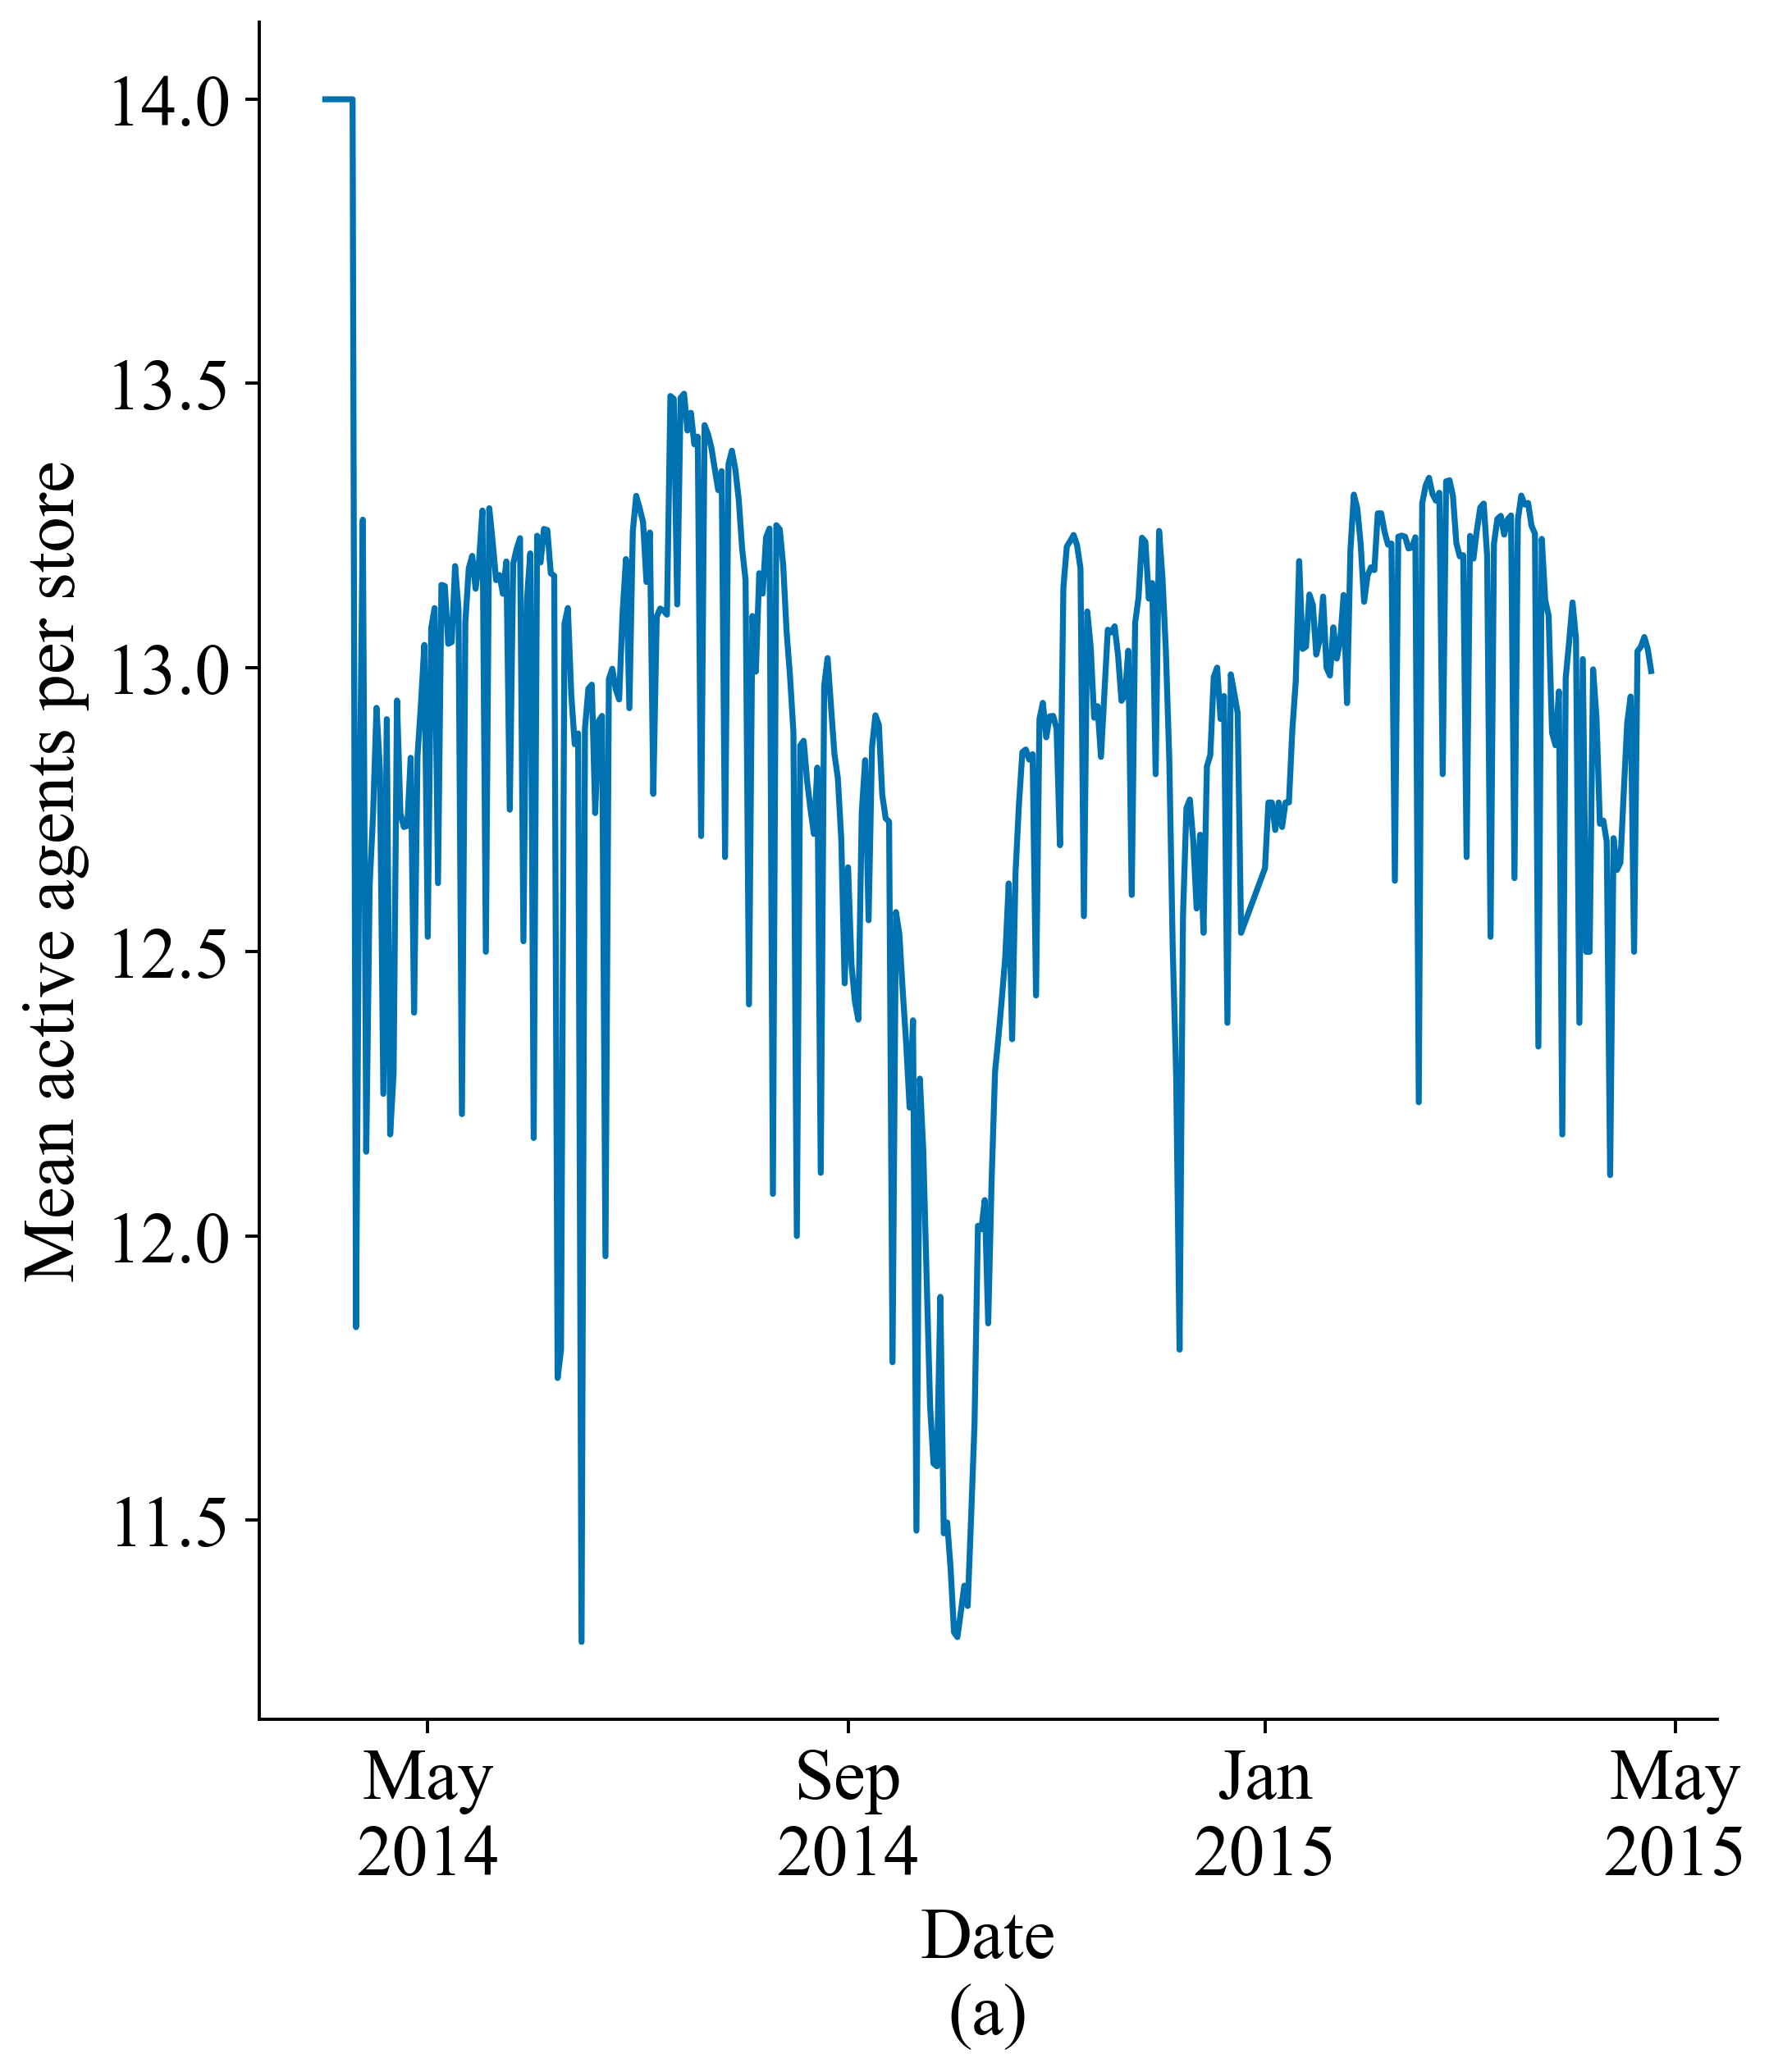

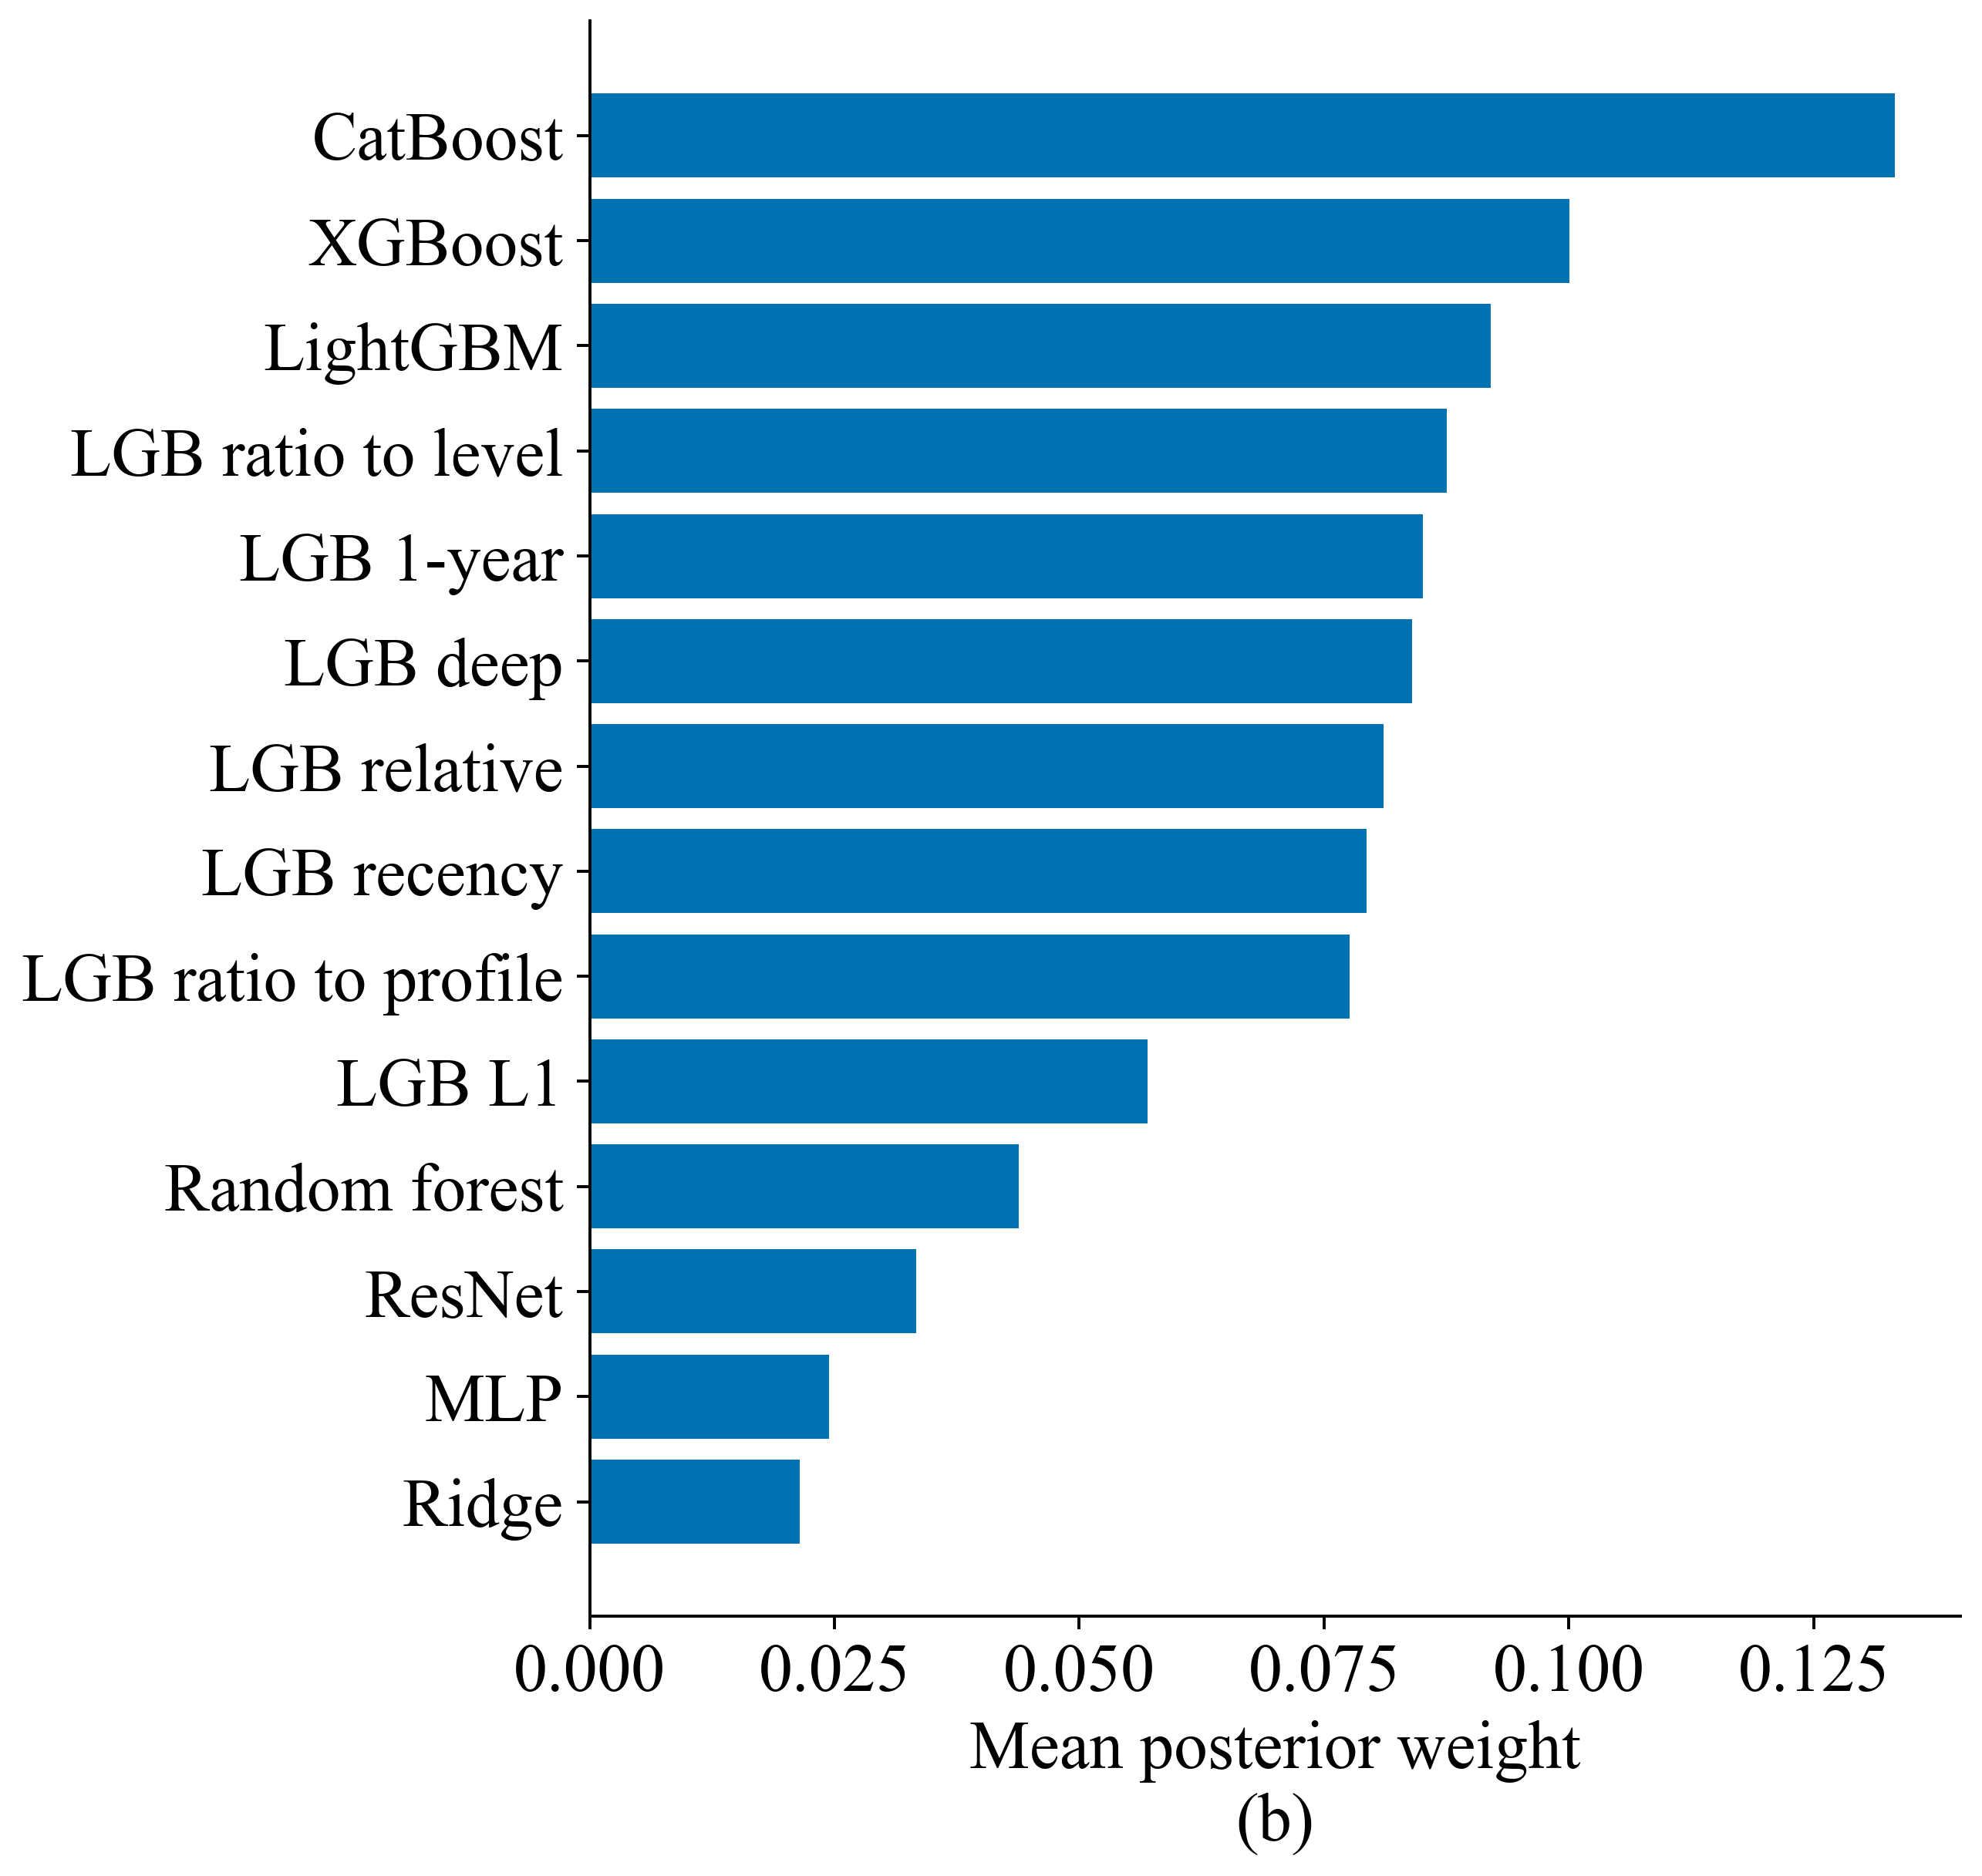

,Mean active agents,Minimum,Maximum,Store-agent deactivations,Store-agent reactivations
0,12.9828,8,14,78872,77863


In [9]:
dts = stream["Date"]; active = abma_tr["ACT"].sum(1)
daily = pd.DataFrame({"Date": dts, "active": active}).groupby("Date")["active"].agg(["mean", "min", "max"])
monthly_w = pd.DataFrame(abma_tr["W"], columns=AGENTS).groupby(dts.dt.to_period("M").astype(str).values).mean()
act_share = pd.DataFrame(abma_tr["ACT"], columns=AGENTS).mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 7.6))  # agent labels in panel (b); the canvas is wider than 13 in and is exported as panels (a) and (b)
axes[0].plot(daily.index, daily["mean"], color=PALETTE[0]); axes[0].set(xlabel="Date", ylabel="Mean active agents per store"); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
order_w = monthly_w.mean().sort_values().index
axes[1].barh(range(len(order_w)), monthly_w[order_w].mean(), color=PALETTE[0]); axes[1].set_yticks(range(len(order_w)), order_w); axes[1].set(xlabel="Mean posterior weight")
label_panels(axes); fig.tight_layout(); save_fig(fig, "fig5_1_population_and_weights"); show_fig("fig5_1_population_and_weights")
on = abma_tr["ACT"]; store_id = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]; flips_off = flips_on = 0
frame = pd.DataFrame(on, columns=AGENTS); frame["s"] = store_id
for a in AGENTS:
    diff = frame.groupby("s")[a].apply(lambda v: np.diff(v.to_numpy().astype(int)))
    d = np.concatenate(diff.to_list()); flips_off += int((d == -1).sum()); flips_on += int((d == 1).sum())
dyn = pd.DataFrame([{"Mean active agents": active.mean(), "Minimum": active.min(), "Maximum": active.max(), "Store-agent deactivations": flips_off, "Store-agent reactivations": flips_on}])
display(save_table(dyn, "tab5_7_population_dynamics", "Dynamic population across the development stream (agent activity is store-specific).", index=False, float_format="%.2f"))
GATE_FIRED = flips_off > 0 and flips_on > 0

## 6. Stress test: a real agent develops a fault and later recovers

From 15 October to 11 November 2014 the LightGBM forecast is multiplied by 1.4 for a random third of the stores.

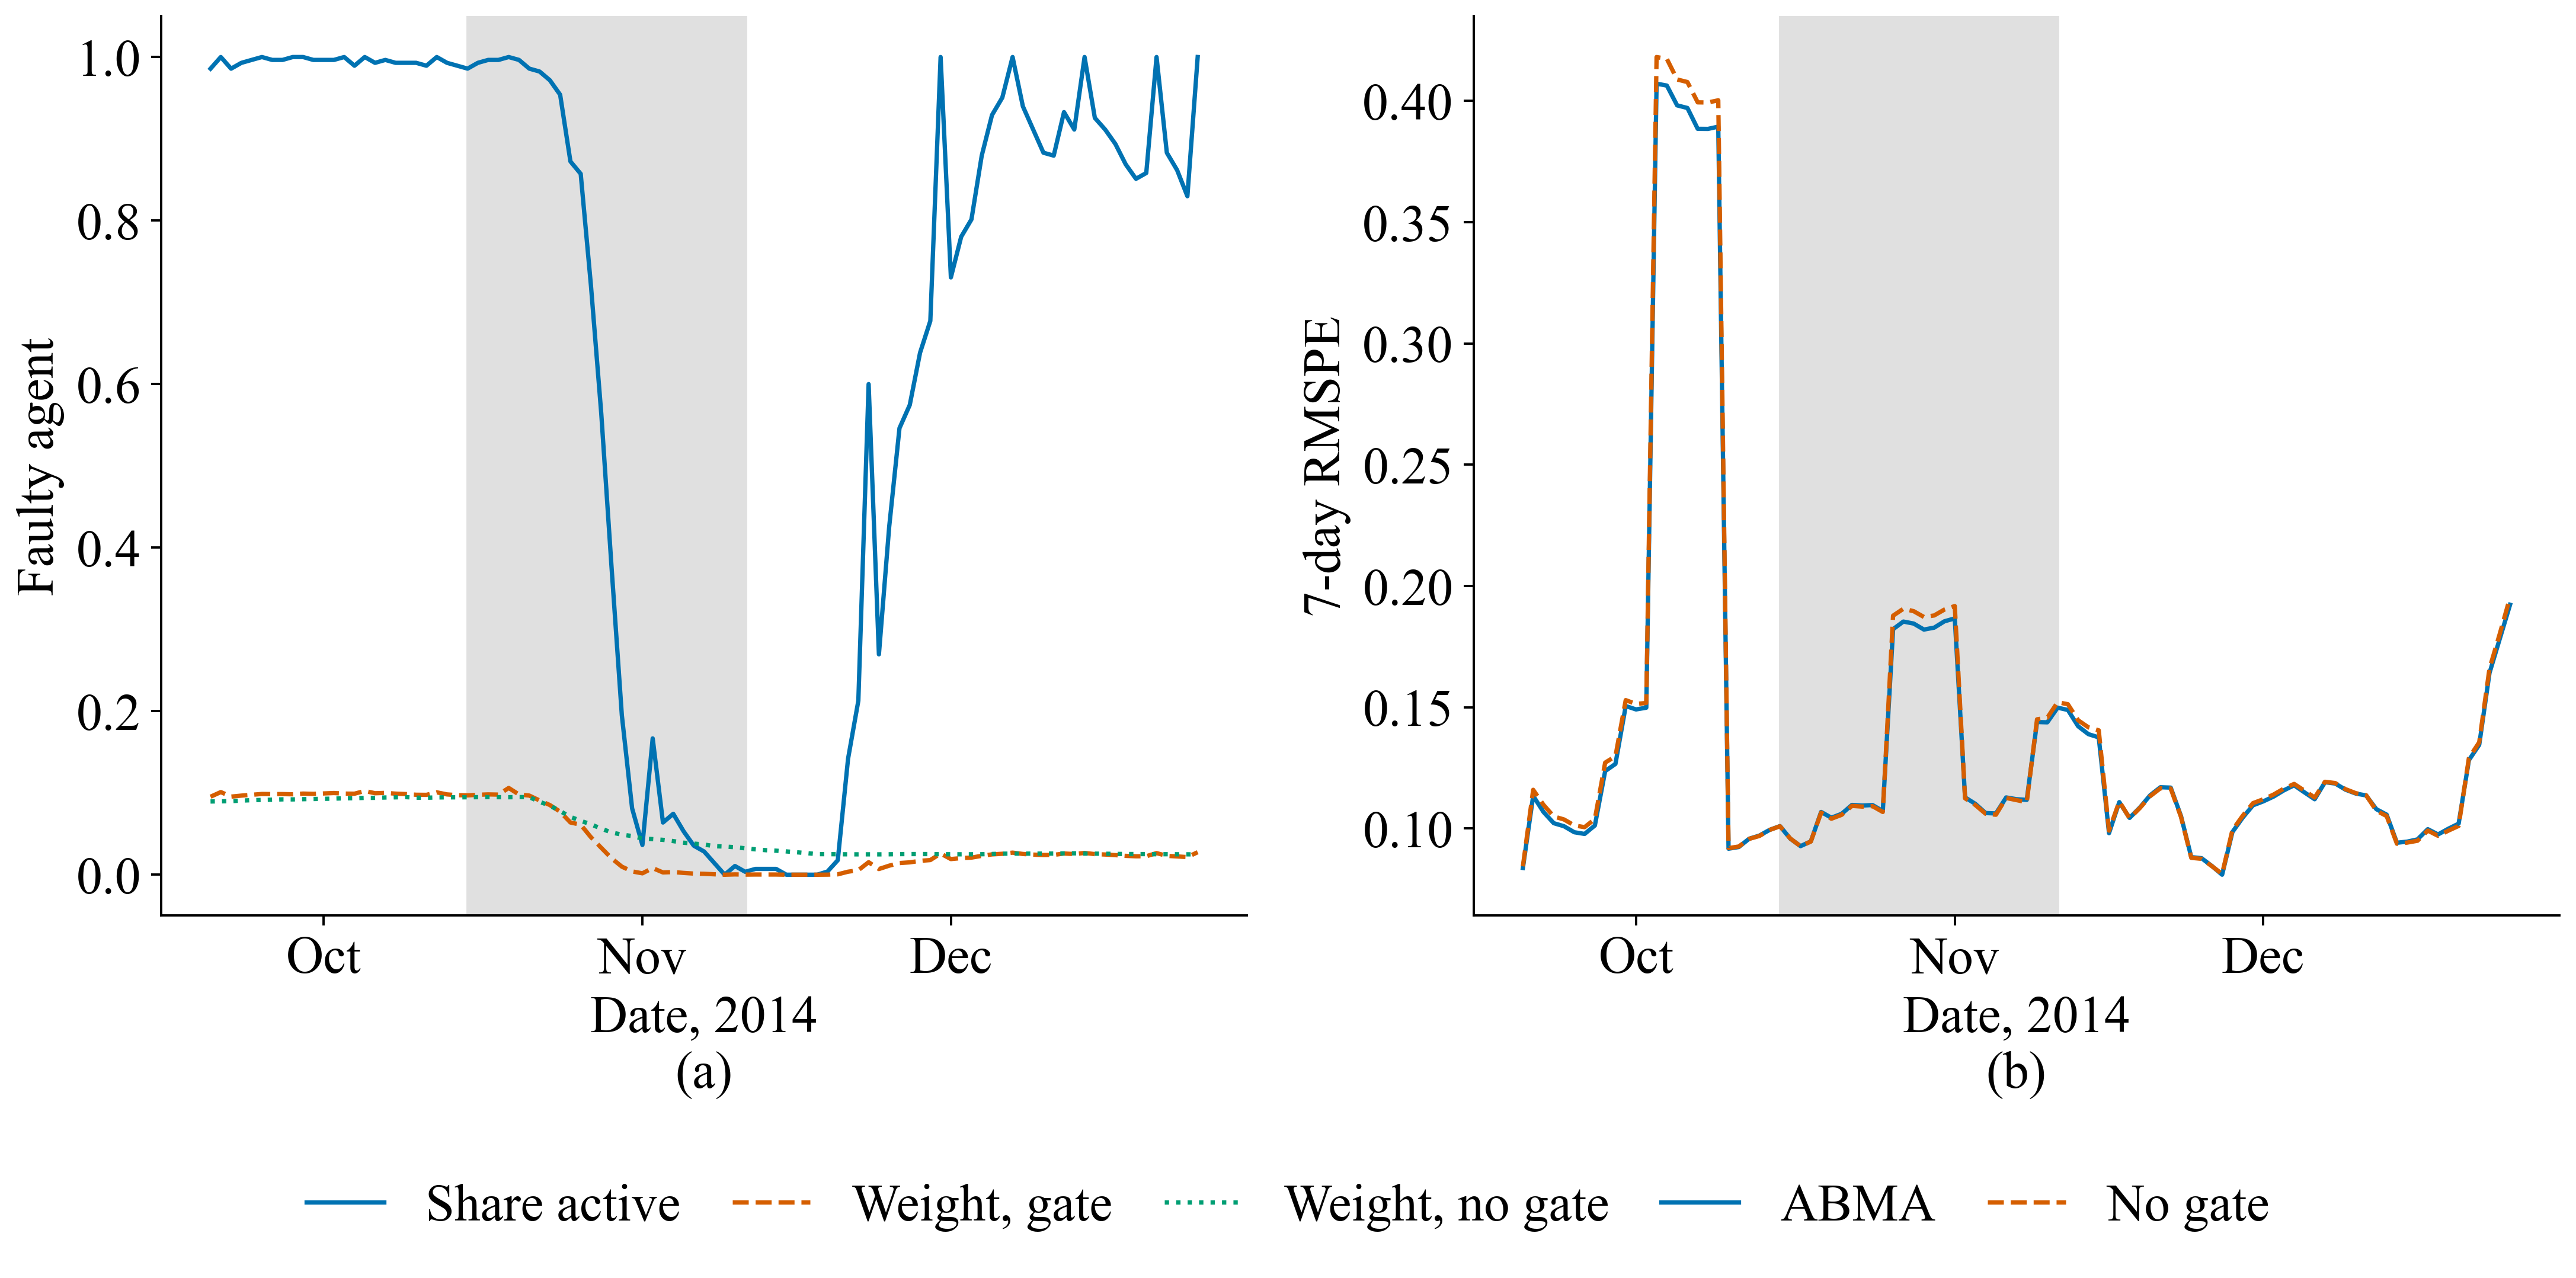

,Rows in fault window,"RMSPE, with gate","RMSPE, no gate",Active share before,"Active share, last fault week","Active share, December"
0,8313,0.0990,0.0986,0.9949,0.0208,0.8965


In [10]:
g_on, tr_on = abma_run(stream, fault, ABMA_CFG); g_off, tr_off = abma_run(stream, fault, {**ABMA_CFG, "gate_on": False, "kappa": 0.0})
in_hit = stream["Store"].isin(hit).to_numpy(); dd = pd.DataFrame({"Date": stream["Date"], "hit": in_hit, "active": tr_on["ACT"][:, kL], "w_on": tr_on["W"][:, kL], "w_off": tr_off["W"][:, kL], "e_on": ((g_on - y) / y) ** 2, "e_off": ((g_off - y) / y) ** 2})
day = dd[dd["hit"]].groupby("Date").agg(active=("active", "mean"), w_on=("w_on", "mean"), w_off=("w_off", "mean"), e_on=("e_on", "mean"), e_off=("e_off", "mean")); day = day[(day.index >= "2014-09-20") & (day.index <= "2014-12-25")]
fig, axes = plt.subplots(1, 2, figsize=(12.8, 6.4))  # one canvas (<= 13 in) so the shared legend stays below both panels
axes[0].plot(day.index, day["active"], color=PALETTE[0], label="Share active"); axes[0].plot(day.index, day["w_on"], color=PALETTE[3], ls="--", label="Weight, gate"); axes[0].plot(day.index, day["w_off"], color=PALETTE[2], ls=":", label="Weight, no gate"); axes[0].set(xlabel="Date, 2014", ylabel="Faulty agent")
r7 = day[["e_on", "e_off"]].rolling(7, min_periods=1).mean() ** 0.5
axes[1].plot(day.index, r7["e_on"], color=PALETTE[0], label="ABMA"); axes[1].plot(day.index, r7["e_off"], color=PALETTE[3], ls="--", label="No gate"); axes[1].set(xlabel="Date, 2014", ylabel="7-day RMSPE")
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.axvspan(pd.Timestamp("2014-10-15"), pd.Timestamp("2014-11-11"), color="0.88", zorder=0)
h0, l0 = axes[0].get_legend_handles_labels(); h1, l1 = axes[1].get_legend_handles_labels()
label_panels(axes); fig.legend(h0 + h1, l0 + l1, loc="lower center", ncol=5, frameon=False, columnspacing=1.0, handlelength=1.5); fig.tight_layout(rect=[0, 0.10, 1, 1]); save_fig(fig, "fig5_2_fault_response"); show_fig("fig5_2_fault_response")
fw = (stream["Date"] >= "2014-10-15") & (stream["Date"] <= "2014-11-18"); u = (fw & stream["Store"].isin(hit)).to_numpy()
stress = pd.DataFrame([{"Rows in fault window": int(u.sum()), "RMSPE, with gate": rmspe(y[u], g_on[u]), "RMSPE, no gate": rmspe(y[u], g_off[u]), "Active share before": day.loc[:"2014-10-14", "active"].mean(), "Active share, last fault week": day.loc["2014-11-05":"2014-11-11", "active"].mean(), "Active share, December": day.loc["2014-12-01":, "active"].mean()}])
display(save_table(stress, "tab5_8_stress", "Injected fault on LightGBM forecasts for a random third of stores: effect of the gate on RMSPE and the activity of the faulty agent.", index=False))

## 7. Sensitivity and predictive intervals

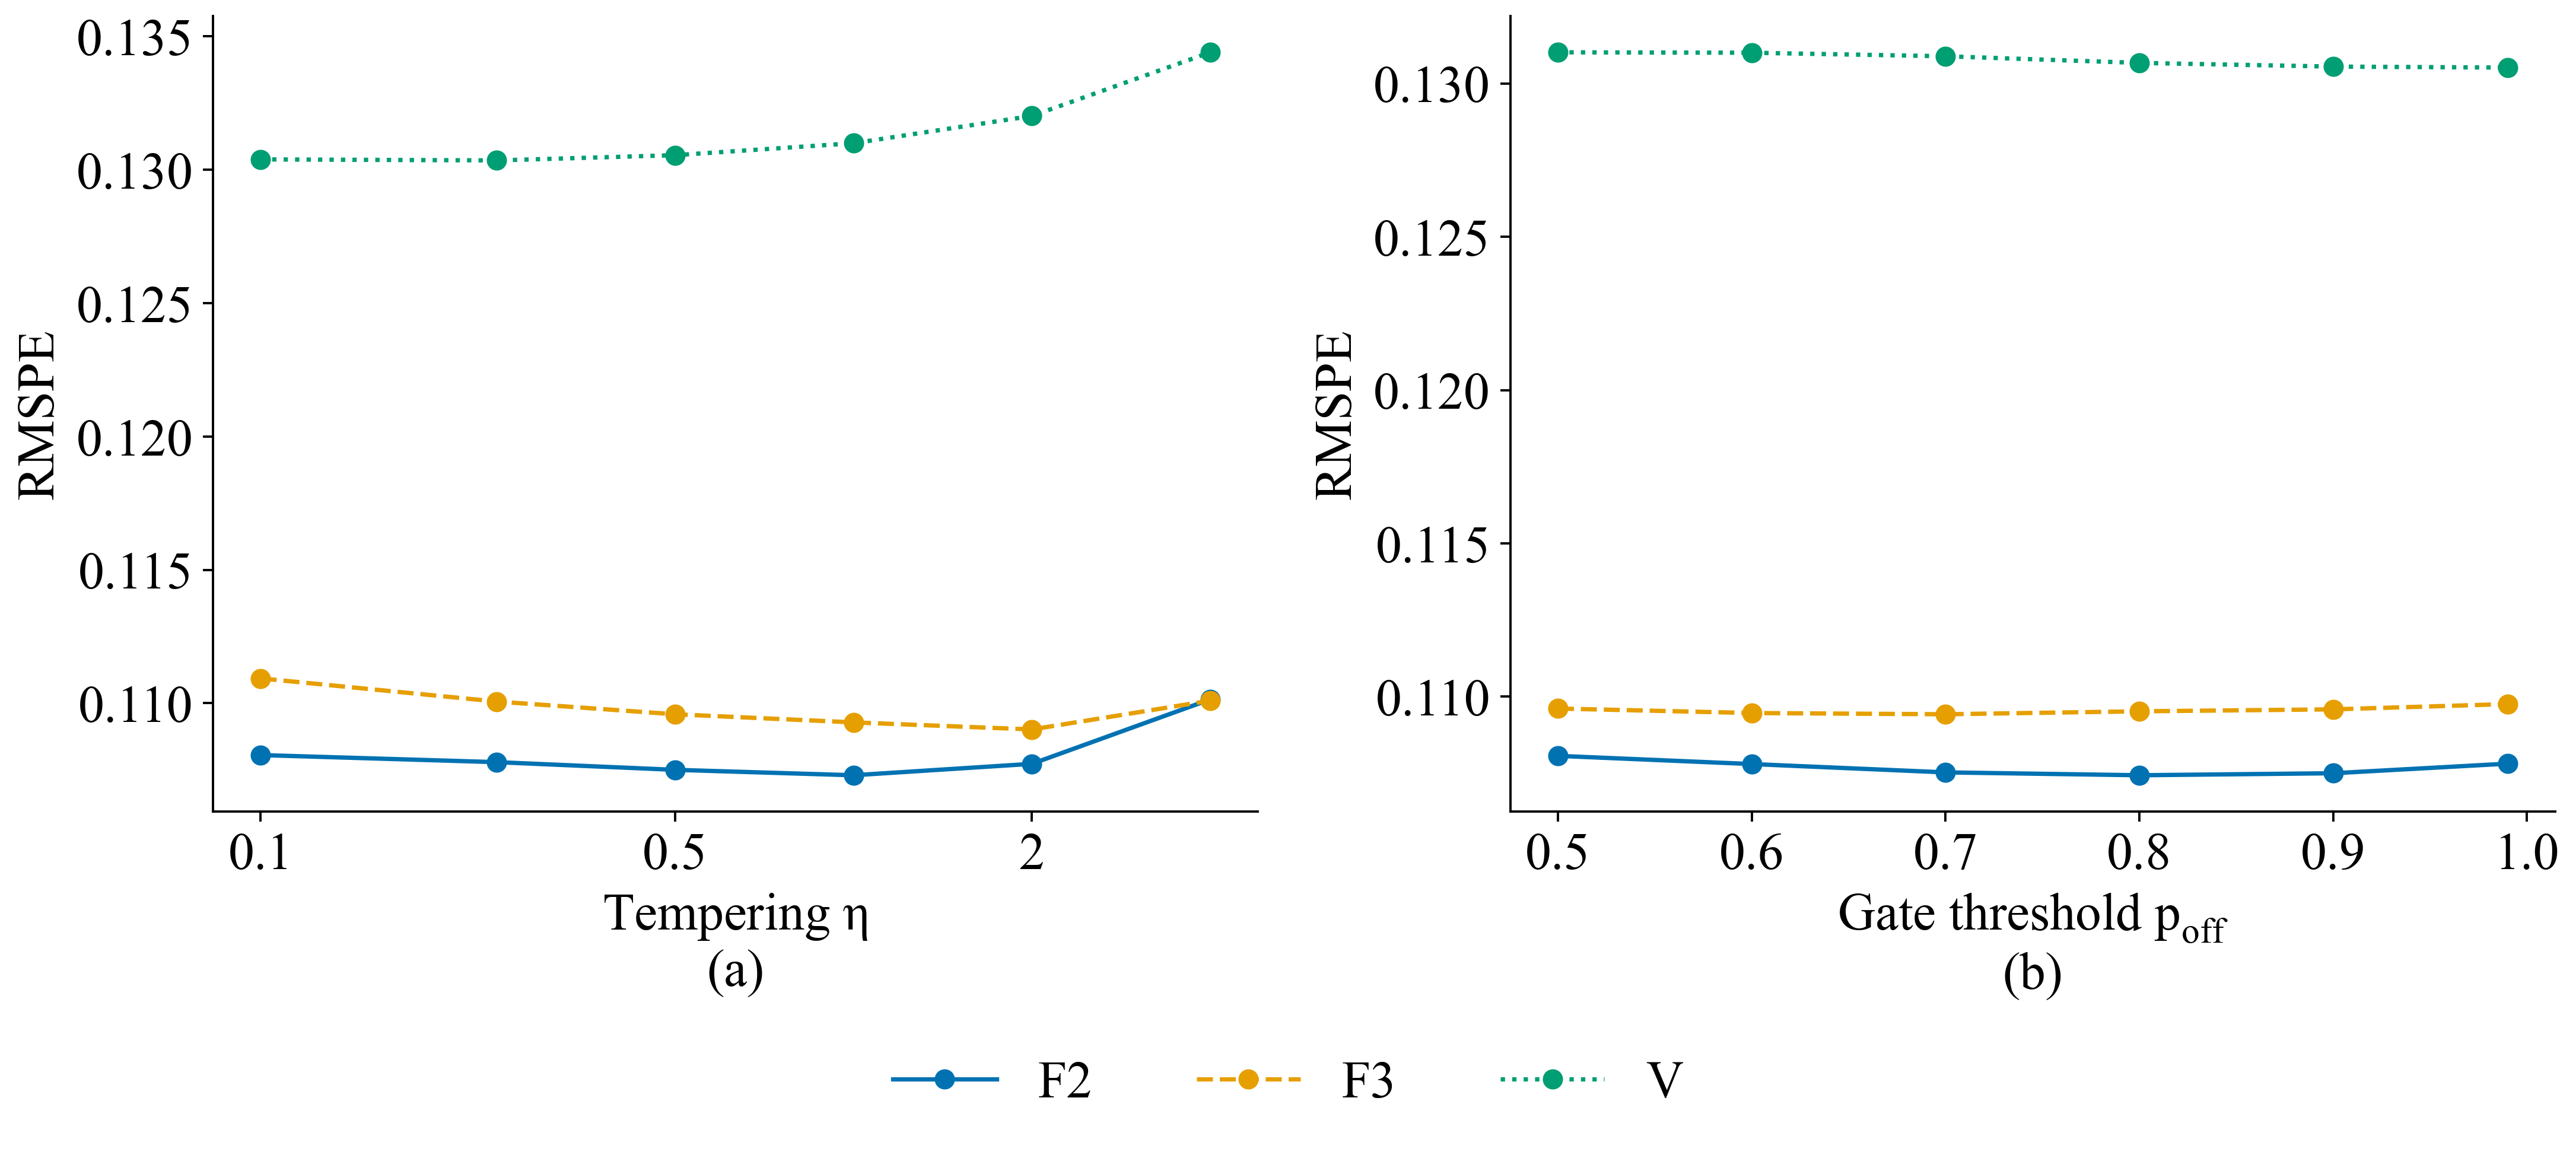

Approximation check: pooled variance in the action gives mean RMSPE 0.11588 against 0.11588


,Block,Interval,Scale,PICP90,MPIW90,MPIW90_rel
0,F2,raw mixture,1.0000,0.9238,"2,484.4848",0.3686
1,F2,scale from earlier blocks,0.9500,0.9119,"2,372.4234",0.3520
2,F3,raw mixture,1.0000,0.9034,"2,558.6353",0.3377
3,F3,scale from earlier blocks,0.9500,0.8899,"2,448.1687",0.3230
4,V,raw mixture,1.0000,0.9074,"2,491.4437",0.3718
5,V,scale from earlier blocks,0.9500,0.8945,"2,378.9493",0.3550


In [11]:
sens = []
for key, values in {"eta": [0.1, 0.25, 0.5, 1.0, 2.0, 4.0], "gate_p": [0.5, 0.6, 0.7, 0.8, 0.9, 0.99]}.items():
    for v in values: sens.append({"parameter": key, "value": v, **block_scores(abma_run(stream, P, {**ABMA_CFG, key: v})[0])})
sens = pd.DataFrame(sens)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.8))
for ax, key, xl in zip(axes, ["eta", "gate_p"], ["Tempering $\\eta$", "Gate threshold $p_{off}$"]):
    s = sens[sens.parameter == key]
    for b, col, ls in zip(SCORED, PALETTE, ["-", "--", ":"]): ax.plot(s["value"], s[b], color=col, ls=ls, marker="o", label=b)
    ax.set(xlabel=xl, ylabel="RMSPE")
axes[0].set_xscale("log"); axes[0].set_xticks([0.1, 0.5, 2.0], ["0.1", "0.5", "2"]); axes[0].minorticks_off()
h, l = axes[0].get_legend_handles_labels(); label_panels(axes); fig.legend(h, l, loc="lower center", ncol=3, frameon=False); fig.tight_layout(rect=[0, 0.09, 1, 1]); save_fig(fig, "fig5_3_sensitivity"); show_fig("fig5_3_sensitivity")
approx = block_scores(abma_run(stream, P, {**ABMA_CFG, "dispersion": False})[0]); print("Approximation check: pooled variance in the action gives mean RMSPE", round(approx["mean"], 5), "against", round(block_scores(abma_out)["mean"], 5))
def calibrated_scale(mk, target=0.90):
    """Variance scale of the mixture chosen on earlier blocks only, so that its central interval covers the target share."""
    grid = np.linspace(0.5, 1.2, 15); cov = []
    for g in grid:
        l = mixture_quantile(abma_tr["W"][mk], abma_tr["MU"][mk], g * abma_tr["SG"][mk], 0.05, 25); h = mixture_quantile(abma_tr["W"][mk], abma_tr["MU"][mk], g * abma_tr["SG"][mk], 0.95, 25); cov.append(((y[mk] >= l) & (y[mk] <= h)).mean())
    return float(grid[np.argmin(np.abs(np.array(cov) - target))])
pis = []; order = ["F1", "F2", "F3", "V"]
for i in range(1, 4):
    hist = np.logical_or.reduce([mask[b] for b in order[:i]]); now = mask[order[i]]; g = calibrated_scale(hist)
    for lab, sc in [("raw mixture", 1.0), ("scale from earlier blocks", g)]:
        lo_, hi_ = mixture_quantile(abma_tr["W"][now], abma_tr["MU"][now], sc * abma_tr["SG"][now], 0.05), mixture_quantile(abma_tr["W"][now], abma_tr["MU"][now], sc * abma_tr["SG"][now], 0.95)
        pis.append({"Block": order[i], "Interval": lab, "Scale": sc, **interval_metrics(y[now], lo_, hi_)})
display(save_table(pd.DataFrame(pis), "tab5_9_intervals", "Coverage and width of 90% predictive intervals on the scored blocks; the calibrated variant uses a variance scale chosen on earlier blocks only.", index=False))
PI_SCALE = calibrated_scale(np.logical_or.reduce([mask[b] for b in order]))

## 8. Freeze

The final configuration, the agent list with every expert configuration and the tuned control settings are written to `abma_frozen.json`, which NB06 reads.

In [12]:
COUNT_LAW = {"rule": "law = count when the target is a non-negative integer with zeros (weekly product or item panels), else lognormal; the configuration below is applied unchanged in both cases", "n_res": 257, "disc_res": 0.98, "smooth": 0.5, "interval_scale": "pi_scale multiplies the residual quantiles of the count law"}  # constants, not searched; the lognormal path of the engine is unchanged
frozen = {"model": "ABMA", "abma": ABMA_CFG, "agents": AGENTS, "experts": EXPERTS, "expert_cfg": EXPERT_CFG, "prior_experiment": PRIOR_EXPERIMENT, "views": VIEW, "lgb_cfg": lgb_cfg, "dma": DMA_CFG, "nnls": NN_CFG, "stack": STACK_CFG, "fixed_share": FS_CFG, "dwm": DWM_CFG, "drift_nnls": PH_CFG, "corrected": CORR, "pi_scale": PI_SCALE, "top3": TOP3, "best_single": single_rank, "n_features": len(FEATURES), "gate_fired_in_development": bool(GATE_FIRED), "pruned": PRUNED, "net_inputs": NET_INPUTS, "net_epochs": NET_EPOCHS, "count_law": COUNT_LAW, "protected_components": list(PROTECTED), "component_rule_met": bool(component_rule.loc[component_rule["Kind"] == "protected", "Significantly worse without it"].all())}
(CONFIGS / "abma_frozen.json").write_text(json.dumps(frozen, indent=2, default=str))
stream[["row_id", "Store", "Date", "Sales", "ctx", "block"]].assign(**{k: v for k, v in fc.items() if not k.startswith("A:")}).to_parquet(RUNS / "NB05_development_forecasts.parquet", index=False)
print("Frozen:", frozen["abma"], "| agents", len(AGENTS), "| pruned:", list(PRUNED) or "none", "| component rule met:", frozen["component_rule_met"])

Frozen: {'eta': 0.5, 'disc_w': 0.99, 'disc_var': 0.995, 'gate_loss': 'relative', 'sig_scale': 0.9, 'theta0': 0.5, 'gate_p': 0.9, 'disc_beta': 0.9, 'kappa': 0.0} | agents 14 | pruned: none | component rule met: True


# Part B · UCI Sales Transactions Weekly

## The frozen adaptive Bayesian multi-agent model with the count law on the development weeks

The online state starts flat at W20, warms up on W20–W23 and is scored on F2 (W24–W26) and D (W28–W38); labels of week t enter at t + 2.

In [1]:
# NB05_SETUP: inputs, packages and helpers (same conventions as NB01-NB04 of this panel)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci'
for _d in ('Artifacts','Manifests','Configs'):(BASE/_d).mkdir(parents=True,exist_ok=True)
RUN_ID='NB05_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text());NM=json.loads((BASE/'Manifests/network_manifest.json').read_text())
NB03_OUT=BASE/'Artifacts'/BM['run_id'];NB04_OUT=BASE/'Artifacts'/NM['run_id']
FROZEN=json.loads((ROOT/'outputs'/'configs'/'abma_frozen.json').read_text());assert FROZEN['model']=='ABMA' and 'count_law' in FROZEN,'The freeze must carry the count-law constants'
import lightgbm as lgb
from scipy.optimize import nnls

### 1. Agents: twelve forecasters read from their runs

In [2]:
# NB05_AGENTS
NB03_MODELS=BM['model_order'];NB04_MODELS=NM['model_order'];AGENTS=NB03_MODELS+NB04_MODELS;NET_NAMES=list(NB04_MODELS)
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet',columns=['row_id','Product_Code','week','quantity','history_zero']).sort_values(['week','Product_Code']).reset_index(drop=True)
nested=pd.concat([pd.read_parquet(NB03_OUT/'nested_oof.parquet'),pd.read_parquet(NB04_OUT/'nested_oof.parquet')],ignore_index=True);nested_wide=nested.pivot(index='row_id',columns='model',values='prediction')[AGENTS]
dev_rows=pd.read_parquet(NB03_OUT/'development_rows.parquet');assert dev_rows.row_id.tolist()==pd.read_parquet(NB04_OUT/'development_rows.parquet').row_id.tolist()
d3,d4=np.load(NB03_OUT/'development_predictions.npz'),np.load(NB04_OUT/'development_predictions.npz');dev_wide=pd.DataFrame({m:d3[f'{NB03_MODELS.index(m)}_{SEED}'] for m in NB03_MODELS}|{m:d4[f'{NB04_MODELS.index(m)}_{SEED}'] for m in NB04_MODELS},index=dev_rows.row_id)
stream=rows[rows.week.between(20,26)|rows.week.between(28,38)].copy().reset_index(drop=True);agents=pd.concat([nested_wide,dev_wide]).reindex(stream.row_id).astype(float);assert agents.notna().all().all() and (agents>=0).all().all()
BLOCKS={'W':(20,23),'F2':(24,26),'D':(28,38)};SCORED=['F2','D'];stream['block']=np.select([stream.week.between(*b) for b in BLOCKS.values()],list(BLOCKS),default='gap');assert (stream.block!='gap').all()
stream['Store']=stream.Product_Code;stream['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*stream.week,'D');stream['Sales']=stream.quantity.astype(float);stream['ctx']=0
y=stream.quantity.to_numpy(float);Pq=agents.to_numpy(float);wk=stream.week.to_numpy();pos=y>0;mask={b:(stream.block==b).to_numpy() for b in BLOCKS};scored=mask['F2']|mask['D']
def block_scores(p):r={b:rmspe(y[mask[b]],p[mask[b]]) for b in BLOCKS};r['Pooled (F2+D)']=rmspe(y[scored],p[scored]);r['mean']=float(np.mean([r[b] for b in SCORED]));return r
def board_row(p):m=metrics(y[scored],p[scored]);return {'RMSPE W (warm-up)':block_scores(p)['W'],'RMSPE F2':block_scores(p)['F2'],'RMSPE D':block_scores(p)['D'],'Pooled RMSPE':m['RMSPE'],'RMSE':m['RMSE'],'MAE':m['MAE'],'Zero MAE':m['Zero_MAE']}
agent_tab=pd.DataFrame({a:board_row(Pq[:,i]) for i,a in enumerate(AGENTS)}).T.sort_values('Pooled RMSPE').rename_axis('Agent').reset_index();table(agent_tab,'agents_development',['Pooled RMSPE','RMSE','MAE','Zero MAE'])
table(pd.DataFrame([{'Block':b,'Weeks':f'W{v[0]}–W{v[1]}','Rows':int(mask[b].sum()),'Positive targets':int((y[mask[b]]>0).sum()),'Role':'warm-up (not scored)' if b=='W' else 'scored'} for b,v in BLOCKS.items()]),'development_blocks')
print(f'Stream {len(stream):,} rows, {stream.Store.nunique():,} products, {stream.Date.nunique()} weeks, {len(AGENTS)} agents; zero share of scored targets {np.mean(y[scored]==0):.3f}')

,Agent,RMSPE W (warm-up),RMSPE F2,RMSPE D,Pooled RMSPE,RMSE,MAE,Zero MAE
0,Positive-history action,0.474038,0.546349,0.499030,0.51010,3.82954,2.43071,1.03477
1,CatBoost,0.539747,0.605116,0.493642,0.52091,4.59542,2.67668,0.36332
2,XGBoost,0.559886,0.647755,0.509835,0.54405,4.26171,2.53397,0.38850
3,LightGBM,0.559150,0.642700,0.530551,0.55785,4.33654,2.52141,0.39612
4,ResNet,0.533634,0.578557,0.578133,0.57823,6.01377,3.22653,0.39468
5,Croston-SBA,0.580372,0.714313,0.567821,0.60402,5.51859,3.11601,0.32427
6,Random forest,0.654399,0.781464,0.762860,0.76710,3.82194,2.27331,0.50819
7,Historical mean,0.682329,0.787586,0.847280,0.83417,4.28820,2.54126,0.36960
8,MLP,0.645689,0.584059,0.967467,0.89535,4.60264,2.75756,0.60420
9,Lag 2,0.832682,1.150734,0.879251,0.94739,4.67122,2.73271,0.39496


,Block,Weeks,Rows,Positive targets,Role
0,W,W20–W23,2916,2084,warm-up (not scored)
1,F2,W24–W26,2187,1633,scored
2,D,W28–W38,8019,5598,scored


Stream 13,122 rows, 729 products, 18 weeks, 12 agents; zero share of scored targets 0.291


### 2. The count law

For agent $k$ the scaled residual $r=(y-p_k)/\sqrt{p_k+1}$ feeds a discounted chain-wide reservoir (257 weighted quantiles, discount 0.98) and the predictive law of $y$ is $\max(0,\mathrm{round}(p_k+\sqrt{p_k+1}\,r))$.

In [3]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [4]:
# NB05_FROZEN
CL=FROZEN['count_law'];ABMA_CFG={**FROZEN['abma'],'lag':14,'nctx':1,'law':'count','n_res':CL['n_res'],'disc_res':CL['disc_res'],'smooth':CL['smooth']}
def run(cfg,Pm=None,st=None):return abma_run(stream if st is None else st,Pq if Pm is None else Pm,cfg)[0]
table(pd.DataFrame([{'Setting':k,'Frozen value':v} for k,v in FROZEN['abma'].items()]+[{'Setting':'law','Frozen value':'count (rule: '+CL['rule'][:60]+'…)'},{'Setting':'n_res / disc_res / smooth','Frozen value':f"{CL['n_res']} / {CL['disc_res']} / {CL['smooth']}"},{'Setting':'lag (days) / nctx','Frozen value':'14 / 1'},{'Setting':'pi_scale','Frozen value':FROZEN['pi_scale']}]),'frozen_configuration')

,Setting,Frozen value
0,eta,0.50000
1,disc_w,0.99000
2,disc_var,0.99500
3,gate_loss,relative
4,sig_scale,0.90000
5,theta0,0.50000
6,gate_p,0.90000
7,disc_beta,0.90000
8,kappa,0.00000
9,law,count (rule: law = count when the target is a non-negative integer with z…)


### 3. Frozen model on the development weeks

In [5]:
# NB05_DEVELOPMENT
base_out,base_tr=abma_run(stream,Pq,ABMA_CFG)
abma_out,abma_tr=base_out,base_tr;fc={'ABMA':abma_out};print('Frozen ABMA (count law) on development:',{k:round(v,5) for k,v in block_scores(fc['ABMA']).items()})

Frozen ABMA (count law) on development: {'W': 0.52558, 'F2': 0.52995, 'D': 0.44807, 'Pooled (F2+D)': 0.46782, 'mean': 0.48901}


### 4. Controls tuned with the main-chain budget on the scored blocks

Rolling NNLS, nonlinear stacking and dynamic model averaging receive 40 configurations and the streaming controls use the fixed grids of Part A, all under the criterion mean RMSPE over F2 and D.

In [6]:
# NB05_CONTROLS
def hist_mask(block):return (stream.week<=BLOCKS[block][0]-2).to_numpy()
def relative_correct(p):
    out=p.copy()
    for b in SCORED:h=hist_mask(b)&pos;now=mask[b];r=p[h]/y[h];out[now]=p[now]*(r.sum()/max((r**2).sum(),1e-12))
    return out
def better(name,raw,record=None):
    cand={False:raw,True:relative_correct(raw)};flag=min(cand,key=lambda f:block_scores(cand[f])['mean'])
    if record is not None:record[name]=bool(flag)
    return cand[flag],bool(flag)
weeks_all=np.sort(stream.week.unique());NO_NETS=[i for i,a in enumerate(AGENTS) if a not in NET_NAMES]
rel=np.where(pos[:,None],Pq/np.where(pos,y,1.0)[:,None],0.0);grams={w:(rel[(wk==w)&pos].T@rel[(wk==w)&pos],rel[(wk==w)&pos].sum(0)) for w in weeks_all}
def rolling_nnls(window,lam,pool='all',reset_week=None):
    idx=list(range(len(AGENTS))) if pool=='all' else NO_NETS;K=len(idx);out=np.zeros(len(y))
    for w in weeks_all:
        hw=[v for v in weeks_all if v<=w-2 and (window is None or v>w-2-window) and (reset_week is None or v>=reset_week.get(w,0))];now=wk==w
        if len(hw)<2:out[now]=Pq[now][:,idx].mean(1);continue
        G=sum(grams[v][0][np.ix_(idx,idx)] for v in hw)+lam*np.eye(K);h=sum(grams[v][1][idx] for v in hw);L=np.linalg.cholesky(G);beta=nnls(L.T,np.linalg.solve(L,h),maxiter=200)[0];out[now]=Pq[now][:,idx]@beta if beta.sum()>0 else Pq[now][:,idx].mean(1)
    return out
nn_trials=[]
for c in [dict(window=w,lam=l,pool=b) for w in (4,8,12,None) for l in (1.0,10.0,100.0,1000.0,10000.0) for b in ('all','no_nets')]:
    raw=rolling_nnls(c['window'],c['lam'],c['pool'])
    for flag,p in [(False,raw),(True,relative_correct(raw))]:nn_trials.append({**c,'corrected':flag,**block_scores(p)})
nn_trials=pd.DataFrame(nn_trials).sort_values('mean').reset_index(drop=True);NN_CFG=dict(window=None if pd.isna(nn_trials.loc[0,'window']) else int(nn_trials.loc[0,'window']),lam=float(nn_trials.loc[0,'lam']),pool=str(nn_trials.loc[0,'pool']));NN_CORR=bool(nn_trials.loc[0,'corrected'])
def drift_nnls_weekly(window,lam,pool,delta,lam_ph):
    idx=list(range(len(AGENTS))) if pool=='all' else NO_NETS;out=np.zeros(len(y));last_reset=0;checked=set();x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
    for w in weeks_all:
        for v in [v for v in weeks_all if v<=w-2 and v not in checked]:
            checked.add(v);r=(wk==v)&pos;x=float((((out[r]-y[r])/y[r])**2).mean()) if r.any() else 0.0;x_n+=1;x_sum+=x;m_sum+=x-x_sum/x_n-delta;m_min=min(m_min,m_sum)
            if m_sum-m_min>lam_ph:last_reset=v+1;x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
        out[wk==w]=rolling_nnls(window,lam,pool,reset_week={w:last_reset})[wk==w]
    return out
ph_trials=[]
for c in [dict(delta=d_,lam_ph=l_) for d_ in (0.001,0.005,0.01) for l_ in (0.02,0.05,0.1,0.2,0.5)]:
    raw=drift_nnls_weekly(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool'],**c)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:ph_trials.append({**c,'corrected':flag,**block_scores(p)})
ph_trials=pd.DataFrame(ph_trials).sort_values('mean').reset_index(drop=True);PH_CFG={'delta':float(ph_trials.loc[0,'delta']),'lam_ph':float(ph_trials.loc[0,'lam_ph'])};PH_CORR=bool(ph_trials.loc[0,'corrected'])
P1=Pq+1.0;S1=y+1.0;st1=stream.assign(Sales=S1)  # shifted scale for the log-based combiners (dynamic model averaging, fixed-share, dynamic weighted majority)
dma_trials=[]
for cfg in [dict(disc_w=a,eta=b) for a in (0.9,0.95,0.98,0.99,0.995,0.999) for b in (0.1,0.25,0.5,1.0,2.0,4.0,8.0)][:40]:
    raw=np.maximum(0.,abma_run(st1,P1,{**cfg,'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:dma_trials.append({**cfg,'corrected':flag,**block_scores(p)})
dma_trials=pd.DataFrame(dma_trials).sort_values('mean').reset_index(drop=True);DMA_CFG={k:float(dma_trials.loc[0,k]) for k in ('disc_w','eta')};DMA_CORR=bool(dma_trials.loc[0,'corrected'])
fs_trials=[]
for cfg in [dict(eta=e_,alpha=a_,scope=s_) for e_ in (1.0,3.0,10.0,30.0,100.0) for a_ in (0.0,0.01,0.05,0.2) for s_ in ('store','chain')]:
    raw=np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**cfg)-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:fs_trials.append({**cfg,'corrected':flag,**block_scores(p)})
fs_trials=pd.DataFrame(fs_trials).sort_values('mean').reset_index(drop=True);FS_CFG={'eta':float(fs_trials.loc[0,'eta']),'alpha':float(fs_trials.loc[0,'alpha']),'scope':str(fs_trials.loc[0,'scope'])};FS_CORR=bool(fs_trials.loc[0,'corrected'])
dwm_trials=[]
for cfg in [dict(beta=b_,theta=t_,eps=e_,period=p_) for b_ in (0.5,0.7,0.9) for t_ in (0.01,0.05) for e_ in (0.05,0.1,0.2) for p_ in (1,4)]:
    raw=np.maximum(0.,dwm(st1,P1,S1,lag=14,**cfg)-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:dwm_trials.append({**cfg,'corrected':flag,**block_scores(p)})
dwm_trials=pd.DataFrame(dwm_trials).sort_values('mean').reset_index(drop=True);DWM_CFG={'beta':float(dwm_trials.loc[0,'beta']),'theta':float(dwm_trials.loc[0,'theta']),'eps':float(dwm_trials.loc[0,'eps']),'period':int(dwm_trials.loc[0,'period'])};DWM_CORR=bool(dwm_trials.loc[0,'corrected'])
Xs=pd.DataFrame(np.log1p(Pq),columns=AGENTS);Xs['dispersion']=np.log1p(Pq).std(1);Xs['history_zero']=stream.history_zero.to_numpy()
STACK_SPACE=dict(n_estimators=[100,200,300,500,800],learning_rate=[0.01,0.02,0.03,0.05],num_leaves=[7,15,31,63],min_child_samples=[50,200,500,1000],colsample_bytree=[0.5,0.7,1.0],reg_lambda=[0.0,1.0,10.0],weight=[0.0,1.0,2.0],pool=['all','no_nets'])
rng_s=np.random.default_rng(SEED)
def sample(space):return {k:v[rng_s.integers(len(v))] for k,v in space.items()}
def stack_forecast(cfg,seed=SEED):
    cfg=dict(cfg);pw=cfg.pop('weight');pool=cfg.pop('pool');use=[c for c in Xs.columns if pool=='all' or c not in NET_NAMES];out=Pq.mean(1).copy()
    for b in SCORED:
        h=hist_mask(b);now=mask[b];m=lgb.LGBMRegressor(**{k:(int(v) if k in ('n_estimators','num_leaves','min_child_samples') else float(v)) for k,v in cfg.items()},subsample=0.8,subsample_freq=1,random_state=seed,n_jobs=4,verbose=-1,deterministic=True,force_col_wise=True).fit(Xs.loc[h,use],np.log1p(y[h]),sample_weight=(1/np.maximum(y[h],1))**pw);out[now]=np.maximum(0.,np.expm1(m.predict(Xs.loc[now,use])))
    return out
st=[]
for t in range(40):
    cfg=sample(STACK_SPACE);raw=stack_forecast(cfg)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:st.append({**cfg,'corrected':flag,**block_scores(p)})
    print('stack',t,round(st[-2]['mean'],5),flush=True) if t%10==9 else None
st=pd.DataFrame(st).sort_values('mean').reset_index(drop=True);STACK_CFG={k:(str(st.loc[0,k]) if k=='pool' else float(st.loc[0,k])) for k in STACK_SPACE};STACK_CORR=bool(st.loc[0,'corrected'])
TOP3=list(pd.Series({a:rmspe(y[mask['W']],Pq[mask['W'],i]) for i,a in enumerate(AGENTS)}).sort_values().index[:3]);BEST_SINGLE=str(agent_tab.Agent.iloc[0]);i_bs=AGENTS.index(BEST_SINGLE)
control_tuning=pd.DataFrame([{'Method':'ABMA (frozen, no search)','Configurations':0,'Best mean RMSPE':block_scores(fc['ABMA'])['mean'],'Selected':'frozen'},{'Method':'Dynamic model averaging','Configurations':len(dma_trials)//2,'Best mean RMSPE':dma_trials.loc[0,'mean'],'Selected':str(DMA_CFG)+(' corrected' if DMA_CORR else '')},{'Method':'Rolling NNLS','Configurations':len(nn_trials)//2,'Best mean RMSPE':nn_trials.loc[0,'mean'],'Selected':str(NN_CFG)+(' corrected' if NN_CORR else '')},{'Method':'Nonlinear stacking','Configurations':len(st)//2,'Best mean RMSPE':st.loc[0,'mean'],'Selected':str(STACK_CFG)+(' corrected' if STACK_CORR else '')},{'Method':'Fixed-share exponential weighting','Configurations':len(fs_trials)//2,'Best mean RMSPE':fs_trials.loc[0,'mean'],'Selected':str(FS_CFG)+(' corrected' if FS_CORR else '')},{'Method':'Dynamic weighted majority','Configurations':len(dwm_trials)//2,'Best mean RMSPE':dwm_trials.loc[0,'mean'],'Selected':str(DWM_CFG)+(' corrected' if DWM_CORR else '')},{'Method':'Drift-reset NNLS (Page-Hinkley)','Configurations':len(ph_trials)//2,'Best mean RMSPE':ph_trials.loc[0,'mean'],'Selected':str(PH_CFG)+(' corrected' if PH_CORR else '')},{'Method':'Uniform average (three best of W20–W23)','Configurations':0,'Best mean RMSPE':np.nan,'Selected':', '.join(TOP3)}])
table(control_tuning,'control_tuning')
for name,df in [('nnls',nn_trials),('drift_nnls',ph_trials),('dma',dma_trials),('fixed_share',fs_trials),('dwm',dwm_trials),('stacking',st)]:df.to_csv(OUT/f'tuning_{name}.csv',index=False)

stack 9 0.88371


stack 19 1.15062


stack 29 0.66459


stack 39 0.74955


,Method,Configurations,Best mean RMSPE,Selected
0,"ABMA (frozen, no search)",0,0.48901,frozen
1,Dynamic model averaging,40,0.54453,"{'disc_w': 0.9, 'eta': 0.1} corrected"
2,Rolling NNLS,40,0.49389,"{'window': None, 'lam': 1.0, 'pool': 'all'} corrected"
3,Nonlinear stacking,40,0.56549,"{'n_estimators': 200.0, 'learning_rate': 0.02, 'num_leaves': 31.0, 'min_child_samples': 200.0, 'colsample_bytree': 1.0, 'reg_lambda': 0.0, 'weight': 2.0, 'pool': 'no_nets'}"
4,Fixed-share exponential weighting,40,0.54775,"{'eta': 3.0, 'alpha': 0.2, 'scope': 'chain'} corrected"
5,Dynamic weighted majority,36,0.55836,"{'beta': 0.9, 'theta': 0.01, 'eps': 0.05, 'period': 4} corrected"
6,Drift-reset NNLS (Page-Hinkley),15,0.49389,"{'delta': 0.01, 'lam_ph': 0.5} corrected"
7,Uniform average (three best of W20–W23),0,n/a,"Positive-history action, ResNet, CatBoost"


### 5. Ablations, controls and single agents on identical rows

Ablations remove one mechanism from the frozen configuration; paired series-cluster bootstrap (2,000 replicates) with Holm adjustment over all comparators.

In [7]:
# NB05_BOARD
def paired_to(base,others,ids,B=2000,chunk=250):
    st_id=np.unique(ids,return_inverse=True)[1];Ns=st_id.max()+1;cnt=np.bincount(st_id,minlength=Ns).astype(float);yy=y_eval;be=np.bincount(st_id,((base-yy)/yy)**2,Ns);g=np.random.default_rng(SEED);names=list(others);oes=[np.bincount(st_id,((others[n]-yy)/yy)**2,Ns) for n in names];d=np.zeros((len(names),B))
    for a in range(0,B,chunk):
        draws=g.multinomial(Ns,np.full(Ns,1/Ns),min(chunk,B-a)).astype(float);ab=np.sqrt(draws@be/(draws@cnt))
        for j,oe in enumerate(oes):d[j,a:a+len(draws)]=ab-np.sqrt(draws@oe/(draws@cnt))
    out=[{'Comparator':n,'RMSPE comparator':np.sqrt(oe.sum()/cnt.sum()),'Difference (ABMA - comparator)':np.sqrt(be.sum()/cnt.sum())-np.sqrt(oe.sum()/cnt.sum()),'CI low':np.quantile(d[j],0.025),'CI high':np.quantile(d[j],0.975),'p':min(1.0,2*min((d[j]>=0).mean(),(d[j]<=0).mean())+2/B)} for j,(n,oe) in enumerate(zip(names,oes))]
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True);m=len(r);r['Holm p']=np.minimum(1,np.maximum.accumulate(r['p']*(m-np.arange(m))));return r.sort_values('RMSPE comparator').reset_index(drop=True)
ev=scored&pos;y_eval=y[ev];ids_eval=stream.Store.to_numpy()[ev]
PROTECTED={'No Bayes action (posterior mean of log forecast)':{'action':'median'},'Uniform weights over active agents':{'weight_mode':'uniform'},'No persistent gate':{'gate_on':False},'No reactivation':{'reactivate':False}}
ABL=dict(PROTECTED);ABL['Added instantaneous gate (kappa 2.5)']={'kappa':2.5};ABL['Added product bias tracker']={'bias_mode':'agent'}  # the product-level variance ablation is not applicable under the count law: the variance state enters neither the count-law weights nor the action
for n,c in ABL.items():fc['A: '+n]=run({**ABMA_CFG,**c})
fc[f'A: Single agent ({BEST_SINGLE}) with count-law action']=run({**ABMA_CFG,'gate_on':False},Pm=Pq[:,[i_bs]*3])
CORR={};fc['C: Best single agent'],_=better('C: Best single agent',Pq[:,i_bs],CORR);fc['C: Uniform average (all agents)'],_=better('C: Uniform average (all agents)',Pq.mean(1),CORR);fc['C: Uniform average (three best agents)'],_=better('C: Uniform average (three best agents)',Pq[:,[AGENTS.index(a) for a in TOP3]].mean(1),CORR);fc['C: Three boosters average'],_=better('C: Three boosters average',Pq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1),CORR)
raw=rolling_nnls(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool']);fc['C: Rolling NNLS']=relative_correct(raw) if NN_CORR else raw;CORR['C: Rolling NNLS']=NN_CORR
raw=stack_forecast(STACK_CFG);fc['C: Nonlinear stacking']=relative_correct(raw) if STACK_CORR else raw;CORR['C: Nonlinear stacking']=STACK_CORR
raw=np.maximum(0.,abma_run(st1,P1,{**DMA_CFG,'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0);fc['C: Dynamic model averaging']=relative_correct(raw) if DMA_CORR else raw;CORR['C: Dynamic model averaging']=DMA_CORR
raw=np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**FS_CFG)-1.0);fc['C: Fixed-share exponential weighting']=relative_correct(raw) if FS_CORR else raw;CORR['C: Fixed-share exponential weighting']=FS_CORR
raw=np.maximum(0.,dwm(st1,P1,S1,lag=14,**DWM_CFG)-1.0);fc['C: Dynamic weighted majority']=relative_correct(raw) if DWM_CORR else raw;CORR['C: Dynamic weighted majority']=DWM_CORR
raw=drift_nnls_weekly(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool'],**PH_CFG);fc['C: Drift-reset NNLS (Page-Hinkley)']=relative_correct(raw) if PH_CORR else raw;CORR['C: Drift-reset NNLS (Page-Hinkley)']=PH_CORR
for i,a in enumerate(AGENTS):fc['B: '+a]=Pq[:,i]
board=pd.DataFrame({k:board_row(v) for k,v in fc.items()}).T.sort_values('Pooled RMSPE').rename_axis('Model').reset_index();table(board,'development_board',['Pooled RMSPE','RMSE','MAE','Zero MAE'])
paired=paired_to(fc['ABMA'][ev],{k:v[ev] for k,v in fc.items() if k!='ABMA'},ids_eval);table(paired,'development_paired')
MECH=list(PROTECTED);rule=paired_to(fc['ABMA'][ev],{'A: '+m:fc['A: '+m][ev] for m in MECH},ids_eval).set_index('Comparator').loc[['A: '+m for m in MECH]]
component=pd.DataFrame({'Component removed':MECH,'Kind':['protected']*4,'Difference (ABMA - ablation)':rule['Difference (ABMA - comparator)'].to_numpy(),'Holm p (mechanism family)':rule['Holm p'].to_numpy(),'Holm p (all comparators)':paired.set_index('Comparator').loc[['A: '+m for m in MECH],'Holm p'].to_numpy(),'Significantly worse without it':((rule['Difference (ABMA - comparator)']<0)&(rule['Holm p']<0.05)).to_numpy()});table(component,'component_evidence')
pd.DataFrame({k:[rmspe(y[wk==w],v[wk==w]) for w in weeks_all] for k,v in fc.items()},index=weeks_all).rename_axis('Week').reset_index().to_csv(OUT/'weekly_rmspe.csv',index=False)

,Model,RMSPE W (warm-up),RMSPE F2,RMSPE D,Pooled RMSPE,RMSE,MAE,Zero MAE
0,A: No persistent gate,0.525577,0.520521,0.445484,0.46349,4.66727,2.99884,1.21194
1,A: Added instantaneous gate (kappa 2.5),0.559072,0.529454,0.447819,0.46750,4.68593,3.00737,1.20241
2,A: Added product bias tracker,0.525577,0.529930,0.447987,0.46775,4.65367,2.98955,1.20916
3,ABMA,0.525577,0.529953,0.448074,0.46782,4.65020,2.98855,1.20923
4,A: No reactivation,0.525577,0.532263,0.447800,0.46821,4.60427,2.95655,1.20964
5,C: Best single agent,0.474038,0.519128,0.456295,0.47122,3.88966,2.44956,0.90524
6,A: Uniform weights over active agents,0.526347,0.525833,0.455208,0.47208,4.88556,3.12863,1.23143
7,A: Single agent (Positive-history action) with count-law action,0.548453,0.532072,0.459922,0.47717,4.22902,2.85019,1.28241
8,C: Rolling NNLS,0.553002,0.514381,0.473409,0.48297,5.00364,3.00466,0.69057
9,C: Drift-reset NNLS (Page-Hinkley),0.553002,0.514381,0.473409,0.48297,5.00364,3.00466,0.69057


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No persistent gate,0.46349,0.00433,0.00275,0.00623,0.001,0.029
1,A: Added instantaneous gate (kappa 2.5),0.46750,0.00032,-0.00012,0.00084,0.174,0.696
2,A: Added product bias tracker,0.46775,0.00007,-0.00007,0.00023,0.379,1
3,A: No reactivation,0.46821,-0.00039,-0.00177,0.00089,0.59,1
4,C: Best single agent,0.47122,-0.00340,-0.01678,0.00857,0.624,1
5,A: Uniform weights over active agents,0.47208,-0.00426,-0.00595,-0.00238,0.001,0.029
6,A: Single agent (Positive-history action) with count-law action,0.47717,-0.00935,-0.01733,-0.00125,0.026,0.13
7,C: Drift-reset NNLS (Page-Hinkley),0.48297,-0.01515,-0.02277,-0.00748,0.001,0.029
8,C: Rolling NNLS,0.48297,-0.01515,-0.02277,-0.00748,0.001,0.029
9,C: Uniform average (three best agents),0.49308,-0.02526,-0.03364,-0.01754,0.001,0.029


,Component removed,Kind,Difference (ABMA - ablation),Holm p (mechanism family),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.23066,0.004,0.029,True
1,Uniform weights over active agents,protected,-0.00426,0.004,0.029,True
2,No persistent gate,protected,0.00433,0.004,0.029,False
3,No reactivation,protected,-0.00039,0.59,1,False


### 6. Internal dynamics and weekly errors

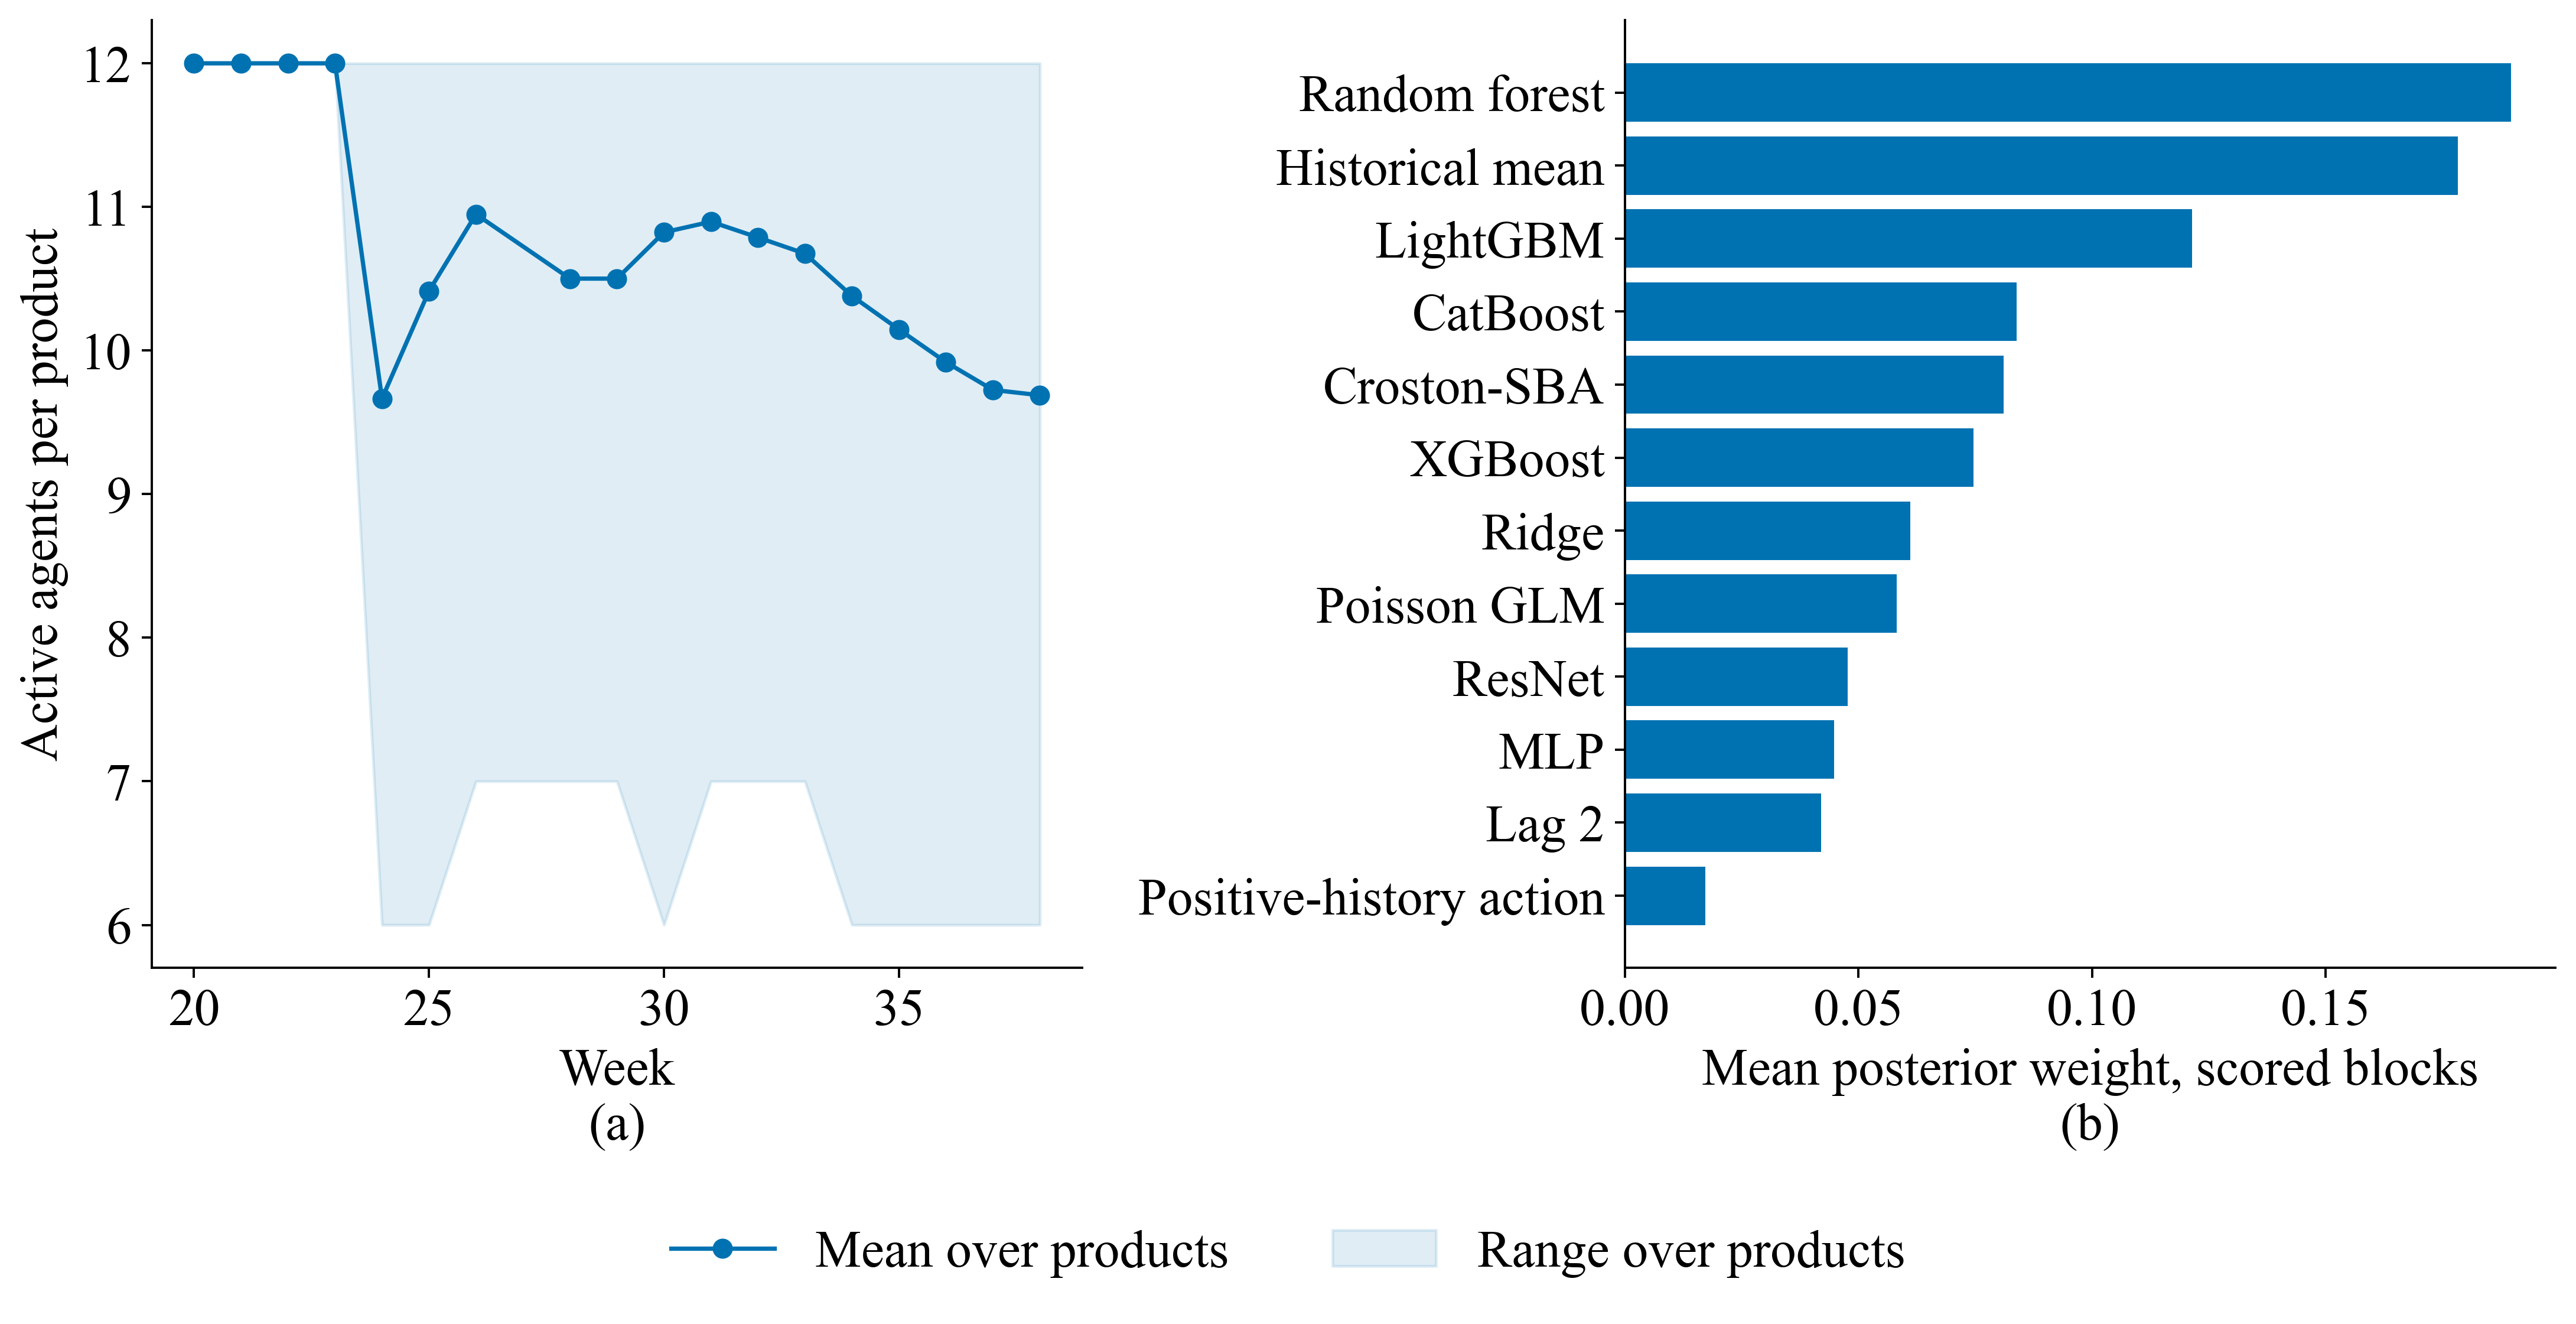

,Mean active agents,Minimum,Maximum,Product-agent deactivations,Product-agent reactivations
0,10.72626,6,12,4624,2939


,Agent,Mean weight,Active share
0,Random forest,0.18966,0.96110
1,Historical mean,0.17834,0.96453
2,LightGBM,0.12142,0.93200
3,CatBoost,0.08384,0.85322
4,Croston-SBA,0.08112,0.91397
5,XGBoost,0.07461,0.86753
6,Ridge,0.06104,0.67078
7,Poisson GLM,0.05818,0.75485
8,ResNet,0.04769,0.86204
9,MLP,0.04479,0.84587


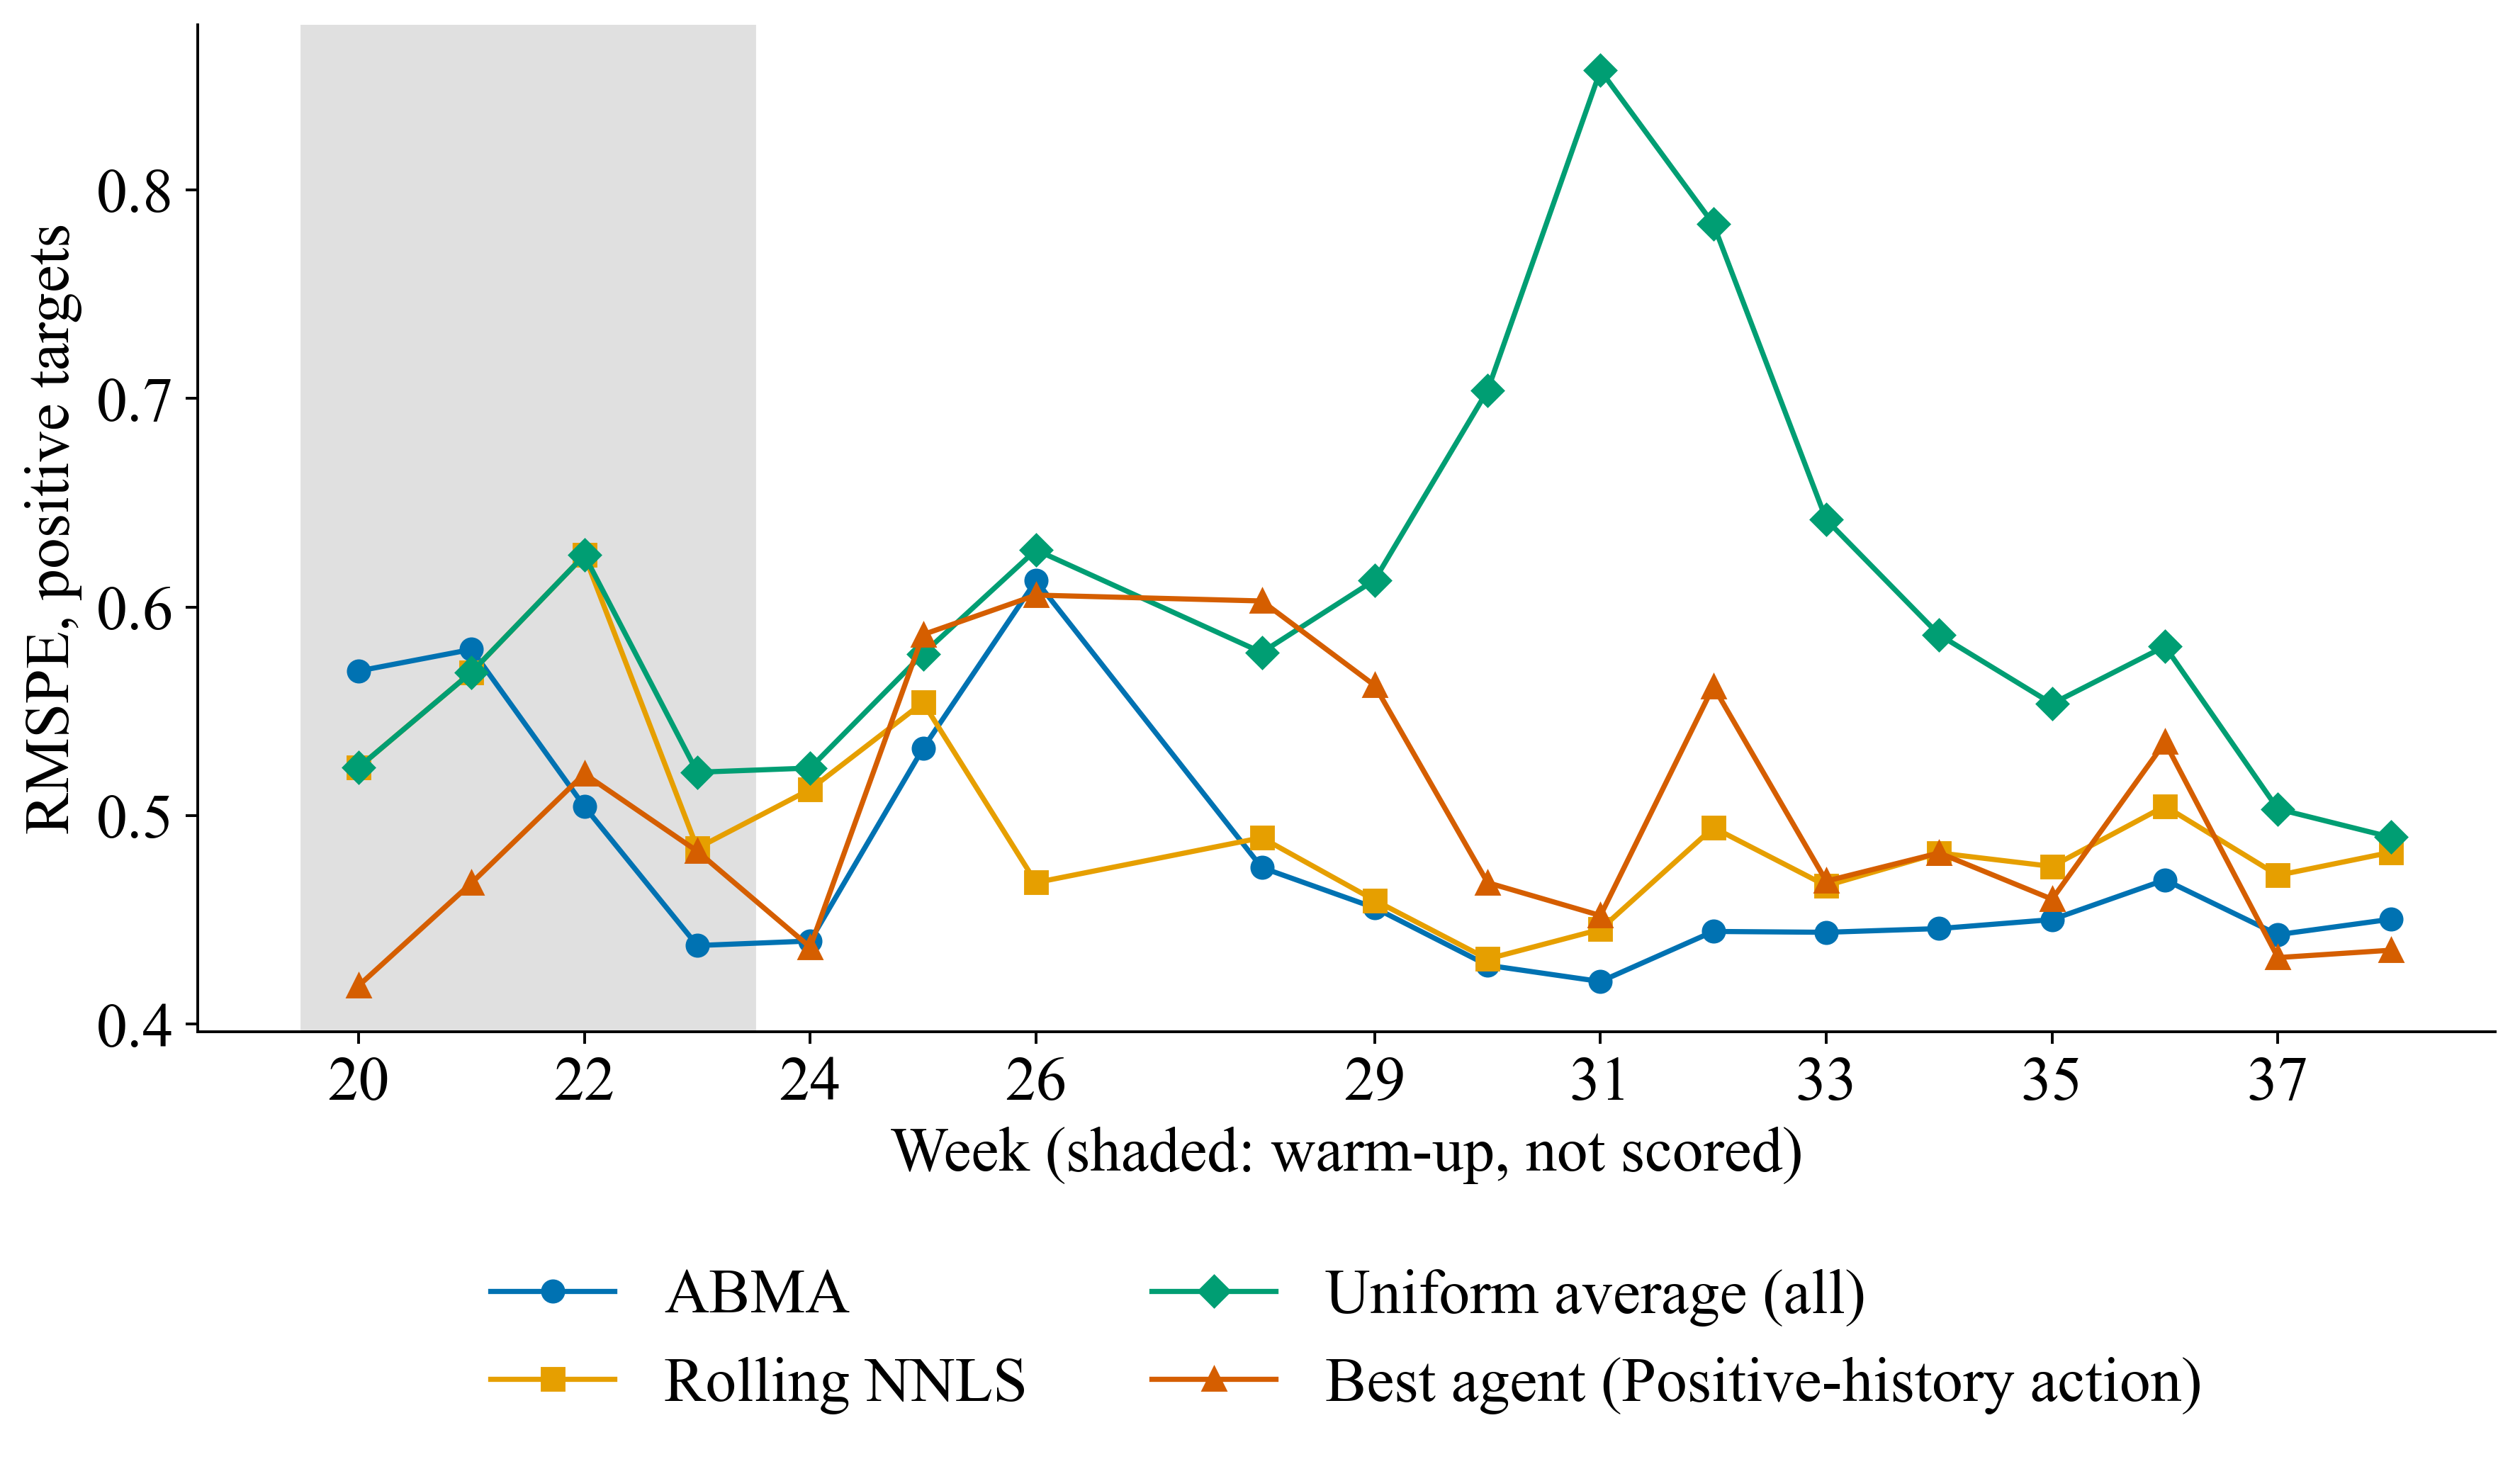

In [8]:
# NB05_DYNAMICS
active=abma_tr['ACT'].sum(1);weekly_active=pd.DataFrame({'week':wk,'active':active}).groupby('week')['active'].agg(['mean','min','max']);mean_w=pd.DataFrame(abma_tr['W'],columns=AGENTS)[scored].mean().sort_values();act_share=pd.DataFrame(abma_tr['ACT'],columns=AGENTS)[scored].mean()
fig,axes=plt.subplots(1,2,figsize=(12.8,6.6));axes[0].plot(weekly_active.index,weekly_active['mean'],color=PALETTE[0],marker='o',label='Mean over products');axes[0].fill_between(weekly_active.index,weekly_active['min'],weekly_active['max'],color=PALETTE[0],alpha=0.12,label='Range over products');axes[0].set(xlabel='Week',ylabel='Active agents per product')
axes[1].barh(range(len(mean_w)),mean_w.to_numpy(),color=PALETTE[0]);axes[1].set_yticks(range(len(mean_w)),mean_w.index);axes[1].set(xlabel='Mean posterior weight, scored blocks');h0,l0=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h0,l0,loc='lower center',ncol=2,frameon=False);fig.tight_layout(rect=[0,0.09,1,1]);figure(fig,'fig_uci_population_and_weights')
frame=pd.DataFrame(abma_tr['ACT'],columns=AGENTS);frame['s']=stream.Store.to_numpy();flips_off=flips_on=0
for a in AGENTS:d=np.concatenate(frame.groupby('s')[a].apply(lambda v:np.diff(v.to_numpy().astype(int))).to_list());flips_off+=int((d==-1).sum());flips_on+=int((d==1).sum())
table(pd.DataFrame([{'Mean active agents':float(active.mean()),'Minimum':int(active.min()),'Maximum':int(active.max()),'Product-agent deactivations':flips_off,'Product-agent reactivations':flips_on}]),'population_dynamics',fmt='%.2f');GATE_FIRED=flips_off>0 and flips_on>0
table(pd.DataFrame({'Agent':mean_w.index[::-1],'Mean weight':mean_w.to_numpy()[::-1],'Active share':act_share.reindex(mean_w.index[::-1]).to_numpy()}),'agent_weights')
BEST_COMB=str(board[board.Model.str.startswith('C: ')&~board.Model.str.contains('Best single')].iloc[0].Model);show={'ABMA':fc['ABMA'],BEST_COMB[3:]:fc[BEST_COMB],'Uniform average (all)':fc['C: Uniform average (all agents)'],f'Best agent ({BEST_SINGLE})':fc['B: '+BEST_SINGLE]}
fig,ax=plt.subplots(figsize=(10.5,6.4))
for (n,v),col,mk in zip(show.items(),PALETTE,'osD^'):ax.plot(weeks_all,[rmspe(y[wk==w],v[wk==w]) for w in weeks_all],color=col,marker=mk,label=n)
ax.axvspan(19.5,23.5,color='0.88',zorder=0);ax.set(xlabel='Week (shaded: warm-up, not scored)',ylabel='RMSPE, positive targets');ax.set_xticks(weeks_all[::2]);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_uci_development_weekly')

### 7. Stress test: a faulty agent

From W28 to W31 the LightGBM forecast is multiplied by 1.4 for a random third of the products.

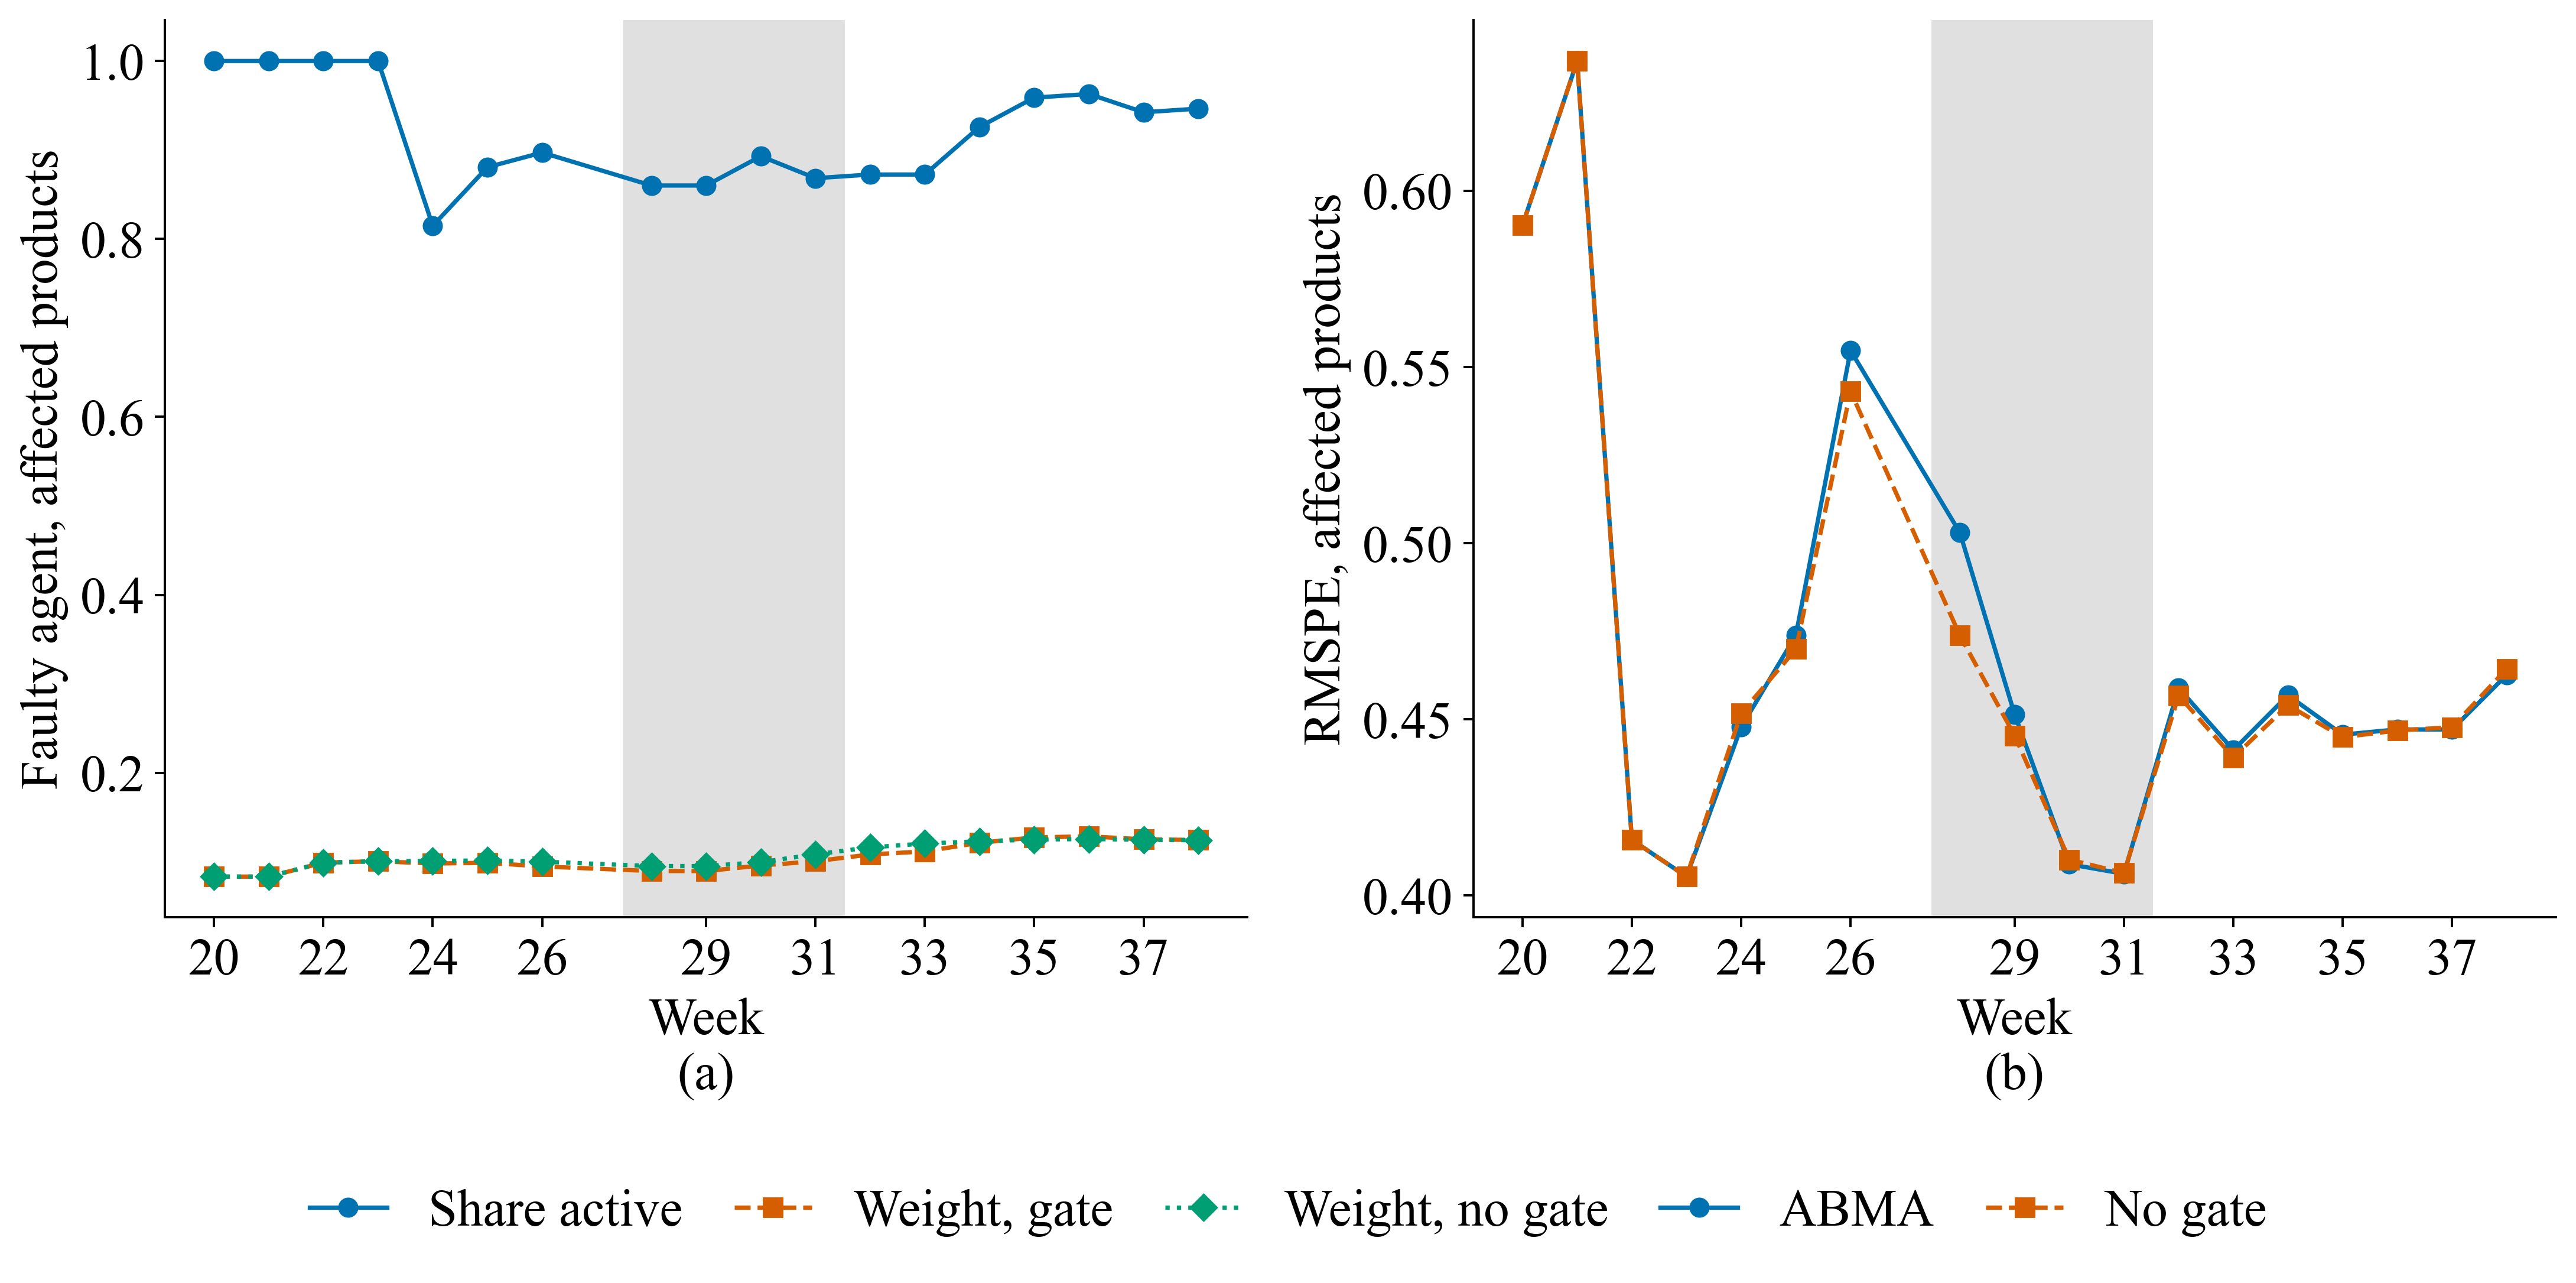

,"Rows in fault window (W28–W33, affected products)","RMSPE, with gate","RMSPE, no gate",Active share before (W24–W29),Active share W32–W33,Active share W36–W38
0,1458,0.44561,0.43891,0.86255,0.87243,0.95062


In [9]:
# NB05_FAULT
fault=Pq.copy();gen_f=np.random.default_rng(SEED);hit=gen_f.choice(stream.Store.unique(),stream.Store.nunique()//3,replace=False);in_hit=stream.Store.isin(hit).to_numpy();kL=AGENTS.index('LightGBM');fault_rows=stream.week.between(28,31).to_numpy()&in_hit;fault[fault_rows,kL]*=1.4
g_on,tr_on=abma_run(stream,fault,ABMA_CFG);g_off,tr_off=abma_run(stream,fault,{**ABMA_CFG,'gate_on':False})
dd=pd.DataFrame({'week':wk,'hit':in_hit,'active':tr_on['ACT'][:,kL],'w_on':tr_on['W'][:,kL],'w_off':tr_off['W'][:,kL],'e_on':np.where(pos,((g_on-y)/np.where(pos,y,1))**2,np.nan),'e_off':np.where(pos,((g_off-y)/np.where(pos,y,1))**2,np.nan)});day=dd[dd.hit].groupby('week').agg(active=('active','mean'),w_on=('w_on','mean'),w_off=('w_off','mean'),e_on=('e_on','mean'),e_off=('e_off','mean'))
fig,axes=plt.subplots(1,2,figsize=(12.8,6.4));axes[0].plot(day.index,day['active'],color=PALETTE[0],marker='o',label='Share active');axes[0].plot(day.index,day['w_on'],color=PALETTE[3],ls='--',marker='s',label='Weight, gate');axes[0].plot(day.index,day['w_off'],color=PALETTE[2],ls=':',marker='D',label='Weight, no gate');axes[0].set(xlabel='Week',ylabel='Faulty agent, affected products')
axes[1].plot(day.index,np.sqrt(day['e_on']),color=PALETTE[0],marker='o',label='ABMA');axes[1].plot(day.index,np.sqrt(day['e_off']),color=PALETTE[3],ls='--',marker='s',label='No gate');axes[1].set(xlabel='Week',ylabel='RMSPE, affected products')
for ax in axes:ax.axvspan(27.5,31.5,color='0.88',zorder=0);ax.set_xticks(weeks_all[::2])
h0,l0=axes[0].get_legend_handles_labels();h1,l1=axes[1].get_legend_handles_labels();label_panels(axes);fig.legend(h0+h1,l0+l1,loc='lower center',ncol=5,frameon=False,columnspacing=1.0,handlelength=1.5);fig.tight_layout(rect=[0,0.10,1,1]);figure(fig,'fig_uci_fault_response')
u=stream.week.between(28,33).to_numpy()&in_hit;table(pd.DataFrame([{'Rows in fault window (W28–W33, affected products)':int(u.sum()),'RMSPE, with gate':rmspe(y[u],g_on[u]),'RMSPE, no gate':rmspe(y[u],g_off[u]),'Active share before (W24–W29)':float(day.loc[24:29,'active'].mean()),'Active share W32–W33':float(day.loc[32:33,'active'].mean()),'Active share W36–W38':float(day.loc[36:38,'active'].mean())}]),'fault_test')

### 8. Predictive intervals with the frozen scale

,Block,Rows,PICP90,Coverage error,MPIW90,Interval score,Zero-target coverage
0,F2,2187,0.87837,0.02163,9.37220,17.63009,0.98736
1,D,8019,0.97593,0.07593,13.69298,14.89762,0.99587
2,Pooled (F2+D),10206,0.95503,0.05503,12.76710,15.48315,0.99429


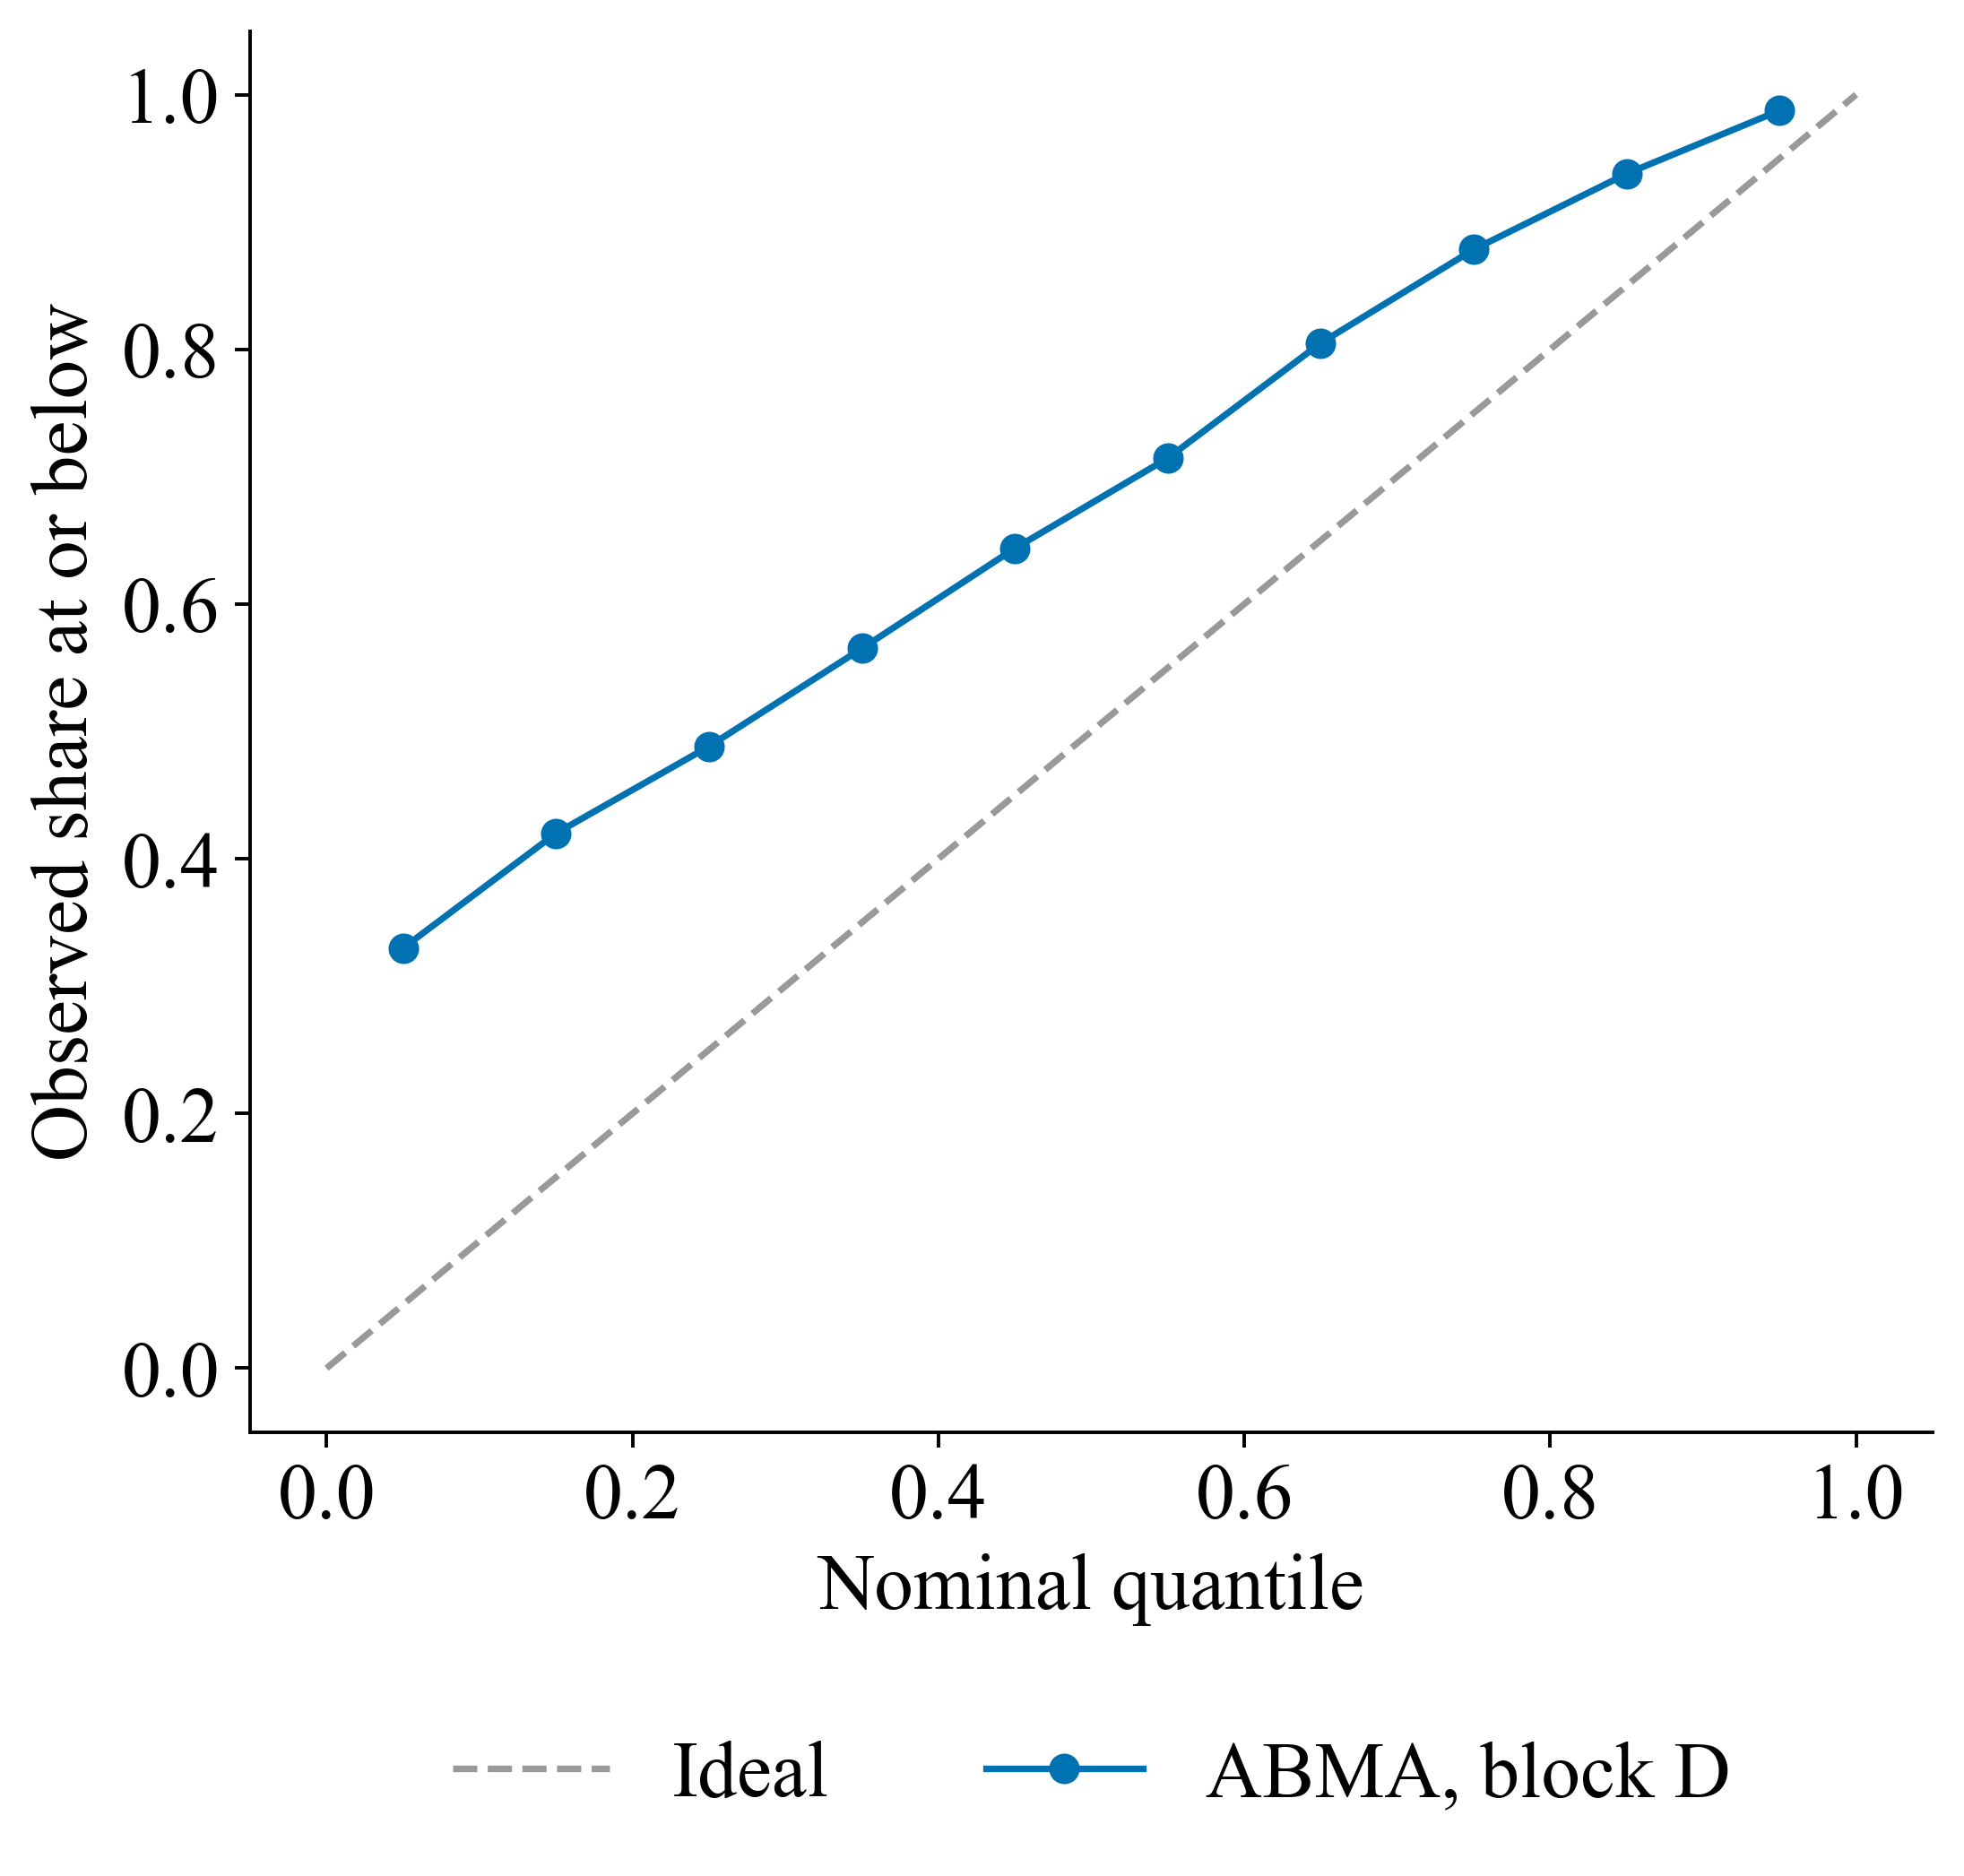

In [10]:
# NB05_INTERVALS
def mix_q(mk,q,scale=FROZEN['pi_scale']):return mixture_quantile(abma_tr['W'][mk],abma_tr['MU'][mk],abma_tr['SG'][mk],q,count=(abma_tr['P'][mk],abma_tr['LAW']*scale,abma_tr['LAW_IDX'][mk]))
pis=[]
for b in SCORED+['Pooled (F2+D)']:
    mk=scored if b.startswith('Pooled') else mask[b];lo,hi=mix_q(mk,0.05),mix_q(mk,0.95);yy=y[mk];cov=float(np.mean((yy>=lo)&(yy<=hi)));width=hi-lo
    pis.append({'Block':b,'Rows':int(mk.sum()),'PICP90':cov,'Coverage error':abs(cov-0.9),'MPIW90':float(width.mean()),'Interval score':float(np.mean(width+20*np.maximum(lo-yy,0)+20*np.maximum(yy-hi,0))),'Zero-target coverage':float(np.mean(lo[yy==0]<=0))})
table(pd.DataFrame(pis),'interval_coverage')
pc=np.linspace(.05,.95,10);cov_curve=[float((y[mask['D']]<=mix_q(mask['D'],q)).mean()) for q in pc]
fig,ax=plt.subplots(figsize=(6.6,6.4));ax.plot([0,1],[0,1],color='0.6',ls='--',label='Ideal');ax.plot(pc,cov_curve,color=PALETTE[0],marker='o',label='ABMA, block D');ax.set(xlabel='Nominal quantile',ylabel='Observed share at or below');ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.17),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_uci_reliability_development')

### 9. Frozen settings for the final evaluation

In [11]:
# NB05_RECORD: settings and forecasts read by NB06
CONTROLS={'abma_cfg':ABMA_CFG,'agents':AGENTS,'net_names':NET_NAMES,'nnls':NN_CFG,'drift_nnls':PH_CFG,'dma':DMA_CFG,'fixed_share':FS_CFG,'dwm':DWM_CFG,'stack':STACK_CFG,'corrected':CORR,'top3':TOP3,'best_single':BEST_SINGLE,'pi_scale':FROZEN['pi_scale'],'blocks':BLOCKS,'scored_blocks':SCORED,'development_pooled_rmspe':{k:float(rmspe(y[scored],v[scored])) for k,v in fc.items()},'gate_fired_in_development':bool(GATE_FIRED),'stack_features':list(Xs.columns)}
dump(BASE/'Configs/uci_frozen_controls.json',CONTROLS)
stream[['row_id','Product_Code','week','quantity','block']].assign(**{a:Pq[:,i] for i,a in enumerate(AGENTS)}).to_parquet(OUT/'agent_forecasts.parquet',index=False)  # float64: NB06 replays the development stream to the last digit
stream[['row_id','Product_Code','week','quantity','block']].assign(**{k:v.astype(np.float32) for k,v in fc.items()}).to_parquet(OUT/'development_forecasts.parquet',index=False)
latest=json.loads((BASE/'Manifests/latest_runs.json').read_text());latest['NB05']=RUN_ID;dump(BASE/'Manifests/latest_runs.json',latest)

# Part C · M5 (Walmart) weekly item-store sales

## The frozen adaptive Bayesian multi-agent model with the count law on the development weeks

The online state starts flat at W245, warms up on W245–W248 and is scored on F2 (W249–W251) and D (W253–W263); labels of week t enter at t + 2.

In [1]:
# NB05_SETUP: inputs, packages and helpers (same conventions as NB01-NB04 of this panel)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
for _d in ('Artifacts','Manifests','Configs'):(BASE/_d).mkdir(parents=True,exist_ok=True)
RUN_ID='NB05_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text());NM=json.loads((BASE/'Manifests/network_manifest.json').read_text())
NB03_OUT=BASE/'Artifacts'/BM['run_id'];NB04_OUT=BASE/'Artifacts'/NM['run_id']
FROZEN=json.loads((ROOT/'outputs'/'configs'/'abma_frozen.json').read_text());assert FROZEN['model']=='ABMA' and 'count_law' in FROZEN,'The freeze must carry the count-law constants'
import lightgbm as lgb
from scipy.optimize import nnls

### 1. Agents: twelve forecasters read from their runs

In [2]:
# NB05_AGENTS
NB03_MODELS=BM['model_order'];NB04_MODELS=NM['model_order'];AGENTS=NB03_MODELS+NB04_MODELS;NET_NAMES=list(NB04_MODELS)
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet',columns=['row_id','id','week','quantity','history_zero']).sort_values(['week','id']).reset_index(drop=True)
nested=pd.concat([pd.read_parquet(NB03_OUT/'nested_oof.parquet'),pd.read_parquet(NB04_OUT/'nested_oof.parquet')],ignore_index=True);nested_wide=nested.pivot(index='row_id',columns='model',values='prediction')[AGENTS]
dev_rows=pd.read_parquet(NB03_OUT/'development_rows.parquet');assert dev_rows.row_id.tolist()==pd.read_parquet(NB04_OUT/'development_rows.parquet').row_id.tolist()
d3,d4=np.load(NB03_OUT/'development_predictions.npz'),np.load(NB04_OUT/'development_predictions.npz');dev_wide=pd.DataFrame({m:d3[f'{NB03_MODELS.index(m)}_{SEED}'] for m in NB03_MODELS}|{m:d4[f'{NB04_MODELS.index(m)}_{SEED}'] for m in NB04_MODELS},index=dev_rows.row_id)
stream=rows[rows.week.between(245,251)|rows.week.between(253,263)].copy().reset_index(drop=True);agents=pd.concat([nested_wide,dev_wide]).reindex(stream.row_id).astype(float);assert agents.notna().all().all() and (agents>=0).all().all()
BLOCKS={'W':(245,248),'F2':(249,251),'D':(253,263)};SCORED=['F2','D'];stream['block']=np.select([stream.week.between(*b) for b in BLOCKS.values()],list(BLOCKS),default='gap');assert (stream.block!='gap').all()
stream['Store']=stream.id;stream['Date']=pd.Timestamp('2000-01-01')+pd.to_timedelta(7*stream.week,'D');stream['Sales']=stream.quantity.astype(float);stream['ctx']=0
y=stream.quantity.to_numpy(float);Pq=agents.to_numpy(float);wk=stream.week.to_numpy();pos=y>0;mask={b:(stream.block==b).to_numpy() for b in BLOCKS};scored=mask['F2']|mask['D']
def block_scores(p):r={b:rmspe(y[mask[b]],p[mask[b]]) for b in BLOCKS};r['Pooled (F2+D)']=rmspe(y[scored],p[scored]);r['mean']=float(np.mean([r[b] for b in SCORED]));return r
def board_row(p):m=metrics(y[scored],p[scored]);return {'RMSPE W (warm-up)':block_scores(p)['W'],'RMSPE F2':block_scores(p)['F2'],'RMSPE D':block_scores(p)['D'],'Pooled RMSPE':m['RMSPE'],'RMSE':m['RMSE'],'MAE':m['MAE'],'Zero MAE':m['Zero_MAE']}
agent_tab=pd.DataFrame({a:board_row(Pq[:,i]) for i,a in enumerate(AGENTS)}).T.sort_values('Pooled RMSPE').rename_axis('Agent').reset_index();table(agent_tab,'agents_development',['Pooled RMSPE','RMSE','MAE','Zero MAE'])
table(pd.DataFrame([{'Block':b,'Weeks':f'W{v[0]}–W{v[1]}','Rows':int(mask[b].sum()),'Positive targets':int((y[mask[b]]>0).sum()),'Role':'warm-up (not scored)' if b=='W' else 'scored'} for b,v in BLOCKS.items()]),'development_blocks')
print(f'Stream {len(stream):,} rows, {stream.Store.nunique():,} series, {stream.Date.nunique()} weeks, {len(AGENTS)} agents; zero share of scored targets {np.mean(y[scored]==0):.3f}')

,Agent,RMSPE W (warm-up),RMSPE F2,RMSPE D,Pooled RMSPE,RMSE,MAE,Zero MAE
0,Positive-history action,0.736049,0.647312,0.652146,0.65112,20.91487,7.35438,1.83942
1,LightGBM,0.707957,0.709953,0.723293,0.72047,20.86919,7.46697,0.46323
2,XGBoost,0.707839,0.711976,0.723390,0.72097,20.97515,7.50334,0.46234
3,CatBoost,0.723232,0.721922,0.734243,0.73164,21.31781,7.71825,0.46206
4,ResNet,1.122216,0.918966,0.958530,0.95024,11.91820,4.08974,1.46483
5,MLP,0.842422,0.854603,0.986601,0.96002,11.80038,4.14568,1.54820
6,Random forest,1.149613,0.971632,0.969296,0.96979,10.01706,3.77482,1.48144
7,Croston-SBA,1.197938,0.950196,1.135155,1.09838,12.06729,4.81832,2.75931
8,Ridge,1.460035,1.047152,1.195777,1.16572,10.10839,3.77179,1.53500
9,Poisson GLM,1.990998,1.359411,1.552699,1.51361,9.46923,3.73870,2.60947


,Block,Weeks,Rows,Positive targets,Role
0,W,W245–W248,109764,85142,warm-up (not scored)
1,F2,W249–W251,82323,62829,scored
2,D,W253–W263,301851,232227,scored


Stream 493,938 rows, 27,441 series, 18 weeks, 12 agents; zero share of scored targets 0.232


### 2. The count law

For agent $k$ the scaled residual $r=(y-p_k)/\sqrt{p_k+1}$ feeds a discounted chain-wide reservoir (257 weighted quantiles, discount 0.98) and the predictive law of $y$ is $\max(0,\mathrm{round}(p_k+\sqrt{p_k+1}\,r))$.

In [3]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [4]:
# NB05_FROZEN
CL=FROZEN['count_law'];ABMA_CFG={**FROZEN['abma'],'lag':14,'nctx':1,'law':'count','n_res':CL['n_res'],'disc_res':CL['disc_res'],'smooth':CL['smooth']}
def run(cfg,Pm=None,st=None):return abma_run(stream if st is None else st,Pq if Pm is None else Pm,cfg)[0]
table(pd.DataFrame([{'Setting':k,'Frozen value':v} for k,v in FROZEN['abma'].items()]+[{'Setting':'law','Frozen value':'count (rule: '+CL['rule'][:60]+'…)'},{'Setting':'n_res / disc_res / smooth','Frozen value':f"{CL['n_res']} / {CL['disc_res']} / {CL['smooth']}"},{'Setting':'lag (days) / nctx','Frozen value':'14 / 1'},{'Setting':'pi_scale','Frozen value':FROZEN['pi_scale']}]),'frozen_configuration')

,Setting,Frozen value
0,eta,0.50000
1,disc_w,0.99000
2,disc_var,0.99500
3,gate_loss,relative
4,sig_scale,0.90000
5,theta0,0.50000
6,gate_p,0.90000
7,disc_beta,0.90000
8,kappa,0.00000
9,law,count (rule: law = count when the target is a non-negative integer with z…)


### 3. Frozen model on the development weeks

In [5]:
# NB05_DEVELOPMENT
base_out,base_tr=abma_run(stream,Pq,ABMA_CFG)
abma_out,abma_tr=base_out,base_tr;fc={'ABMA':abma_out};print('Frozen ABMA (count law) on development:',{k:round(v,5) for k,v in block_scores(fc['ABMA']).items()})

Frozen ABMA (count law) on development: {'W': 0.66232, 'F2': 0.67195, 'D': 0.68833, 'Pooled (F2+D)': 0.68488, 'mean': 0.68014}


### 4. Controls tuned with the main-chain budget on the scored blocks

Rolling NNLS, nonlinear stacking and dynamic model averaging receive 40 configurations and the streaming controls use the fixed grids of Part A, all under the criterion mean RMSPE over F2 and D.

In [6]:
# NB05_CONTROLS
def hist_mask(block):return (stream.week<=BLOCKS[block][0]-2).to_numpy()
def relative_correct(p):
    out=p.copy()
    for b in SCORED:h=hist_mask(b)&pos;now=mask[b];r=p[h]/y[h];out[now]=p[now]*(r.sum()/max((r**2).sum(),1e-12))
    return out
def better(name,raw,record=None):
    cand={False:raw,True:relative_correct(raw)};flag=min(cand,key=lambda f:block_scores(cand[f])['mean'])
    if record is not None:record[name]=bool(flag)
    return cand[flag],bool(flag)
weeks_all=np.sort(stream.week.unique());NO_NETS=[i for i,a in enumerate(AGENTS) if a not in NET_NAMES]
rel=np.where(pos[:,None],Pq/np.where(pos,y,1.0)[:,None],0.0);grams={w:(rel[(wk==w)&pos].T@rel[(wk==w)&pos],rel[(wk==w)&pos].sum(0)) for w in weeks_all}
def rolling_nnls(window,lam,pool='all',reset_week=None):
    idx=list(range(len(AGENTS))) if pool=='all' else NO_NETS;K=len(idx);out=np.zeros(len(y))
    for w in weeks_all:
        hw=[v for v in weeks_all if v<=w-2 and (window is None or v>w-2-window) and (reset_week is None or v>=reset_week.get(w,0))];now=wk==w
        if len(hw)<2:out[now]=Pq[now][:,idx].mean(1);continue
        G=sum(grams[v][0][np.ix_(idx,idx)] for v in hw)+lam*np.eye(K);h=sum(grams[v][1][idx] for v in hw);L=np.linalg.cholesky(G);beta=nnls(L.T,np.linalg.solve(L,h),maxiter=200)[0];out[now]=Pq[now][:,idx]@beta if beta.sum()>0 else Pq[now][:,idx].mean(1)
    return out
nn_trials=[]
for c in [dict(window=w,lam=l,pool=b) for w in (4,8,12,None) for l in (1.0,10.0,100.0,1000.0,10000.0) for b in ('all','no_nets')]:
    raw=rolling_nnls(c['window'],c['lam'],c['pool'])
    for flag,p in [(False,raw),(True,relative_correct(raw))]:nn_trials.append({**c,'corrected':flag,**block_scores(p)})
nn_trials=pd.DataFrame(nn_trials).sort_values('mean').reset_index(drop=True);NN_CFG=dict(window=None if pd.isna(nn_trials.loc[0,'window']) else int(nn_trials.loc[0,'window']),lam=float(nn_trials.loc[0,'lam']),pool=str(nn_trials.loc[0,'pool']));NN_CORR=bool(nn_trials.loc[0,'corrected'])
def drift_nnls_weekly(window,lam,pool,delta,lam_ph):
    idx=list(range(len(AGENTS))) if pool=='all' else NO_NETS;out=np.zeros(len(y));last_reset=0;checked=set();x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
    for w in weeks_all:
        for v in [v for v in weeks_all if v<=w-2 and v not in checked]:
            checked.add(v);r=(wk==v)&pos;x=float((((out[r]-y[r])/y[r])**2).mean()) if r.any() else 0.0;x_n+=1;x_sum+=x;m_sum+=x-x_sum/x_n-delta;m_min=min(m_min,m_sum)
            if m_sum-m_min>lam_ph:last_reset=v+1;x_sum,x_n,m_sum,m_min=0.0,0,0.0,0.0
        out[wk==w]=rolling_nnls(window,lam,pool,reset_week={w:last_reset})[wk==w]
    return out
ph_trials=[]
for c in [dict(delta=d_,lam_ph=l_) for d_ in (0.001,0.005,0.01) for l_ in (0.02,0.05,0.1,0.2,0.5)]:
    raw=drift_nnls_weekly(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool'],**c)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:ph_trials.append({**c,'corrected':flag,**block_scores(p)})
ph_trials=pd.DataFrame(ph_trials).sort_values('mean').reset_index(drop=True);PH_CFG={'delta':float(ph_trials.loc[0,'delta']),'lam_ph':float(ph_trials.loc[0,'lam_ph'])};PH_CORR=bool(ph_trials.loc[0,'corrected'])
P1=Pq+1.0;S1=y+1.0;st1=stream.assign(Sales=S1)  # shifted scale for the log-based combiners (dynamic model averaging, fixed-share, dynamic weighted majority)
dma_trials=[]
for cfg in [dict(disc_w=a,eta=b) for a in (0.9,0.95,0.98,0.99,0.995,0.999) for b in (0.1,0.25,0.5,1.0,2.0,4.0,8.0)][:40]:
    raw=np.maximum(0.,abma_run(st1,P1,{**cfg,'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:dma_trials.append({**cfg,'corrected':flag,**block_scores(p)})
dma_trials=pd.DataFrame(dma_trials).sort_values('mean').reset_index(drop=True);DMA_CFG={k:float(dma_trials.loc[0,k]) for k in ('disc_w','eta')};DMA_CORR=bool(dma_trials.loc[0,'corrected'])
fs_trials=[]
for cfg in [dict(eta=e_,alpha=a_,scope=s_) for e_ in (1.0,3.0,10.0,30.0,100.0) for a_ in (0.0,0.01,0.05,0.2) for s_ in ('store','chain')]:
    raw=np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**cfg)-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:fs_trials.append({**cfg,'corrected':flag,**block_scores(p)})
fs_trials=pd.DataFrame(fs_trials).sort_values('mean').reset_index(drop=True);FS_CFG={'eta':float(fs_trials.loc[0,'eta']),'alpha':float(fs_trials.loc[0,'alpha']),'scope':str(fs_trials.loc[0,'scope'])};FS_CORR=bool(fs_trials.loc[0,'corrected'])
dwm_trials=[]
for cfg in [dict(beta=b_,theta=t_,eps=e_,period=p_) for b_ in (0.5,0.7,0.9) for t_ in (0.01,0.05) for e_ in (0.05,0.1,0.2) for p_ in (1,4)]:
    raw=np.maximum(0.,dwm(st1,P1,S1,lag=14,**cfg)-1.0)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:dwm_trials.append({**cfg,'corrected':flag,**block_scores(p)})
dwm_trials=pd.DataFrame(dwm_trials).sort_values('mean').reset_index(drop=True);DWM_CFG={'beta':float(dwm_trials.loc[0,'beta']),'theta':float(dwm_trials.loc[0,'theta']),'eps':float(dwm_trials.loc[0,'eps']),'period':int(dwm_trials.loc[0,'period'])};DWM_CORR=bool(dwm_trials.loc[0,'corrected'])
Xs=pd.DataFrame(np.log1p(Pq),columns=AGENTS);Xs['dispersion']=np.log1p(Pq).std(1);Xs['history_zero']=stream.history_zero.to_numpy()
STACK_SPACE=dict(n_estimators=[100,200,300,500,800],learning_rate=[0.01,0.02,0.03,0.05],num_leaves=[7,15,31,63],min_child_samples=[50,200,500,1000],colsample_bytree=[0.5,0.7,1.0],reg_lambda=[0.0,1.0,10.0],weight=[0.0,1.0,2.0],pool=['all','no_nets'])
rng_s=np.random.default_rng(SEED)
def sample(space):return {k:v[rng_s.integers(len(v))] for k,v in space.items()}
def stack_forecast(cfg,seed=SEED):
    cfg=dict(cfg);pw=cfg.pop('weight');pool=cfg.pop('pool');use=[c for c in Xs.columns if pool=='all' or c not in NET_NAMES];out=Pq.mean(1).copy()
    for b in SCORED:
        h=hist_mask(b);now=mask[b];m=lgb.LGBMRegressor(**{k:(int(v) if k in ('n_estimators','num_leaves','min_child_samples') else float(v)) for k,v in cfg.items()},subsample=0.8,subsample_freq=1,random_state=seed,n_jobs=4,verbose=-1,deterministic=True,force_col_wise=True).fit(Xs.loc[h,use],np.log1p(y[h]),sample_weight=(1/np.maximum(y[h],1))**pw);out[now]=np.maximum(0.,np.expm1(m.predict(Xs.loc[now,use])))
    return out
st=[]
for t in range(40):
    cfg=sample(STACK_SPACE);raw=stack_forecast(cfg)
    for flag,p in [(False,raw),(True,relative_correct(raw))]:st.append({**cfg,'corrected':flag,**block_scores(p)})
    print('stack',t,round(st[-2]['mean'],5),flush=True) if t%10==9 else None
st=pd.DataFrame(st).sort_values('mean').reset_index(drop=True);STACK_CFG={k:(str(st.loc[0,k]) if k=='pool' else float(st.loc[0,k])) for k in STACK_SPACE};STACK_CORR=bool(st.loc[0,'corrected'])
TOP3=list(pd.Series({a:rmspe(y[mask['W']],Pq[mask['W'],i]) for i,a in enumerate(AGENTS)}).sort_values().index[:3]);BEST_SINGLE=str(agent_tab.Agent.iloc[0]);i_bs=AGENTS.index(BEST_SINGLE)
control_tuning=pd.DataFrame([{'Method':'ABMA (frozen, no search)','Configurations':0,'Best mean RMSPE':block_scores(fc['ABMA'])['mean'],'Selected':'frozen'},{'Method':'Dynamic model averaging','Configurations':len(dma_trials)//2,'Best mean RMSPE':dma_trials.loc[0,'mean'],'Selected':str(DMA_CFG)+(' corrected' if DMA_CORR else '')},{'Method':'Rolling NNLS','Configurations':len(nn_trials)//2,'Best mean RMSPE':nn_trials.loc[0,'mean'],'Selected':str(NN_CFG)+(' corrected' if NN_CORR else '')},{'Method':'Nonlinear stacking','Configurations':len(st)//2,'Best mean RMSPE':st.loc[0,'mean'],'Selected':str(STACK_CFG)+(' corrected' if STACK_CORR else '')},{'Method':'Fixed-share exponential weighting','Configurations':len(fs_trials)//2,'Best mean RMSPE':fs_trials.loc[0,'mean'],'Selected':str(FS_CFG)+(' corrected' if FS_CORR else '')},{'Method':'Dynamic weighted majority','Configurations':len(dwm_trials)//2,'Best mean RMSPE':dwm_trials.loc[0,'mean'],'Selected':str(DWM_CFG)+(' corrected' if DWM_CORR else '')},{'Method':'Drift-reset NNLS (Page-Hinkley)','Configurations':len(ph_trials)//2,'Best mean RMSPE':ph_trials.loc[0,'mean'],'Selected':str(PH_CFG)+(' corrected' if PH_CORR else '')},{'Method':'Uniform average (three best of W245–W248)','Configurations':0,'Best mean RMSPE':np.nan,'Selected':', '.join(TOP3)}])
table(control_tuning,'control_tuning')
for name,df in [('nnls',nn_trials),('drift_nnls',ph_trials),('dma',dma_trials),('fixed_share',fs_trials),('dwm',dwm_trials),('stacking',st)]:df.to_csv(OUT/f'tuning_{name}.csv',index=False)

stack 9 0.97998


stack 19 0.85513


stack 29 0.79974


stack 39 0.68513


,Method,Configurations,Best mean RMSPE,Selected
0,"ABMA (frozen, no search)",0,0.68014,frozen
1,Dynamic model averaging,40,0.71598,"{'disc_w': 0.999, 'eta': 1.0} corrected"
2,Rolling NNLS,40,0.63129,"{'window': 4, 'lam': 1000.0, 'pool': 'all'}"
3,Nonlinear stacking,40,0.68015,"{'n_estimators': 300.0, 'learning_rate': 0.01, 'num_leaves': 31.0, 'min_child_samples': 200.0, 'colsample_bytree': 0.7, 'reg_lambda': 1.0, 'weight': 1.0, 'pool': 'all'}"
4,Fixed-share exponential weighting,40,0.66952,"{'eta': 1.0, 'alpha': 0.2, 'scope': 'chain'} corrected"
5,Dynamic weighted majority,36,0.66517,"{'beta': 0.9, 'theta': 0.01, 'eps': 0.05, 'period': 4} corrected"
6,Drift-reset NNLS (Page-Hinkley),15,0.63129,"{'delta': 0.001, 'lam_ph': 0.02}"
7,Uniform average (three best of W245–W248),0,n/a,"XGBoost, LightGBM, CatBoost"


### 5. Ablations, controls and single agents on identical rows

Ablations remove one mechanism from the frozen configuration; paired series-cluster bootstrap (2,000 replicates) with Holm adjustment over all comparators.

In [7]:
# NB05_BOARD
def paired_to(base,others,ids,B=2000,chunk=250):
    st_id=np.unique(ids,return_inverse=True)[1];Ns=st_id.max()+1;cnt=np.bincount(st_id,minlength=Ns).astype(float);yy=y_eval;be=np.bincount(st_id,((base-yy)/yy)**2,Ns);g=np.random.default_rng(SEED);names=list(others);oes=[np.bincount(st_id,((others[n]-yy)/yy)**2,Ns) for n in names];d=np.zeros((len(names),B))
    for a in range(0,B,chunk):
        draws=g.multinomial(Ns,np.full(Ns,1/Ns),min(chunk,B-a)).astype(float);ab=np.sqrt(draws@be/(draws@cnt))
        for j,oe in enumerate(oes):d[j,a:a+len(draws)]=ab-np.sqrt(draws@oe/(draws@cnt))
    out=[{'Comparator':n,'RMSPE comparator':np.sqrt(oe.sum()/cnt.sum()),'Difference (ABMA - comparator)':np.sqrt(be.sum()/cnt.sum())-np.sqrt(oe.sum()/cnt.sum()),'CI low':np.quantile(d[j],0.025),'CI high':np.quantile(d[j],0.975),'p':min(1.0,2*min((d[j]>=0).mean(),(d[j]<=0).mean())+2/B)} for j,(n,oe) in enumerate(zip(names,oes))]
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True);m=len(r);r['Holm p']=np.minimum(1,np.maximum.accumulate(r['p']*(m-np.arange(m))));return r.sort_values('RMSPE comparator').reset_index(drop=True)
ev=scored&pos;y_eval=y[ev];ids_eval=stream.Store.to_numpy()[ev]
PROTECTED={'No Bayes action (posterior mean of log forecast)':{'action':'median'},'Uniform weights over active agents':{'weight_mode':'uniform'},'No persistent gate':{'gate_on':False},'No reactivation':{'reactivate':False}}
ABL=dict(PROTECTED);ABL['Added instantaneous gate (kappa 2.5)']={'kappa':2.5};ABL['Added product bias tracker']={'bias_mode':'agent'}  # the product-level variance ablation is not applicable under the count law: the variance state enters neither the count-law weights nor the action
for n,c in ABL.items():fc['A: '+n]=run({**ABMA_CFG,**c})
fc[f'A: Single agent ({BEST_SINGLE}) with count-law action']=run({**ABMA_CFG,'gate_on':False},Pm=Pq[:,[i_bs]*3])
CORR={};fc['C: Best single agent'],_=better('C: Best single agent',Pq[:,i_bs],CORR);fc['C: Uniform average (all agents)'],_=better('C: Uniform average (all agents)',Pq.mean(1),CORR);fc['C: Uniform average (three best agents)'],_=better('C: Uniform average (three best agents)',Pq[:,[AGENTS.index(a) for a in TOP3]].mean(1),CORR);fc['C: Three boosters average'],_=better('C: Three boosters average',Pq[:,[AGENTS.index(a) for a in ('LightGBM','XGBoost','CatBoost')]].mean(1),CORR)
raw=rolling_nnls(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool']);fc['C: Rolling NNLS']=relative_correct(raw) if NN_CORR else raw;CORR['C: Rolling NNLS']=NN_CORR
raw=stack_forecast(STACK_CFG);fc['C: Nonlinear stacking']=relative_correct(raw) if STACK_CORR else raw;CORR['C: Nonlinear stacking']=STACK_CORR
raw=np.maximum(0.,abma_run(st1,P1,{**DMA_CFG,'weight_mode':'global','gate_on':False,'action':'median','lag':14,'nctx':1})[0]-1.0);fc['C: Dynamic model averaging']=relative_correct(raw) if DMA_CORR else raw;CORR['C: Dynamic model averaging']=DMA_CORR
raw=np.maximum(0.,fixed_share(st1,P1,S1,lag=14,**FS_CFG)-1.0);fc['C: Fixed-share exponential weighting']=relative_correct(raw) if FS_CORR else raw;CORR['C: Fixed-share exponential weighting']=FS_CORR
raw=np.maximum(0.,dwm(st1,P1,S1,lag=14,**DWM_CFG)-1.0);fc['C: Dynamic weighted majority']=relative_correct(raw) if DWM_CORR else raw;CORR['C: Dynamic weighted majority']=DWM_CORR
raw=drift_nnls_weekly(NN_CFG['window'],NN_CFG['lam'],NN_CFG['pool'],**PH_CFG);fc['C: Drift-reset NNLS (Page-Hinkley)']=relative_correct(raw) if PH_CORR else raw;CORR['C: Drift-reset NNLS (Page-Hinkley)']=PH_CORR
for i,a in enumerate(AGENTS):fc['B: '+a]=Pq[:,i]
board=pd.DataFrame({k:board_row(v) for k,v in fc.items()}).T.sort_values('Pooled RMSPE').rename_axis('Model').reset_index();table(board,'development_board',['Pooled RMSPE','RMSE','MAE','Zero MAE'])
paired=paired_to(fc['ABMA'][ev],{k:v[ev] for k,v in fc.items() if k!='ABMA'},ids_eval);table(paired,'development_paired')
MECH=list(PROTECTED);rule=paired_to(fc['ABMA'][ev],{'A: '+m:fc['A: '+m][ev] for m in MECH},ids_eval).set_index('Comparator').loc[['A: '+m for m in MECH]]
component=pd.DataFrame({'Component removed':MECH,'Kind':['protected']*4,'Difference (ABMA - ablation)':rule['Difference (ABMA - comparator)'].to_numpy(),'Holm p (mechanism family)':rule['Holm p'].to_numpy(),'Holm p (all comparators)':paired.set_index('Comparator').loc[['A: '+m for m in MECH],'Holm p'].to_numpy(),'Significantly worse without it':((rule['Difference (ABMA - comparator)']<0)&(rule['Holm p']<0.05)).to_numpy()});table(component,'component_evidence')
pd.DataFrame({k:[rmspe(y[wk==w],v[wk==w]) for w in weeks_all] for k,v in fc.items()},index=weeks_all).rename_axis('Week').reset_index().to_csv(OUT/'weekly_rmspe.csv',index=False)

,Model,RMSPE W (warm-up),RMSPE F2,RMSPE D,Pooled RMSPE,RMSE,MAE,Zero MAE
0,A: No persistent gate,0.662320,0.628115,0.624348,0.62515,20.15154,6.72804,1.47075
1,C: Drift-reset NNLS (Page-Hinkley),0.938782,0.634426,0.628160,0.62950,19.20404,6.67871,1.29980
2,C: Rolling NNLS,0.938782,0.634426,0.628160,0.62950,19.20404,6.67871,1.29980
3,B: Positive-history action,0.736049,0.647312,0.652146,0.65112,20.91487,7.35438,1.83942
4,C: Best single agent,0.736049,0.647312,0.652146,0.65112,20.91487,7.35438,1.83942
5,C: Uniform average (three best agents),0.711892,0.655847,0.657905,0.65747,20.43949,6.90696,0.74805
6,C: Three boosters average,0.711892,0.655847,0.657905,0.65747,20.43949,6.90696,0.74805
7,C: Dynamic weighted majority,0.717120,0.658248,0.672089,0.66917,17.73632,6.14611,0.85153
8,C: Fixed-share exponential weighting,0.721918,0.661411,0.677621,0.67420,17.39876,6.04473,0.87600
9,C: Nonlinear stacking,0.995304,0.678488,0.681806,0.68110,19.69381,6.70602,0.55858


,Comparator,RMSPE comparator,Difference (ABMA - comparator),CI low,CI high,p,Holm p
0,A: No persistent gate,0.62515,0.05972,0.02488,0.10478,0.001,0.029
1,C: Drift-reset NNLS (Page-Hinkley),0.62950,0.05538,0.02150,0.09876,0.001,0.029
2,C: Rolling NNLS,0.62950,0.05538,0.02150,0.09876,0.001,0.029
3,B: Positive-history action,0.65112,0.03376,-0.00170,0.07943,0.072,0.792
4,C: Best single agent,0.65112,0.03376,-0.00170,0.07943,0.072,0.792
5,C: Three boosters average,0.65747,0.02741,-0.00765,0.07292,0.161,0.966
6,C: Uniform average (three best agents),0.65747,0.02741,-0.00765,0.07292,0.161,0.966
7,C: Dynamic weighted majority,0.66917,0.01571,-0.01646,0.05596,0.417,1
8,C: Fixed-share exponential weighting,0.67420,0.01067,-0.02117,0.04993,0.625,1
9,C: Nonlinear stacking,0.68110,0.00377,-0.03088,0.04936,0.946,1


,Component removed,Kind,Difference (ABMA - ablation),Holm p (mechanism family),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.35286,0.004,0.029,True
1,Uniform weights over active agents,protected,-0.00845,0.053,0.636,False
2,No persistent gate,protected,0.05972,0.004,0.029,False
3,No reactivation,protected,-0.04124,0.03,0.24,True


### 6. Internal dynamics and weekly errors

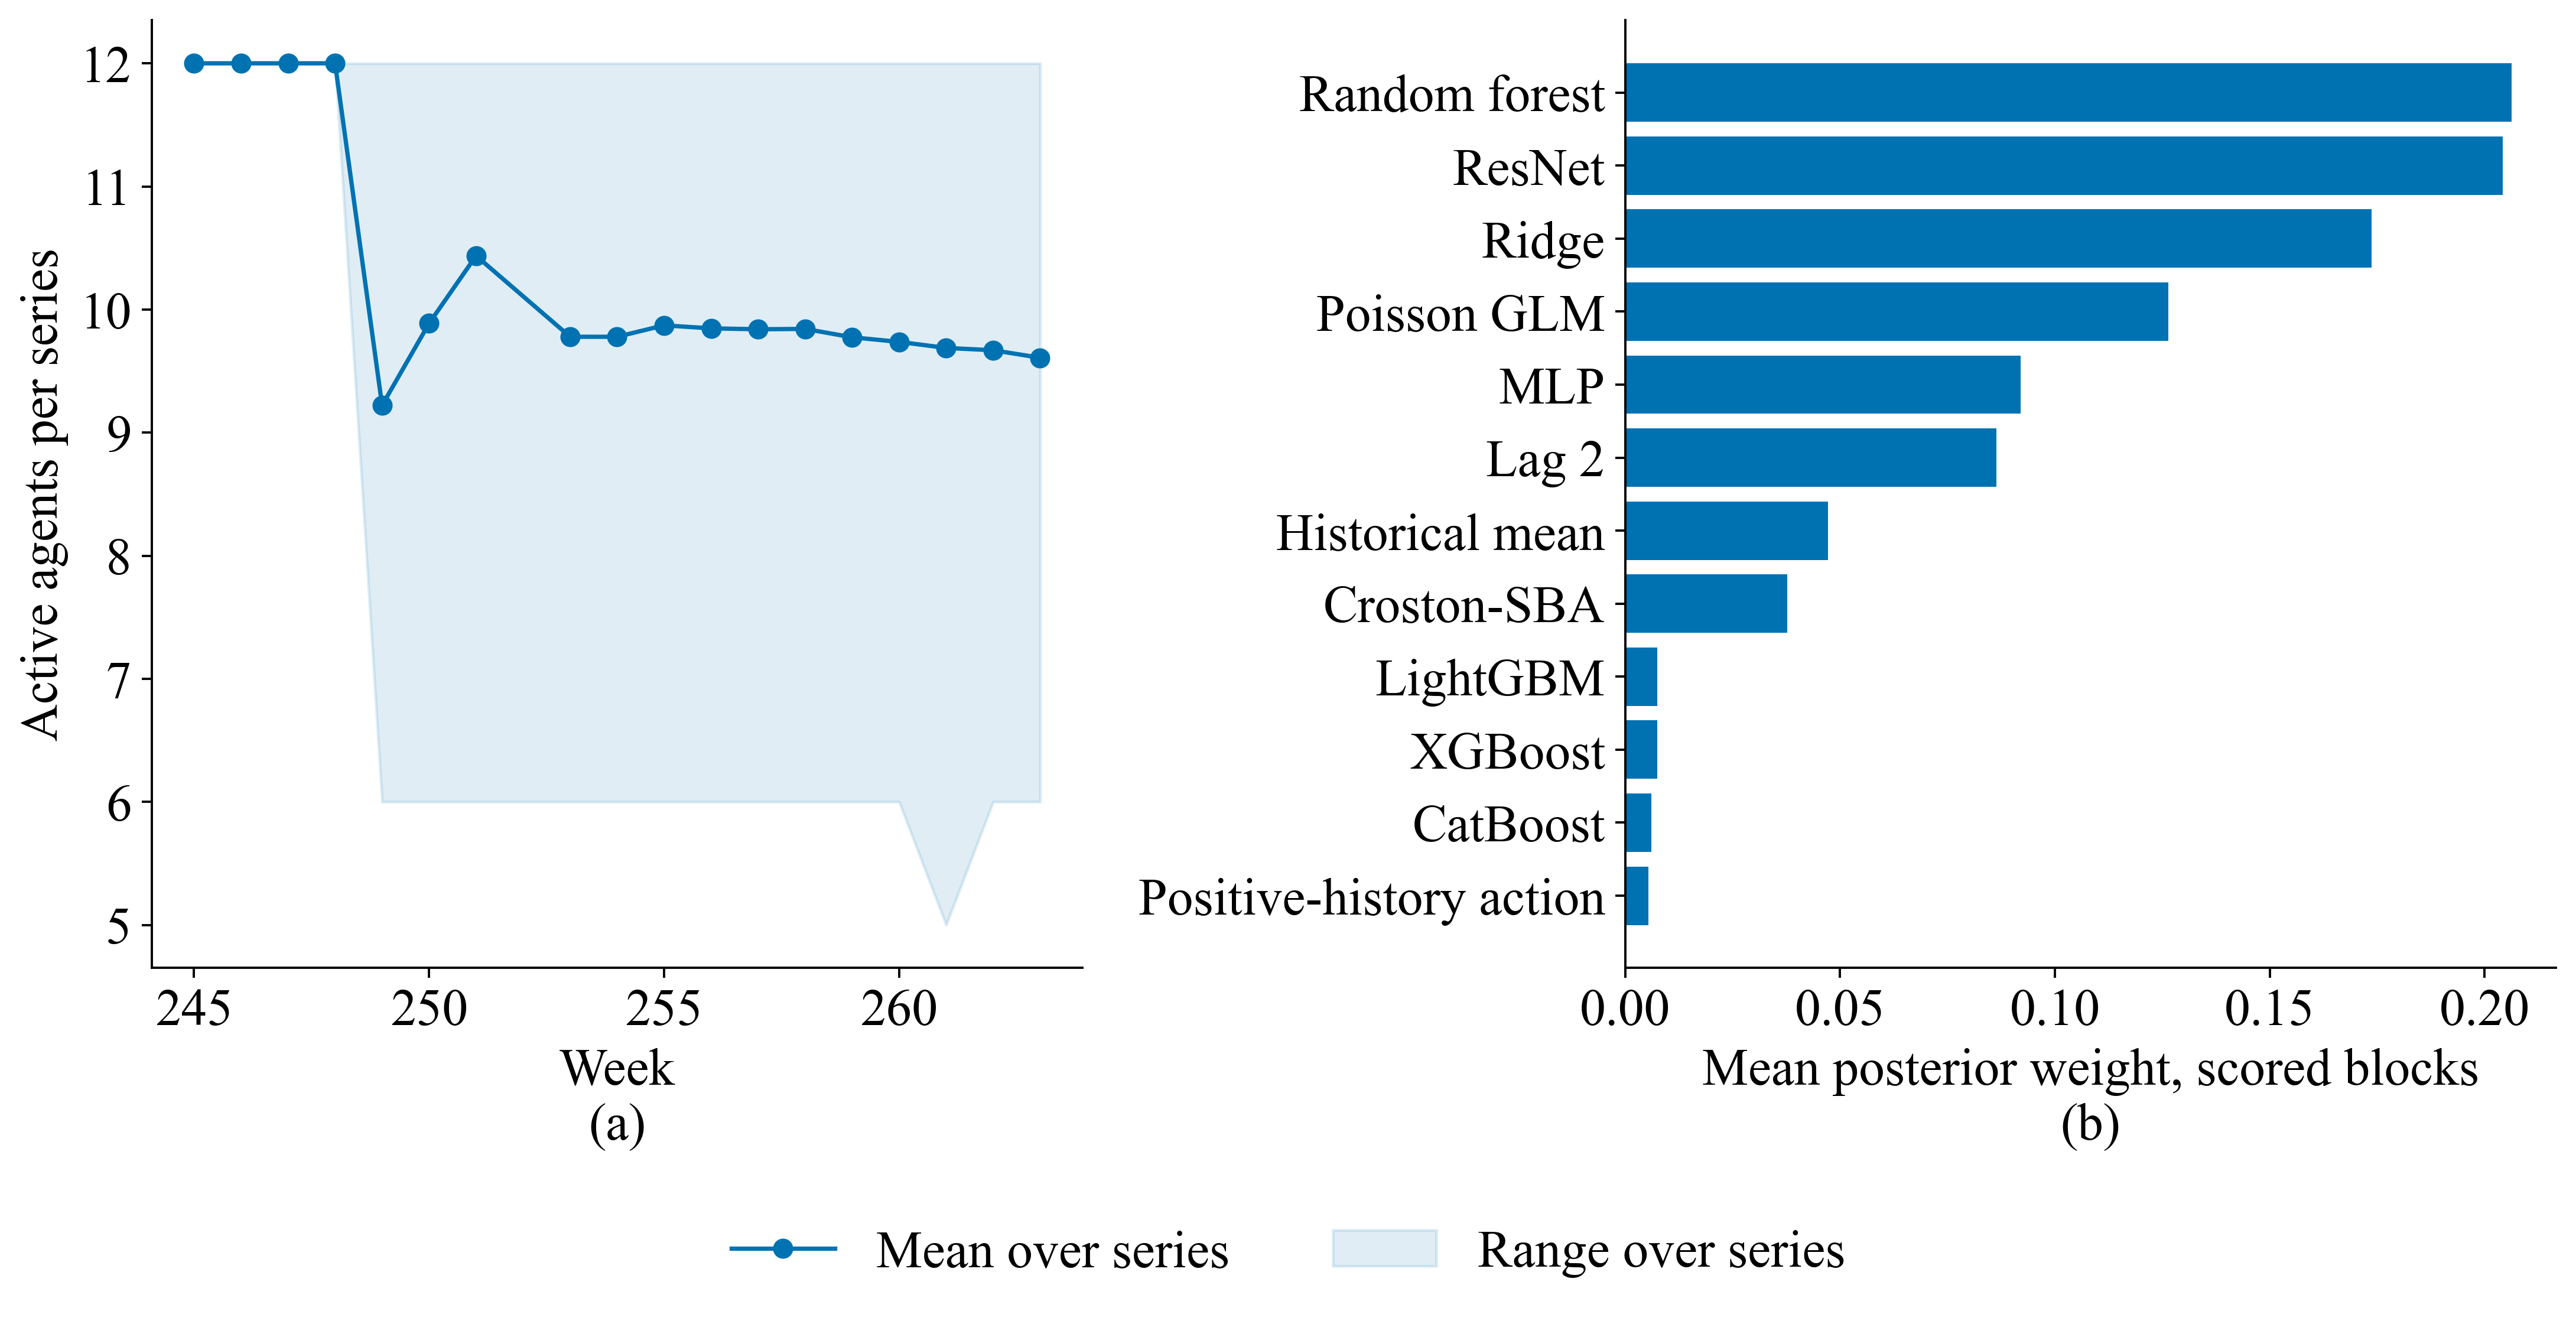

,Mean active agents,Minimum,Maximum,Series-agent deactivations,Series-agent reactivations
0,10.27646,5,12,178649,113005


,Agent,Mean weight,Active share
0,Random forest,0.20626,0.95447
1,ResNet,0.20416,0.95010
2,Ridge,0.17364,0.94365
3,Poisson GLM,0.12639,0.85795
4,MLP,0.09201,0.91693
5,Lag 2,0.08638,0.93123
6,Historical mean,0.04722,0.91585
7,Croston-SBA,0.03775,0.86147
8,LightGBM,0.00751,0.60551
9,XGBoost,0.00750,0.60834


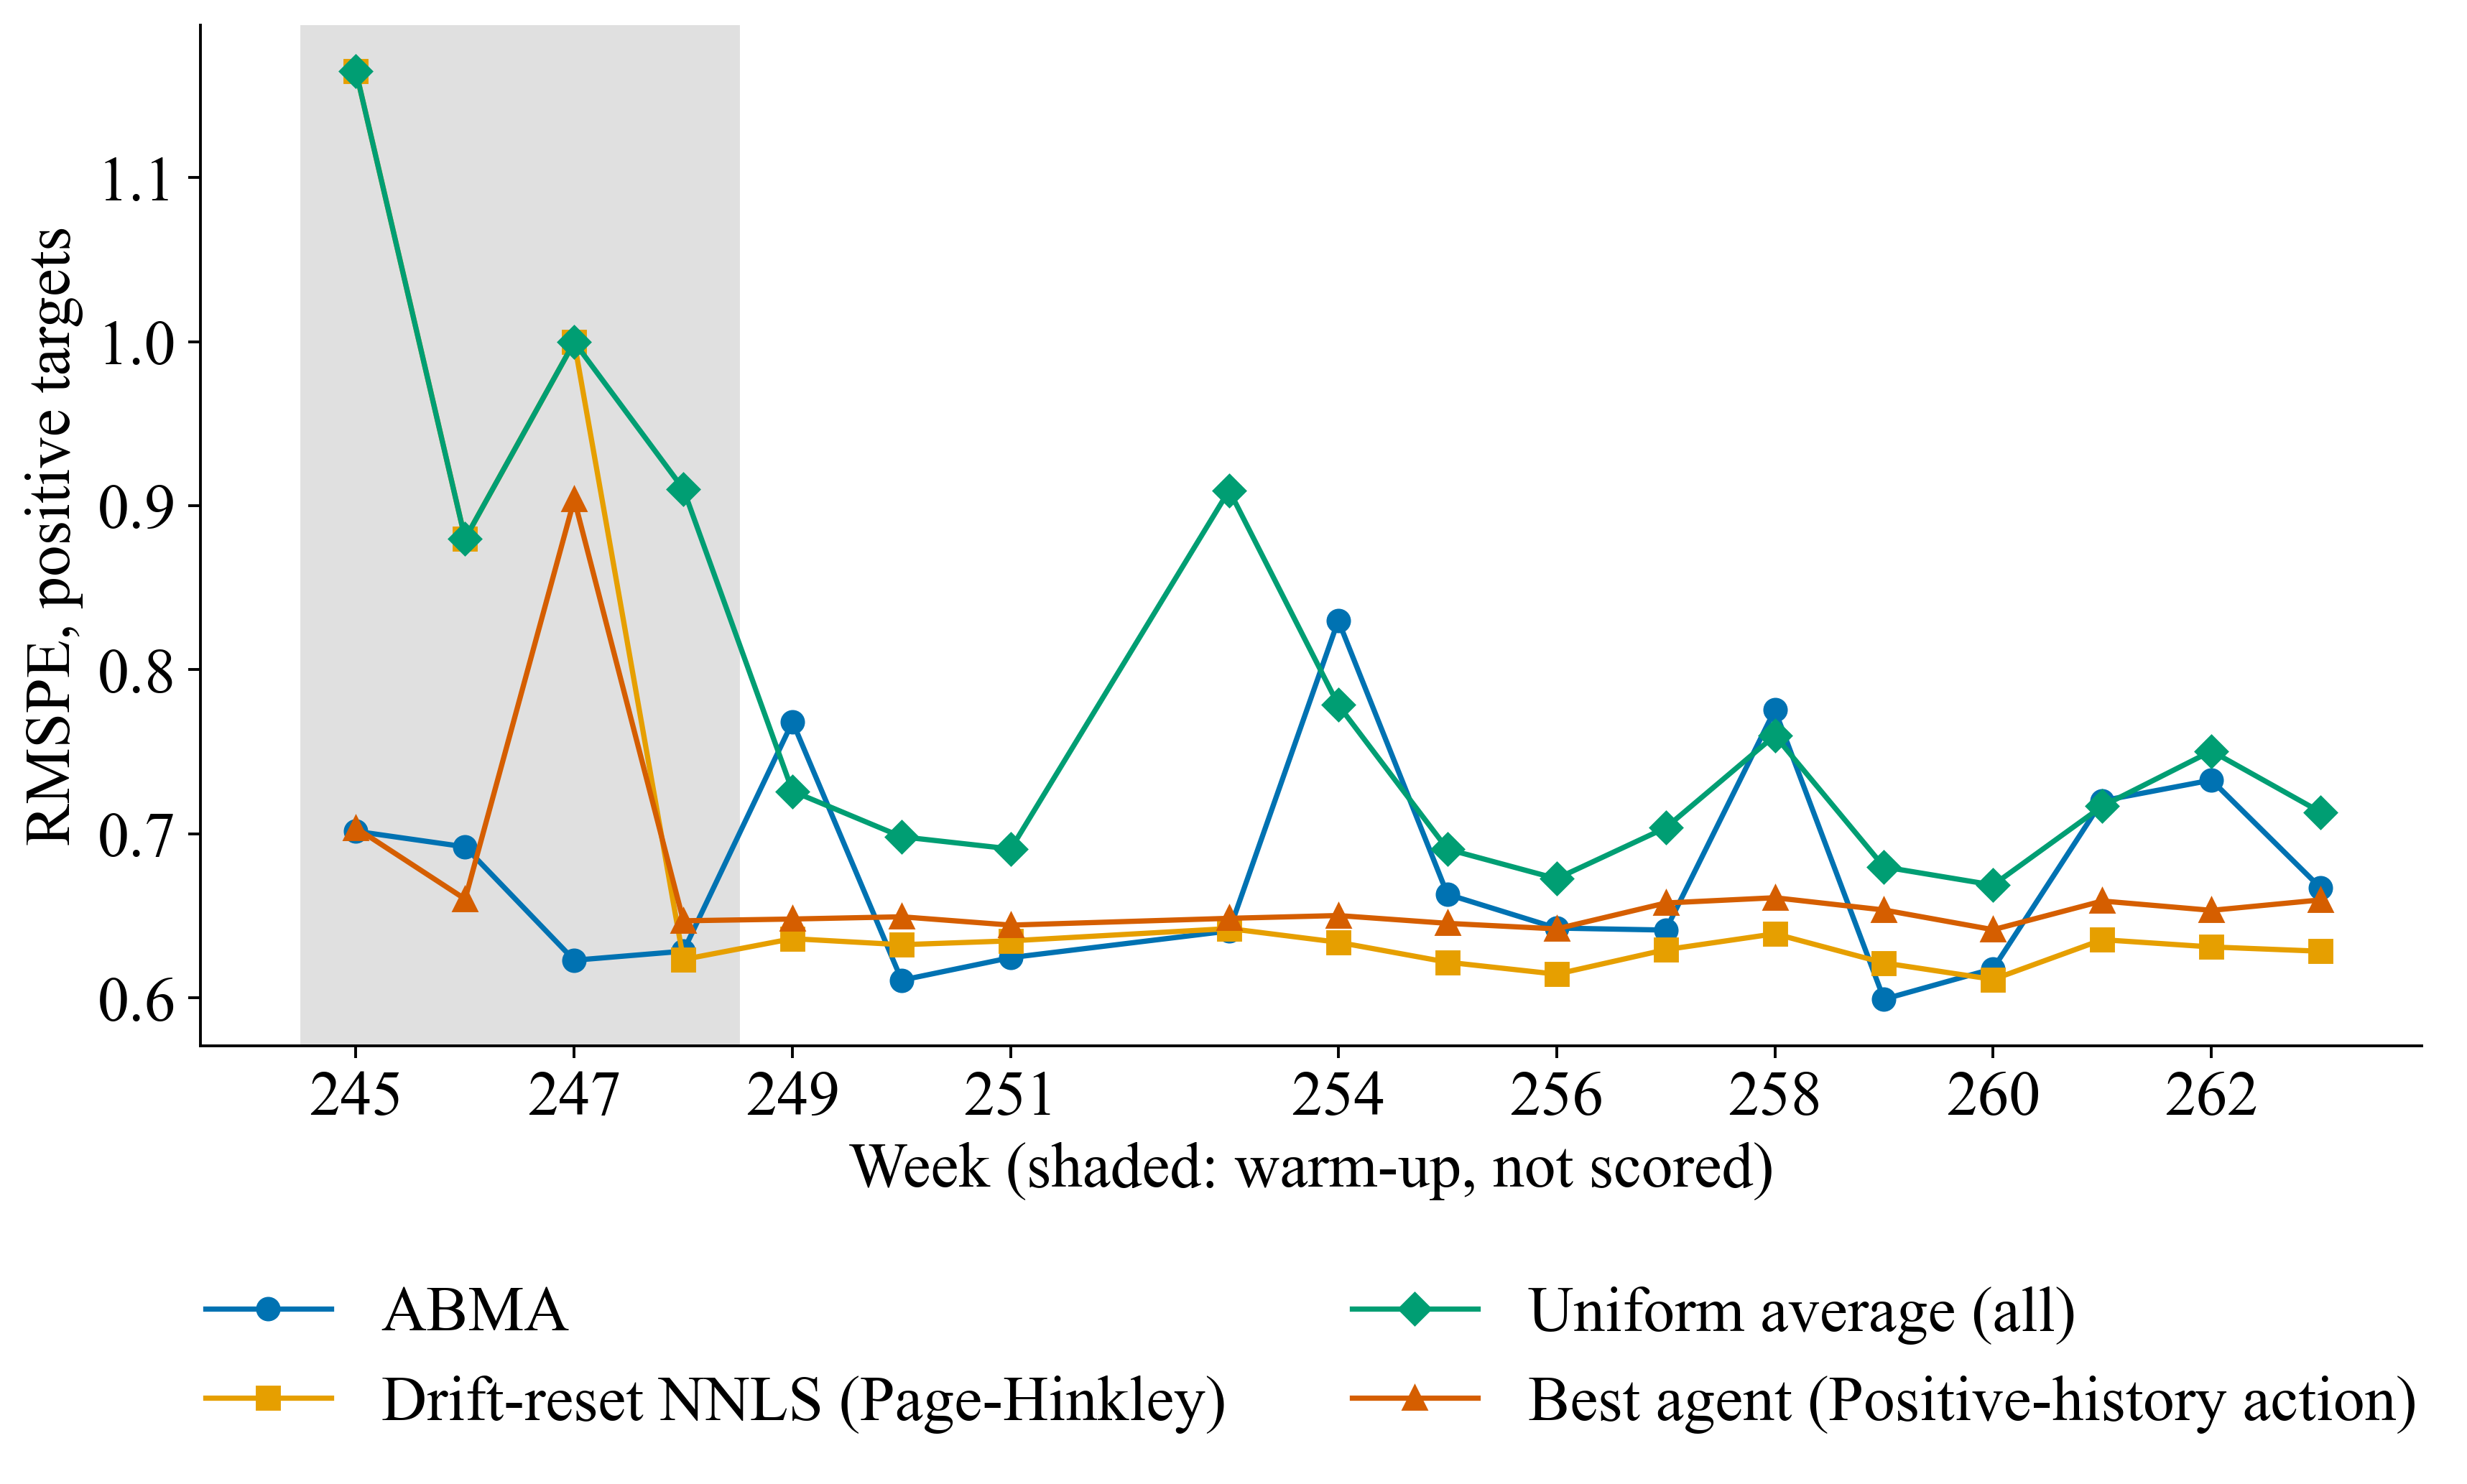

In [8]:
# NB05_DYNAMICS
active=abma_tr['ACT'].sum(1);weekly_active=pd.DataFrame({'week':wk,'active':active}).groupby('week')['active'].agg(['mean','min','max']);mean_w=pd.DataFrame(abma_tr['W'],columns=AGENTS)[scored].mean().sort_values();act_share=pd.DataFrame(abma_tr['ACT'],columns=AGENTS)[scored].mean()
fig,axes=plt.subplots(1,2,figsize=(12.8,6.6));axes[0].plot(weekly_active.index,weekly_active['mean'],color=PALETTE[0],marker='o',label='Mean over series');axes[0].fill_between(weekly_active.index,weekly_active['min'],weekly_active['max'],color=PALETTE[0],alpha=0.12,label='Range over series');axes[0].set(xlabel='Week',ylabel='Active agents per series')
axes[1].barh(range(len(mean_w)),mean_w.to_numpy(),color=PALETTE[0]);axes[1].set_yticks(range(len(mean_w)),mean_w.index);axes[1].set(xlabel='Mean posterior weight, scored blocks');h0,l0=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h0,l0,loc='lower center',ncol=2,frameon=False);fig.tight_layout(rect=[0,0.09,1,1]);figure(fig,'fig_m5_population_and_weights')
frame=pd.DataFrame(abma_tr['ACT'],columns=AGENTS);frame['s']=stream.Store.to_numpy();flips_off=flips_on=0
for a in AGENTS:d=np.concatenate(frame.groupby('s')[a].apply(lambda v:np.diff(v.to_numpy().astype(int))).to_list());flips_off+=int((d==-1).sum());flips_on+=int((d==1).sum())
table(pd.DataFrame([{'Mean active agents':float(active.mean()),'Minimum':int(active.min()),'Maximum':int(active.max()),'Series-agent deactivations':flips_off,'Series-agent reactivations':flips_on}]),'population_dynamics',fmt='%.2f');GATE_FIRED=flips_off>0 and flips_on>0
table(pd.DataFrame({'Agent':mean_w.index[::-1],'Mean weight':mean_w.to_numpy()[::-1],'Active share':act_share.reindex(mean_w.index[::-1]).to_numpy()}),'agent_weights')
BEST_COMB=str(board[board.Model.str.startswith('C: ')&~board.Model.str.contains('Best single')].iloc[0].Model);show={'ABMA':fc['ABMA'],BEST_COMB[3:]:fc[BEST_COMB],'Uniform average (all)':fc['C: Uniform average (all agents)'],f'Best agent ({BEST_SINGLE})':fc['B: '+BEST_SINGLE]}
fig,ax=plt.subplots(figsize=(10.5,6.4))
for (n,v),col,mk in zip(show.items(),PALETTE,'osD^'):ax.plot(weeks_all,[rmspe(y[wk==w],v[wk==w]) for w in weeks_all],color=col,marker=mk,label=n)
ax.axvspan(244.5,248.5,color='0.88',zorder=0);ax.set(xlabel='Week (shaded: warm-up, not scored)',ylabel='RMSPE, positive targets');ax.set_xticks(weeks_all[::2]);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_m5_development_weekly')

### 7. Stress test: a faulty agent

From W253 to W256 the LightGBM forecast is multiplied by 1.4 for a random third of the series.

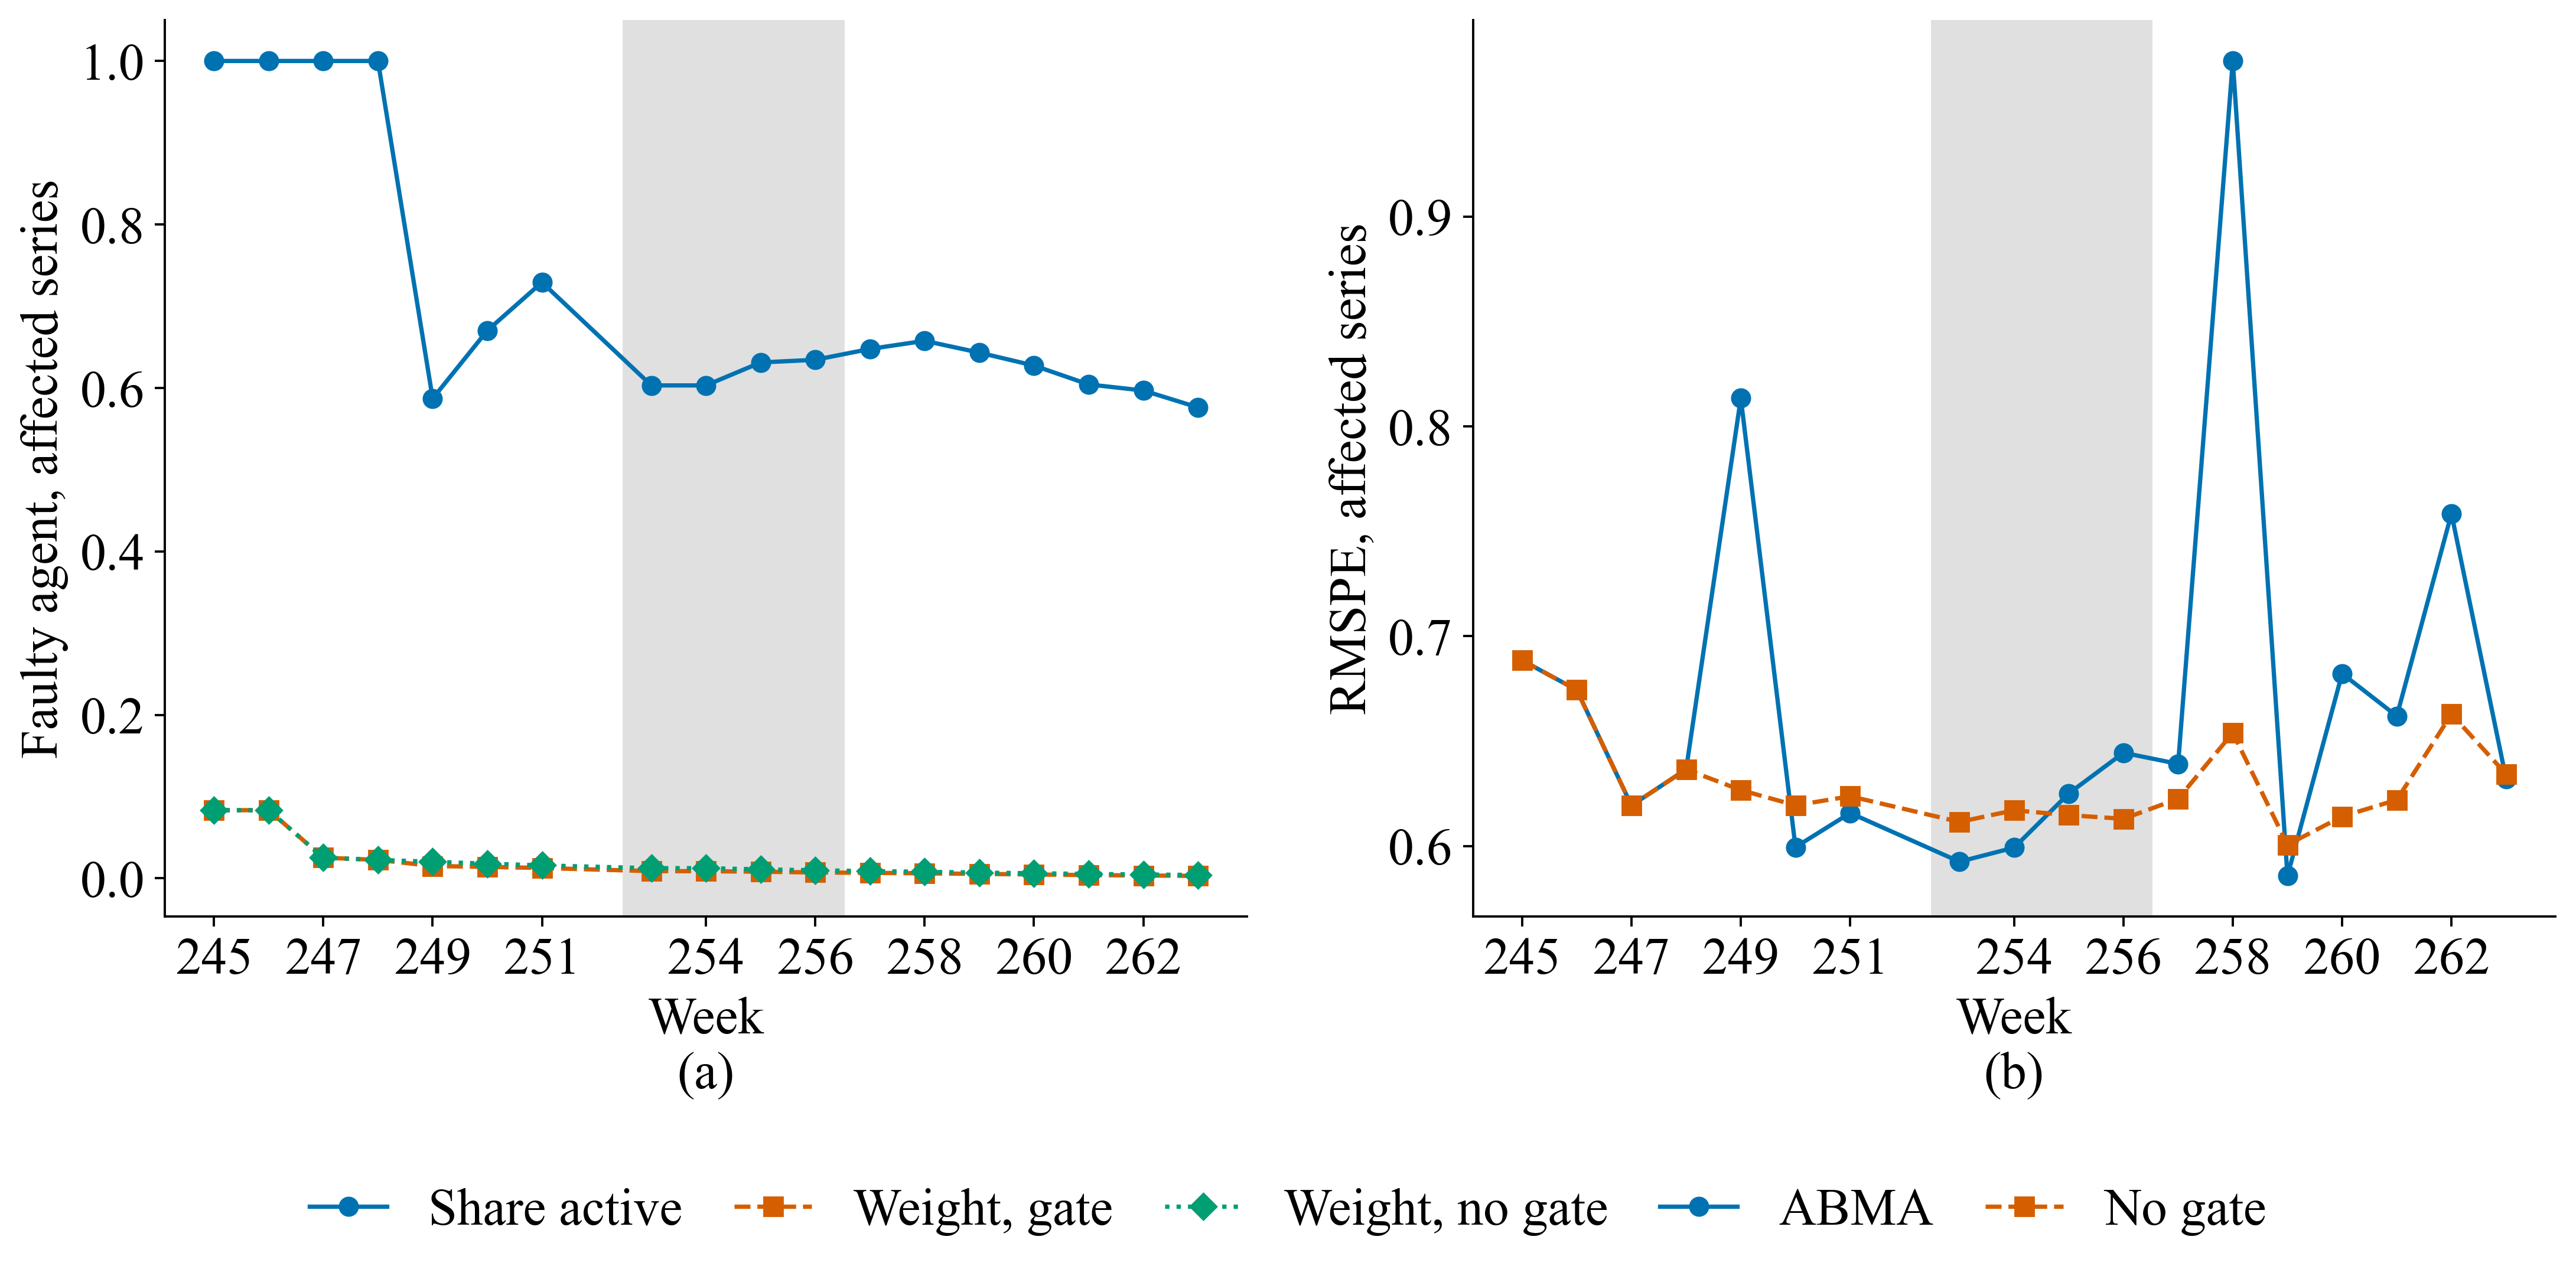

,"Rows in fault window (W253–W258, affected series)","RMSPE, with gate","RMSPE, no gate",Active share before (W249–W254),Active share W257–W258,Active share W261–W263
0,54882,0.69240,0.62229,0.63848,0.65262,0.59240


In [9]:
# NB05_FAULT
fault=Pq.copy();gen_f=np.random.default_rng(SEED);hit=gen_f.choice(stream.Store.unique(),stream.Store.nunique()//3,replace=False);in_hit=stream.Store.isin(hit).to_numpy();kL=AGENTS.index('LightGBM');fault_rows=stream.week.between(253,256).to_numpy()&in_hit;fault[fault_rows,kL]*=1.4
g_on,tr_on=abma_run(stream,fault,ABMA_CFG);g_off,tr_off=abma_run(stream,fault,{**ABMA_CFG,'gate_on':False})
dd=pd.DataFrame({'week':wk,'hit':in_hit,'active':tr_on['ACT'][:,kL],'w_on':tr_on['W'][:,kL],'w_off':tr_off['W'][:,kL],'e_on':np.where(pos,((g_on-y)/np.where(pos,y,1))**2,np.nan),'e_off':np.where(pos,((g_off-y)/np.where(pos,y,1))**2,np.nan)});day=dd[dd.hit].groupby('week').agg(active=('active','mean'),w_on=('w_on','mean'),w_off=('w_off','mean'),e_on=('e_on','mean'),e_off=('e_off','mean'))
fig,axes=plt.subplots(1,2,figsize=(12.8,6.4));axes[0].plot(day.index,day['active'],color=PALETTE[0],marker='o',label='Share active');axes[0].plot(day.index,day['w_on'],color=PALETTE[3],ls='--',marker='s',label='Weight, gate');axes[0].plot(day.index,day['w_off'],color=PALETTE[2],ls=':',marker='D',label='Weight, no gate');axes[0].set(xlabel='Week',ylabel='Faulty agent, affected series')
axes[1].plot(day.index,np.sqrt(day['e_on']),color=PALETTE[0],marker='o',label='ABMA');axes[1].plot(day.index,np.sqrt(day['e_off']),color=PALETTE[3],ls='--',marker='s',label='No gate');axes[1].set(xlabel='Week',ylabel='RMSPE, affected series')
for ax in axes:ax.axvspan(252.5,256.5,color='0.88',zorder=0);ax.set_xticks(weeks_all[::2])
h0,l0=axes[0].get_legend_handles_labels();h1,l1=axes[1].get_legend_handles_labels();label_panels(axes);fig.legend(h0+h1,l0+l1,loc='lower center',ncol=5,frameon=False,columnspacing=1.0,handlelength=1.5);fig.tight_layout(rect=[0,0.10,1,1]);figure(fig,'fig_m5_fault_response')
u=stream.week.between(253,258).to_numpy()&in_hit;table(pd.DataFrame([{'Rows in fault window (W253–W258, affected series)':int(u.sum()),'RMSPE, with gate':rmspe(y[u],g_on[u]),'RMSPE, no gate':rmspe(y[u],g_off[u]),'Active share before (W249–W254)':float(day.loc[249:254,'active'].mean()),'Active share W257–W258':float(day.loc[257:258,'active'].mean()),'Active share W261–W263':float(day.loc[261:263,'active'].mean())}]),'fault_test')

### 8. Predictive intervals with the frozen scale

,Block,Rows,PICP90,Coverage error,MPIW90,Interval score,Zero-target coverage
0,F2,82323,0.94502,0.04502,13.74353,22.28185,0.94870
1,D,301851,0.93251,0.03251,12.92104,25.03364,0.95153
2,Pooled (F2+D),384174,0.93519,0.03519,13.09729,24.44397,0.95091


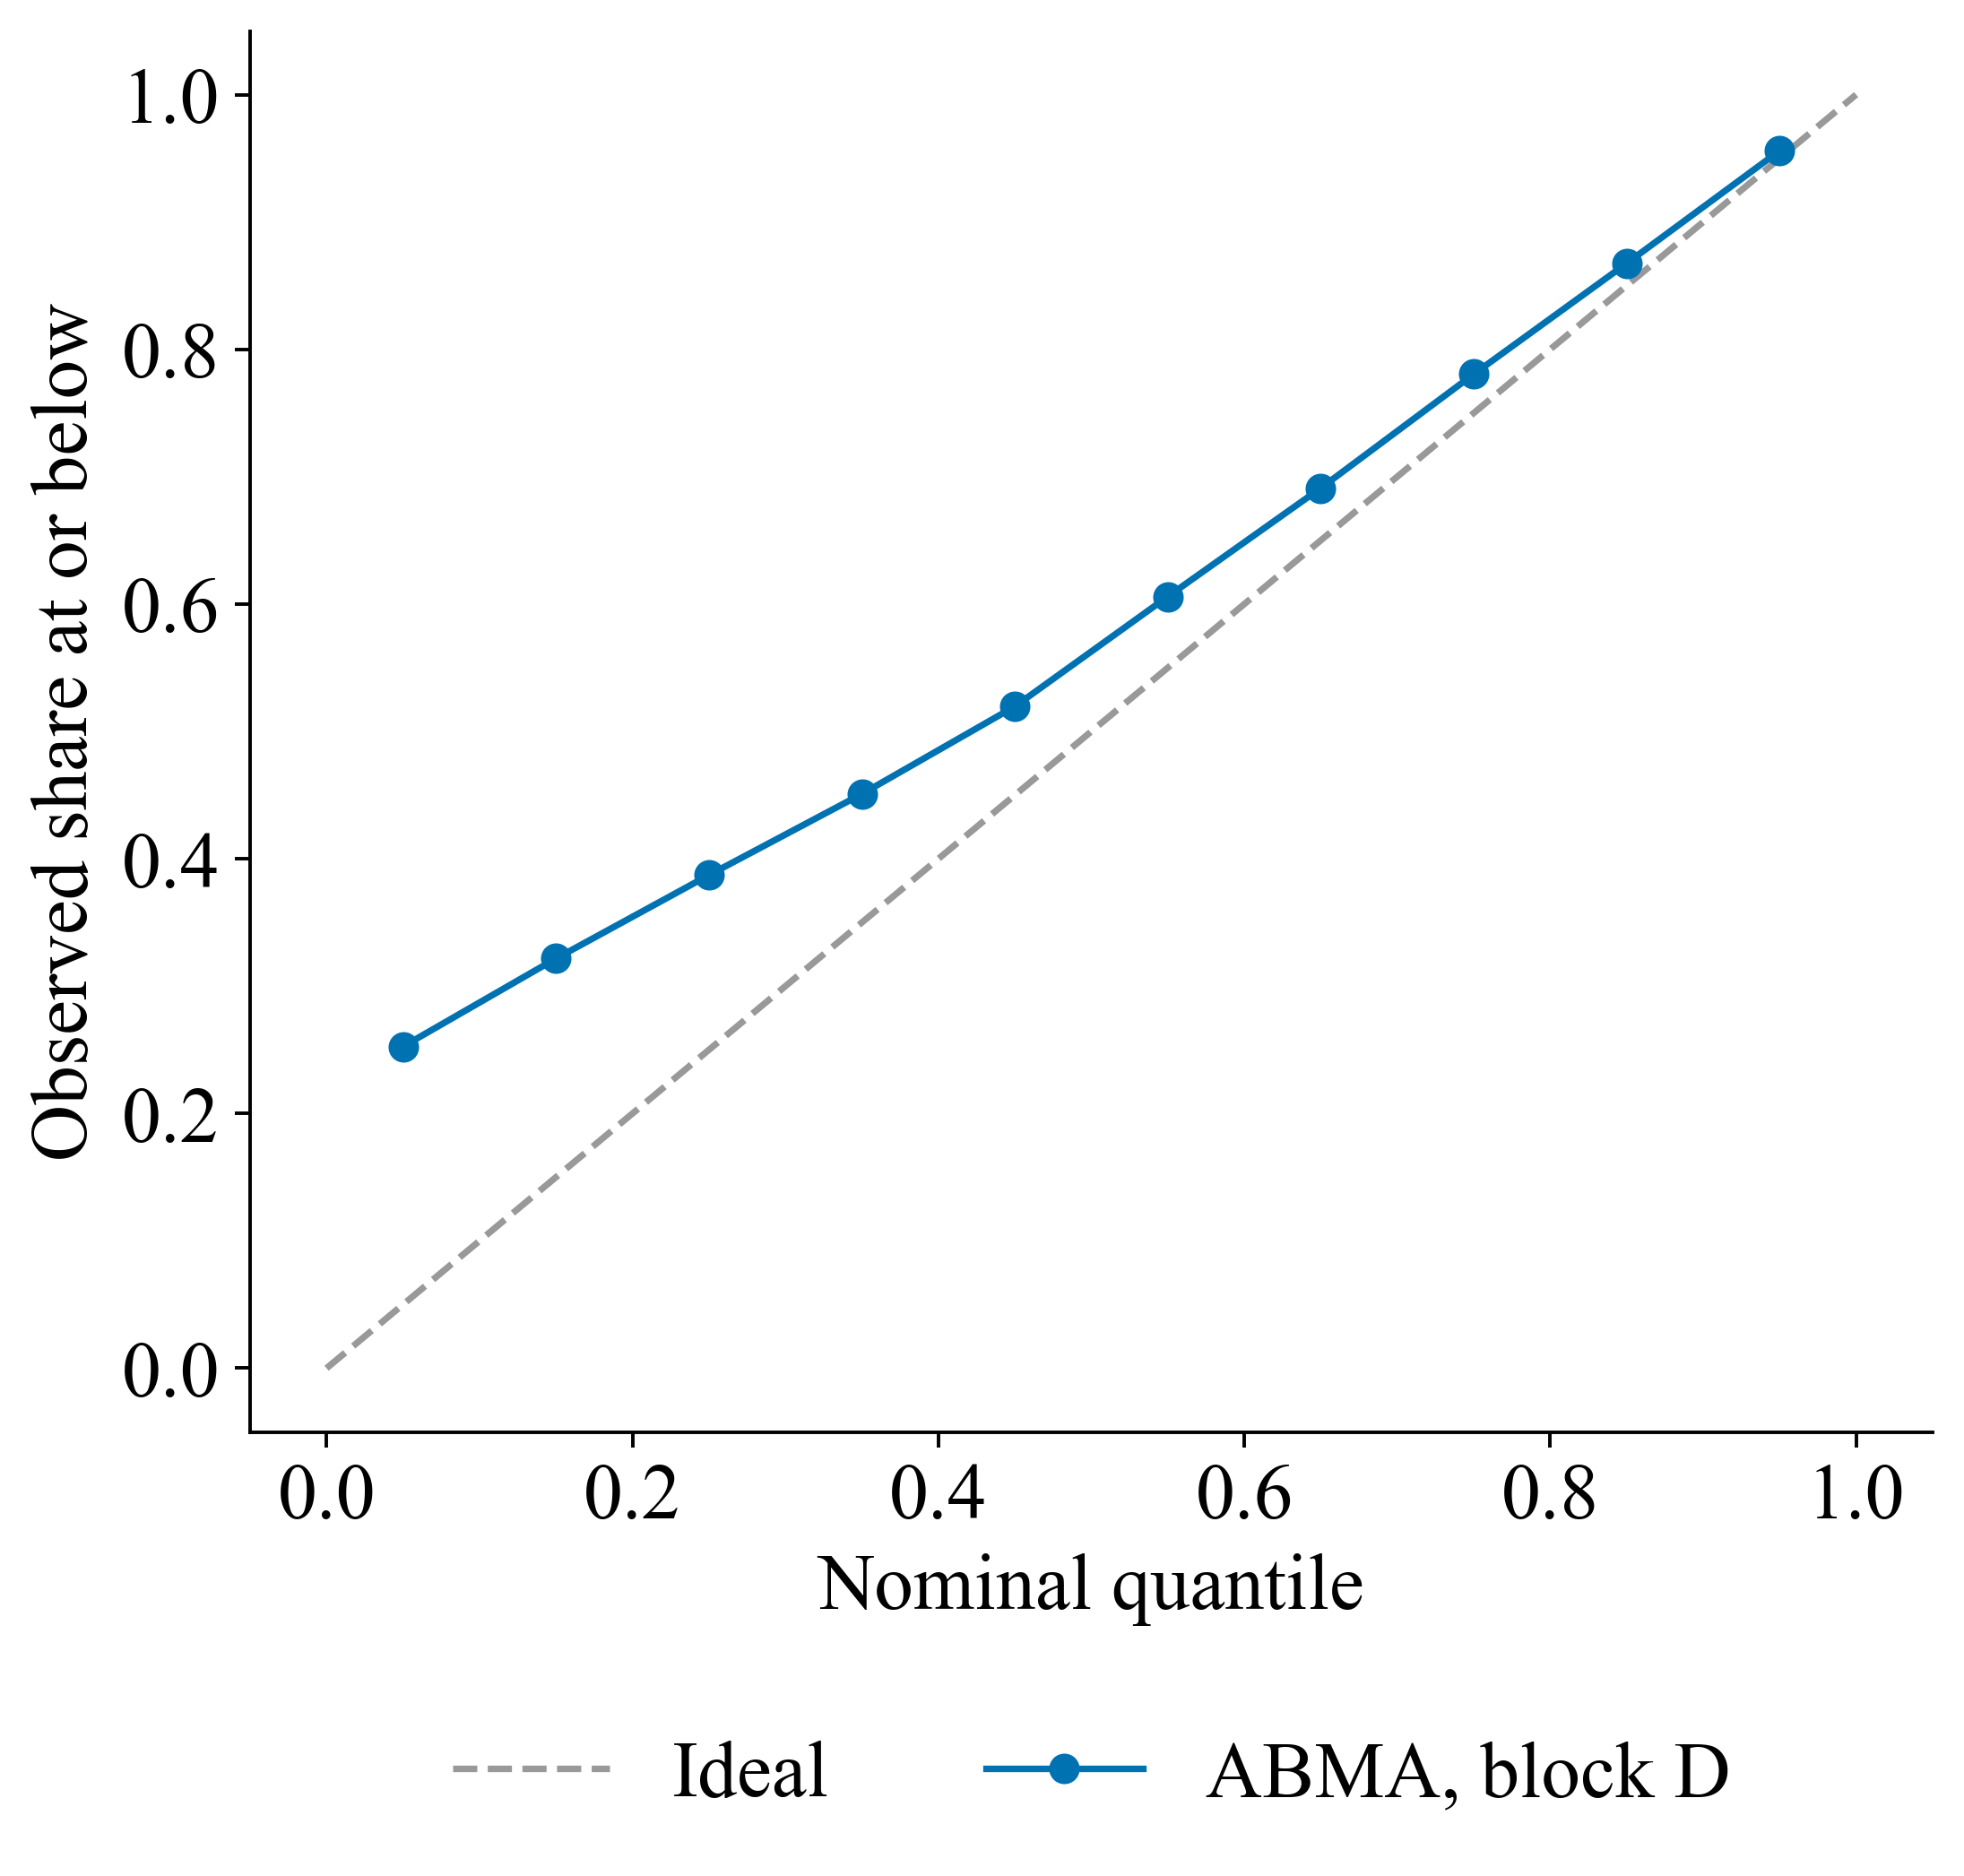

In [10]:
# NB05_INTERVALS
def mix_q(mk,q,scale=FROZEN['pi_scale']):return mixture_quantile(abma_tr['W'][mk],abma_tr['MU'][mk],abma_tr['SG'][mk],q,count=(abma_tr['P'][mk],abma_tr['LAW']*scale,abma_tr['LAW_IDX'][mk]))
pis=[]
for b in SCORED+['Pooled (F2+D)']:
    mk=scored if b.startswith('Pooled') else mask[b];lo,hi=mix_q(mk,0.05),mix_q(mk,0.95);yy=y[mk];cov=float(np.mean((yy>=lo)&(yy<=hi)));width=hi-lo
    pis.append({'Block':b,'Rows':int(mk.sum()),'PICP90':cov,'Coverage error':abs(cov-0.9),'MPIW90':float(width.mean()),'Interval score':float(np.mean(width+20*np.maximum(lo-yy,0)+20*np.maximum(yy-hi,0))),'Zero-target coverage':float(np.mean(lo[yy==0]<=0))})
table(pd.DataFrame(pis),'interval_coverage')
pc=np.linspace(.05,.95,10);cov_curve=[float((y[mask['D']]<=mix_q(mask['D'],q)).mean()) for q in pc]
fig,ax=plt.subplots(figsize=(6.6,6.4));ax.plot([0,1],[0,1],color='0.6',ls='--',label='Ideal');ax.plot(pc,cov_curve,color=PALETTE[0],marker='o',label='ABMA, block D');ax.set(xlabel='Nominal quantile',ylabel='Observed share at or below');ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.17),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_m5_reliability_development')

### 9. Frozen settings for the final evaluation

In [11]:
# NB05_RECORD: settings and forecasts read by NB06
CONTROLS={'abma_cfg':ABMA_CFG,'agents':AGENTS,'net_names':NET_NAMES,'nnls':NN_CFG,'drift_nnls':PH_CFG,'dma':DMA_CFG,'fixed_share':FS_CFG,'dwm':DWM_CFG,'stack':STACK_CFG,'corrected':CORR,'top3':TOP3,'best_single':BEST_SINGLE,'pi_scale':FROZEN['pi_scale'],'blocks':BLOCKS,'scored_blocks':SCORED,'development_pooled_rmspe':{k:float(rmspe(y[scored],v[scored])) for k,v in fc.items()},'gate_fired_in_development':bool(GATE_FIRED),'stack_features':list(Xs.columns)}
dump(BASE/'Configs/m5_frozen_controls.json',CONTROLS)
stream[['row_id','id','week','quantity','block']].assign(**{a:Pq[:,i] for i,a in enumerate(AGENTS)}).to_parquet(OUT/'agent_forecasts.parquet',index=False)  # float64: NB06 replays the development stream to the last digit
stream[['row_id','id','week','quantity','block']].assign(**{k:v.astype(np.float32) for k,v in fc.items()}).to_parquet(OUT/'development_forecasts.parquet',index=False)
latest=json.loads((BASE/'Manifests/latest_runs.json').read_text());latest['NB05']=RUN_ID;dump(BASE/'Manifests/latest_runs.json',latest)

### 10. Arm B: the online layer adapted to the weekly panel, frozen before the sealed read

A fixed coordinate search on the agents, development stream and scored blocks of arm A selects the weight discount, weight scope, weight criterion, best-agent guard and tempering; the selected configuration is frozen as arm B.

In [12]:
# NB05B_SETUP
CTRL=json.loads((BASE/'Configs/m5_frozen_controls.json').read_text());NB05_OUT=OUT
weeks_all=np.sort(stream.week.unique())

### 11. Engines: arm A and arm B

Arm B keeps the count law, the gate, reactivation and the variance state of arm A and adds a decision-loss (Gibbs) weight criterion $w_k \propto \exp(-\eta_g G_k)$ on the discounted relative squared error of each agent, a series-specific weight scope and a best-agent guard.

In [13]:
# ABMA engine: every label of date d enters the state only at date d + lag.
from scipy import special

ABMA_DEFAULT = dict(lag=7, nctx=14, clip=0.5, sig_floor=0.03, sig_scale=1.0, disc_var=0.995, store_sigma=True,
                    bias_mode="none", q=1e-6, p0=5e-4,
                    weight_mode="global", eta=0.5, disc_w=0.98, store_shrink=30.0,
                    gate_on=True, reactivate=True, theta0=0.5, gate_p=0.7, disc_beta=0.98, min_active=3, kappa=2.5,
                    action="bayes", dispersion=True, gate_loss="log",
                    law="lognormal", n_res=257, disc_res=0.98, smooth=0.5)


def abma_run(stream, P, cfg=None):
    """stream: Store, Date, Sales, ctx sorted by Date; P: n x K positive agent forecasts (NaN = agent absent).
    law = "lognormal": the predictive law of each agent is lognormal on log Sales (positive continuous targets).
    law = "count": Sales and P are non-negative counts; the lognormal state works on log(1 + count) and the predictive law of each agent is an
    empirical count law, y = max(0, round(p + sqrt(p + 1) r)) with r drawn from a discounted chain-wide reservoir of the agent's scaled residuals
    (n_res weighted quantiles, discount disc_res); the weights use the log predictive mass of the observed count (Laplace smoothing `smooth`) and
    the Bayes action under the positive-target relative loss is E[1/y; y > 0] / E[1/y^2; y > 0] of the mixture of count laws."""
    c = {**ABMA_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        elif c["weight_mode"] == "global":
            lw = np.repeat(c["eta"] * L_g.mean(0, keepdims=True), len(ix), 0)
        elif c["weight_mode"] == "context":
            lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
            lw = c["eta"] * (L_g[cc] + lam * (L_s[s, cc] - L_g[cc]))
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    num += w[:, k] * np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    den += w[:, k] * np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                    continue
                yk = law_draws(k, ix)
                inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                num += w[:, k] * inv.mean(1)
                den += w[:, k] * (inv ** 2).mean(1)
            if c["action"] == "bayes":
                out[ix] = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                out[ix] = np.expm1((w * m0).sum(1))
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT)


def mixture_quantile(W, MU, SG, q, iters=40, count=None):
    """Quantile of the lognormal mixture, by bisection in log sales; with `count` = (P, LAW, LAW_IDX) from a count-law run, the weighted quantile of the mixture of empirical count laws (rows without a law fall back to the lognormal quantile minus one, clipped at zero)."""
    if count is not None:
        Pq, LAW, idx = count
        n, K = Pq.shape
        NQ = LAW.shape[2]
        out = np.full(n, np.nan)
        for a in range(0, n, 2048):
            ix = np.arange(a, min(n, a + 2048))
            lq = LAW[idx[ix]]
            ok = ~np.isnan(lq[:, :, 0])
            draws = np.maximum(0.0, np.rint(Pq[ix][:, :, None] + np.sqrt(Pq[ix][:, :, None] + 1.0) * np.nan_to_num(lq)))
            wts = np.where(ok, W[ix], 0.0)[:, :, None] * np.ones((1, 1, NQ)) / NQ
            flat = draws.reshape(len(ix), -1)
            wf = wts.reshape(len(ix), -1)
            o = np.argsort(flat, axis=1)
            fs = np.take_along_axis(flat, o, 1)
            cw = np.cumsum(np.take_along_axis(wf, o, 1), axis=1)
            tot = cw[:, -1:]
            pos = (cw >= q * tot).argmax(1)
            val = fs[np.arange(len(ix)), pos]
            none = tot[:, 0] <= 0
            if none.any():
                val[none] = np.maximum(0.0, _lognormal_quantile(W[ix][none], MU[ix][none], SG[ix][none], q, iters) - 1.0)
            out[ix] = val
        return out
    return _lognormal_quantile(W, MU, SG, q, iters)


def _lognormal_quantile(W, MU, SG, q, iters=40):
    lo, hi = (MU - 6 * SG).min(1), (MU + 6 * SG).max(1)
    for _ in range(iters):
        mid = (lo + hi) / 2
        cdf = (W * special.ndtr((mid[:, None] - MU) / SG)).sum(1)
        lo, hi = np.where(cdf < q, mid, lo), np.where(cdf < q, hi, mid)
    return np.exp((lo + hi) / 2)


# Streaming combiners from the data-stream literature, used as controls; they are not part of the frozen model and are outside the engine hash.
def _stream_index(stream):
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    return si, si.max() + 1, day, [np.where(di == d)[0] for d in range(len(dates))]


def fixed_share(stream, P, y, eta=10.0, alpha=0.01, scope="store", lag=7):
    """Fixed-share exponentially weighted average (Herbster and Warmuth, 1998): weights proportional to exp(-eta * cumulative loss) with a share alpha of the mass redistributed uniformly at every update; loss = squared relative error of the point forecast clipped at 1; weights per store or chain-wide; the log forecasts are combined; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    LW = np.zeros((S if scope == "store" else 1, K))
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            ok = ~np.isnan(lp[jx])
            loss = np.where(ok, np.minimum((np.exp(lp[jx] - ly[jx][:, None]) - 1) ** 2, 1.0), 0.0)
            r = si[jx] if scope == "store" else np.zeros(1, int)
            if scope == "store":
                LW[r] -= eta * loss
            else:
                LW[0] -= eta * loss.mean(0)
            if alpha > 0:
                w = np.exp(LW[r] - LW[r].max(1, keepdims=True))
                w /= w.sum(1, keepdims=True)
                LW[r] = np.log((1 - alpha) * w + alpha / K)
        r = si[ix] if scope == "store" else np.zeros(len(ix), int)
        lw = np.where(~np.isnan(lp[ix]), LW[r], -1e9)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def dwm(stream, P, y, beta=0.5, theta=0.01, eps=0.1, period=1, lag=7):
    """Dynamic weighted majority (Kolter and Maloof, 2007) adapted to a fixed pool of regression agents with store-specific weights: an agent errs on a day when its absolute relative error exceeds eps and its weight is multiplied by beta; every `period` days the weights are normalised to a maximum of one, agents below theta are removed, and if the ensemble itself erred in the period the removed agents are re-admitted with weight theta (the original creates a new learner there; the pool is fixed). Forecast = weighted mean of the log forecasts of the admitted agents; labels of day d enter at day d + lag."""
    n, K = P.shape
    lp, ly = np.log(P), np.log(y)
    si, S, day, days = _stream_index(stream)
    W, REM = np.ones((S, K)), np.zeros((S, K), bool)
    ens_err, n_days = np.zeros(S, bool), np.zeros(S, int)
    out = np.zeros(n)
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - lag:
            jx = days[ptr]
            ptr += 1
            s = si[jx]
            ok = ~np.isnan(lp[jx])
            err = ok & (np.abs(np.exp(lp[jx] - ly[jx][:, None]) - 1) > eps)
            W[s] = np.maximum(W[s] * np.where(err, beta, 1.0), 1e-12)
            ens_err[s] |= np.abs(out[jx] / y[jx] - 1) > eps
            n_days[s] += 1
            due = n_days[s] >= period
            if due.any():
                sd = s[due]
                Wd = W[sd] / W[sd].max(1, keepdims=True)
                REM[sd] |= Wd < theta
                back = ens_err[sd]
                if back.any():
                    REM[sd[back]] = False
                    Wd[back] = np.maximum(Wd[back], theta)
                W[sd] = Wd
                ens_err[sd] = False
                n_days[sd] = 0
        s = si[ix]
        ok = ~np.isnan(lp[ix])
        adm = ok & ~REM[s]
        adm = np.where(adm.any(1, keepdims=True), adm, ok)
        w = np.where(adm, W[s], 0.0)
        w /= np.maximum(w.sum(1, keepdims=True), 1e-300)
        out[ix] = np.exp((w * np.nan_to_num(lp[ix])).sum(1))
    return out


def drift_nnls(stream, P, y, window, lam, idx, delta=0.005, lam_ph=0.1, lag=7):
    """Rolling NNLS on relative errors (weekly refit from labels at least `lag` days old, ridge lam, history of `window` days or all) whose history is additionally cut at the last drift found by the Page-Hinkley test (Page, 1954: allowed drift delta, alarm threshold lam_ph) on the daily mean squared relative error of its own forecasts."""
    from scipy.optimize import nnls as _nnls
    idx = list(idx)
    K, n = len(idx), len(y)
    out = np.zeros(n)
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    rel = P[:, idx] / y[:, None]
    rows = [np.where(di == d)[0] for d in range(len(dates))]
    grams = [(rel[r].T @ rel[r], rel[r].sum(0)) for r in rows]
    reset = checked = 0
    x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
    for w0 in range(0, len(dates), 7):
        end = int(np.searchsorted(dates, dates[w0] - np.timedelta64(lag, "D"), side="right"))
        for d in range(checked, end):  # forecasts of these days were made in earlier weeks and their labels are now known
            r = rows[d]
            x = float((((out[r] - y[r]) / y[r]) ** 2).mean()) if len(r) else 0.0
            x_n += 1
            x_sum += x
            m_sum += x - x_sum / x_n - delta
            m_min = min(m_min, m_sum)
            if m_sum - m_min > lam_ph:
                reset = d + 1
                x_sum, x_n, m_sum, m_min = 0.0, 0, 0.0, 0.0
        checked = max(checked, end)
        start = max(0 if window is None else end - int(window), reset)
        now = np.concatenate(rows[w0:w0 + 7])
        if end - start < 7:
            out[now] = P[now][:, idx].mean(1)
            continue
        G = sum(g[0] for g in grams[start:end]) + lam * np.eye(K)
        h = sum(g[1] for g in grams[start:end])
        L = np.linalg.cholesky(G)
        beta = _nnls(L.T, np.linalg.solve(L, h), maxiter=200)[0]
        out[now] = P[now][:, idx] @ beta if beta.sum() > 0 else P[now][:, idx].mean(1)
    return out

In [14]:
# Arm B of the M5 cycle: the online layer of the ABMA engine with three optional additions
# (decision-loss weights, series-specific weight scope already in the engine, best-agent guard). Requires the names of the ABMA engine cell (ABMA_DEFAULT, np, special).
# With the default options abma_run_b reproduces abma_run bitwise.
import numpy as np
from scipy import special

ABMA_B_DEFAULT = dict(score="logmass", eta_g=1.0, gibbs_clip=4.0, guard=None, guard_min=4)


def abma_run_b(stream, P, cfg=None):
    """Arm B of the M5 cycle: abma_run with three optional additions, each off by default so that the
    default run reproduces abma_run bitwise. score = "gibbs" | "product": generalised-Bayes weights from the discounted relative squared error of each
    agent's point forecast on positive targets (clipped at gibbs_clip, temperature eta_g), alone or multiplied with the log predictive mass; guard = margin:
    per series the discounted relative loss of the unguarded mixture action is compared with that of the leading active agent (at least guard_min positive
    labels) and the leader's own count-law Bayes action is used while the mixture trails it by more than the margin (count law only)."""
    c = {**ABMA_DEFAULT, **ABMA_B_DEFAULT, **(cfg or {})}
    n, K = P.shape
    N = c["nctx"]
    si = np.unique(stream["Store"].to_numpy(), return_inverse=True)[1]
    S = si.max() + 1
    dates, di = np.unique(stream["Date"].to_numpy(), return_inverse=True)
    day = dates.astype("datetime64[D]").astype(int)
    COUNT = c["law"] == "count"
    if COUNT:
        Pq = np.asarray(P, float)
        yq = stream["Sales"].to_numpy(float)
        y = np.log1p(yq)
        lp = np.log1p(Pq)
        NQ = int(c["n_res"])
        qgrid = (np.arange(NQ) + 0.5) / NQ
        rsv = [np.zeros(0) for _ in range(K)]
        rsv_w = [np.zeros(0) for _ in range(K)]
        law_q = np.full((K, NQ), np.nan)
        LAW = np.full((len(dates), K, NQ), np.nan)

        def law_update(k):
            o = np.argsort(rsv[k])
            cw = np.cumsum(rsv_w[k][o])
            cw /= cw[-1]
            return np.interp(qgrid, cw, rsv[k][o])

        def law_draws(k, ix):
            return np.maximum(0.0, np.rint(Pq[ix, k][:, None] + np.sqrt(Pq[ix, k][:, None] + 1.0) * law_q[k][None, :]))
    else:
        y = np.log(stream["Sales"].to_numpy(float))
        lp = np.log(P)
    C = stream["ctx"].to_numpy()
    bias, bias_var = np.zeros((S, K)), np.full((S, K), c["p0"])
    v_n, v_s = np.full((S, K), 5.0), np.full((S, K), 5 * 0.02)
    ctx_n, ctx_s = np.ones((N, K)), np.ones((N, K))
    L_g, L_s, n_s = np.zeros((N, K)), np.zeros((S, N, K)), np.zeros((S, N))
    G_g, G_s = np.zeros((N, K)), np.zeros((S, N, K))
    M_s, m_n, out_mix = np.zeros(S), np.zeros(S), np.zeros(n)
    USE_G = c["score"] != "logmass" or c["guard"] is not None
    assert c["guard"] is None or COUNT, "the guard is defined for the count law"
    a, b = np.ones((S, K)), np.ones((S, K))
    latched = np.zeros((S, K), bool)
    out = np.zeros(n)
    W, MU, SG = np.zeros((n, K), np.float32), np.zeros((n, K)), np.zeros((n, K))
    ACT = np.zeros((n, K), bool)
    days = [np.where(di == d)[0] for d in range(len(dates))]
    ptr = 0
    for d, ix in enumerate(days):
        while ptr < d and day[ptr] <= day[d] - c["lag"]:
            jx = days[ptr]
            ptr += 1
            s, cc, yy = si[jx], C[jx], y[jx][:, None]
            mu, sg, ok = MU[jx], np.maximum(SG[jx], 1e-3), ~np.isnan(lp[jx])
            ll = np.where(ok, np.maximum(-0.5 * ((yy - mu) / sg) ** 2 - np.log(sg), -12.0), 0.0)
            if COUNT:  # log predictive mass of the observed count under each agent's count law (lognormal score until the law exists)
                for k in range(K):
                    if np.isnan(law_q[k, 0]):
                        continue
                    hits = (np.abs(law_draws(k, jx) - yq[jx][:, None]) < 0.5).mean(1) * NQ
                    ll[:, k] = np.where(ok[:, k], np.log((hits + c["smooth"]) / (NQ + c["smooth"])), 0.0)
                r_new = np.where(ok, (yq[jx][:, None] - np.nan_to_num(Pq[jx])) / np.sqrt(np.nan_to_num(Pq[jx]) + 1.0), np.nan)
                for k in range(K):
                    rk = r_new[ok[:, k], k]
                    if len(rk) == 0:
                        continue
                    rsv[k] = np.concatenate([rsv[k], rk])
                    rsv_w[k] = np.concatenate([rsv_w[k] * c["disc_res"], np.ones(len(rk))])
                    if len(rsv[k]) > 40 * NQ:
                        rsv[k] = law_update(k)
                        rsv_w[k] = np.full(NQ, rsv_w[k].sum() / NQ)
                    law_q[k] = law_update(k)
            if USE_G:  # arm B: decision-loss criterion of each agent and of the unguarded mixture, positive targets only
                yr = yq[jx] if COUNT else np.exp(y[jx])
                pr = np.nan_to_num(Pq[jx] if COUNT else np.asarray(P, float)[jx])
                pj = yr > 0
                yd = np.where(pj, yr, 1.0)
                rel = np.minimum(np.where(ok & pj[:, None], ((pr - yr[:, None]) / yd[:, None]) ** 2, 0.0), c["gibbs_clip"])
                G_s[s, cc] = c["disc_w"] * G_s[s, cc] + rel
                for x in np.unique(cc):
                    G_g[x] = c["disc_w"] * G_g[x] + rel[cc == x].mean(0)
                if c["guard"] is not None:
                    relm = np.minimum(np.where(pj, ((out_mix[jx] - yr) / yd) ** 2, 0.0), c["gibbs_clip"])
                    M_s[s] = c["disc_w"] * M_s[s] + relm
                    m_n[s] = c["disc_w"] * m_n[s] + pj
            L_s[s, cc] = c["disc_w"] * L_s[s, cc] + ll
            n_s[s, cc] = c["disc_w"] * n_s[s, cc] + 1
            for x in np.unique(cc):
                L_g[x] = c["disc_w"] * L_g[x] + ll[cc == x].mean(0)
            if c.get("gate_loss", "log") == "log":  # default criterion: absolute log error
                ae = np.where(ok, np.abs(yy - mu), np.nan)
            else:  # alternative criterion: squared relative error of the point forecast, the loss of the Bayes action
                ae = np.where(ok, (np.exp(mu - yy) - 1) ** 2, np.nan)
            win = ae <= np.nanmedian(ae, axis=1, keepdims=True)
            keep = 1 - c["disc_beta"]
            a[s] = c["disc_beta"] * a[s] + keep + (win & ok)
            b[s] = c["disc_beta"] * b[s] + keep + (~win & ok)
            e = yy - lp[jx]
            for k in range(K):
                o = ok[:, k]
                sk = s[o]
                r = np.maximum(v_s[sk, k] / v_n[sk, k], 1e-4)
                pp = bias_var[sk, k] + c["q"]
                gain = pp / (pp + r)
                bias[sk, k] += gain * np.clip(e[o, k] - bias[sk, k], -c["clip"], c["clip"])
                bias_var[sk, k] = (1 - gain) * pp
                res = yy[o, 0] - (lp[jx][o, k] + (bias[sk, k] if c["bias_mode"] == "agent" else 0.0))
                sq = np.minimum(res ** 2, c["clip"] ** 2)
                v_n[sk, k] = c["disc_var"] * v_n[sk, k] + 1
                v_s[sk, k] = c["disc_var"] * v_s[sk, k] + sq
                for x in np.unique(cc[o]):
                    u = cc[o] == x
                    ctx_n[x, k] = 0.99 * ctx_n[x, k] + 1
                    ctx_s[x, k] = 0.99 * ctx_s[x, k] + (sq[u] / np.maximum(v_s[sk[u], k] / v_n[sk[u], k], 1e-4)).mean()
        s, cc = si[ix], C[ix]
        mu = lp[ix] + (bias[s] if c["bias_mode"] == "agent" else 0.0)
        var = v_s[s] / v_n[s] if c["store_sigma"] else np.broadcast_to((v_s / v_n).mean(0), (len(ix), K))
        sg = c["sig_scale"] * np.maximum(np.sqrt(var * ctx_s[cc] / ctx_n[cc]), c["sig_floor"])
        MU[ix], SG[ix] = mu, sg
        A = ~np.isnan(lp[ix])
        if c["gate_on"]:
            pl = special.betainc(a[s], b[s], c["theta0"])
            g = pl < c["gate_p"]
            if not c["reactivate"]:
                latched[s] |= ~g
                g = ~latched[s]
            few = g.sum(1) < c["min_active"]
            if few.any():
                best = np.argsort(pl[few], axis=1)[:, : c["min_active"]]
                gf = np.zeros((few.sum(), K), bool)
                np.put_along_axis(gf, best, True, axis=1)
                g[few] = gf
            A = A & g
        if c["kappa"] > 0:  # instantaneous gate: an active agent far from the consensus of the active pool is switched off for this row
            mu_act = np.where(A, np.nan_to_num(mu), np.nan)
            consensus = np.nanmedian(mu_act, axis=1, keepdims=True)
            pool_sd = np.sqrt(np.nanmedian(np.where(A, sg ** 2, np.nan), axis=1, keepdims=True))
            far = np.abs(np.nan_to_num(mu) - consensus) > c["kappa"] * np.maximum(sg, pool_sd)
            A2 = A & ~far
            A = np.where((A2.sum(1) >= c["min_active"])[:, None], A2, A)
        ACT[ix] = A
        if c["weight_mode"] == "uniform":
            lw = np.zeros((len(ix), K))
        else:
            if c["weight_mode"] == "global":
                Lw = np.repeat(L_g.mean(0, keepdims=True), len(ix), 0)
                Gw = np.repeat(G_g.mean(0, keepdims=True), len(ix), 0)
            else:
                lam = (n_s[s, cc] / (n_s[s, cc] + c["store_shrink"]))[:, None]
                Lw = L_g[cc] + lam * (L_s[s, cc] - L_g[cc])
                Gw = G_g[cc] + lam * (G_s[s, cc] - G_g[cc])
            if c["score"] == "logmass":
                lw = c["eta"] * Lw
            elif c["score"] == "gibbs":
                lw = -c["eta_g"] * Gw
            else:
                lw = c["eta"] * Lw - c["eta_g"] * Gw
        lw = np.where(A, lw, -np.inf)
        lw -= lw.max(1, keepdims=True)
        w = np.exp(lw)
        w /= w.sum(1, keepdims=True)
        W[ix] = w
        m0 = np.nan_to_num(mu)
        if COUNT:
            LAW[d] = law_q
            num, den = np.zeros(len(ix)), np.zeros(len(ix))
            NUMK, DENK = np.zeros((len(ix), K)), np.zeros((len(ix), K))
            for k in range(K):
                if np.isnan(law_q[k, 0]):  # no residual history yet: lognormal fallback on the shifted scale
                    NUMK[:, k] = np.exp(-m0[:, k] + 0.5 * sg[:, k] ** 2)
                    DENK[:, k] = np.exp(-2 * m0[:, k] + 2 * sg[:, k] ** 2)
                else:
                    yk = law_draws(k, ix)
                    inv = np.where(yk > 0, 1.0 / np.where(yk > 0, yk, 1.0), 0.0)
                    NUMK[:, k] = inv.mean(1)
                    DENK[:, k] = (inv ** 2).mean(1)
                num += w[:, k] * NUMK[:, k]
                den += w[:, k] * DENK[:, k]
            if c["action"] == "bayes":
                mix = np.where(den > 0, num / np.maximum(den, 1e-300), np.nan_to_num(Pq[ix]).mean(1))
            else:
                mix = np.expm1((w * m0).sum(1))
            out_mix[ix] = mix
            if c["guard"] is not None:  # arm B: the leading active agent replaces the mixture while the mixture trails it by more than the margin
                Gs = np.where(A, G_s[s, cc], np.inf)
                lead = Gs.argmin(1)
                rr = np.arange(len(ix))
                enough = (m_n[s] >= c["guard_min"]) & np.isfinite(Gs[rr, lead])
                worse = enough & (M_s[s] > (1.0 + c["guard"]) * Gs[rr, lead])
                lead_act = np.where(DENK[rr, lead] > 0, NUMK[rr, lead] / np.maximum(DENK[rr, lead], 1e-300), np.nan_to_num(Pq[ix])[rr, lead])
                out[ix] = np.where(worse, lead_act, mix)
            else:
                out[ix] = mix
            continue
        if c["action"] == "bayes":
            s2 = sg if c["dispersion"] else np.full_like(sg, np.sqrt((w * sg ** 2).sum(1, keepdims=True)))
            out[ix] = (w * np.exp(-m0 + 0.5 * s2 ** 2)).sum(1) / (w * np.exp(-2 * m0 + 2 * s2 ** 2)).sum(1)
        else:
            out[ix] = np.exp((w * m0).sum(1))
        out_mix[ix] = out[ix]
    if COUNT:
        return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, LAW=LAW, LAW_IDX=di, P=Pq, MIX=out_mix)
    return out, dict(W=W, MU=MU, SG=SG, ACT=ACT, MIX=out_mix)

In [15]:
# NB05B_FROZEN
CL=FROZEN['count_law'];CFG_A=CTRL['abma_cfg'];assert CFG_A=={**FROZEN['abma'],'lag':14,'nctx':1,'law':'count','n_res':CL['n_res'],'disc_res':CL['disc_res'],'smooth':CL['smooth']}
def run_b(cfg,Pm=None):return abma_run_b(stream,Pq if Pm is None else Pm,cfg)
t0=time.perf_counter();outA,trA=abma_run(stream,Pq,CFG_A);SEC_A=time.perf_counter()-t0

### 12. Coordinate search in a fixed order

Stages: weight discount, weight scope, weight criterion, best-agent guard and tempering; a candidate replaces the incumbent only if it lowers the pooled RMSPE of the scored blocks by more than 10⁻⁴.

stage 1 disc_w: disc_w 0.98 -> 0.68455 (32 s)


stage 1 disc_w: disc_w 0.95 -> 0.68399 (31 s)


stage 1 disc_w: disc_w 0.90 -> 0.68419 (32 s)


stage 2 weight_mode: context, shrink 10 -> 0.71059 (33 s)


stage 2 weight_mode: context, shrink 30 -> 0.69263 (31 s)


stage 3 score: gibbs, eta_g 1 -> 0.68325 (31 s)


... (5 outputs left out)

stage 4 guard: guard 0.05 -> 0.96739 (32 s)


stage 4 guard: guard 0.15 -> 0.96618 (32 s)


,Stage,Candidate,Change,Pooled RMSPE,RMSPE F2,RMSPE D,Seconds,Selected
0,0,arm A (incumbent),none,0.68488,0.67195,0.68833,30.02956,True
1,1,disc_w 0.98,"{""disc_w"": 0.98}",0.68455,0.67192,0.68792,31.86303,False
2,1,disc_w 0.95,"{""disc_w"": 0.95}",0.68399,0.67194,0.68721,31.41404,True
3,1,disc_w 0.90,"{""disc_w"": 0.9}",0.68419,0.67225,0.68738,31.73053,False
4,2,"context, shrink 10","{""weight_mode"": ""context"", ""store_shrink"": 10.0}",0.71059,0.67666,0.71950,32.71164,False
5,2,"context, shrink 30","{""weight_mode"": ""context"", ""store_shrink"": 30.0}",0.69263,0.67307,0.69782,30.84818,False
6,3,"gibbs, eta_g 1","{""score"": ""gibbs"", ""eta_g"": 1.0}",0.68325,0.67989,0.68416,31.18304,False
7,3,"gibbs, eta_g 3","{""score"": ""gibbs"", ""eta_g"": 3.0}",0.67574,0.67448,0.67609,31.42969,False
8,3,"gibbs, eta_g 10","{""score"": ""gibbs"", ""eta_g"": 10.0}",0.67194,0.66914,0.67270,30.98283,True
9,3,"product, eta 0.5, eta_g 1","{""score"": ""product"", ""eta_g"": 1.0}",0.67804,0.66940,0.68036,31.95001,False


,Stage,Selected
0,disc_w,disc_w 0.95
1,weight_mode,incumbent kept (arm-A value)
2,score,"gibbs, eta_g 10"
3,guard,incumbent kept (arm-A value)
4,eta,skipped (the selected criterion does not use the log mass)
5,arm B against arm A,"{""disc_w"": 0.95, ""score"": ""gibbs"", ""eta_g"": 10.0}"
6,"pooled RMSPE, arm A / arm B",0.68488 / 0.67194


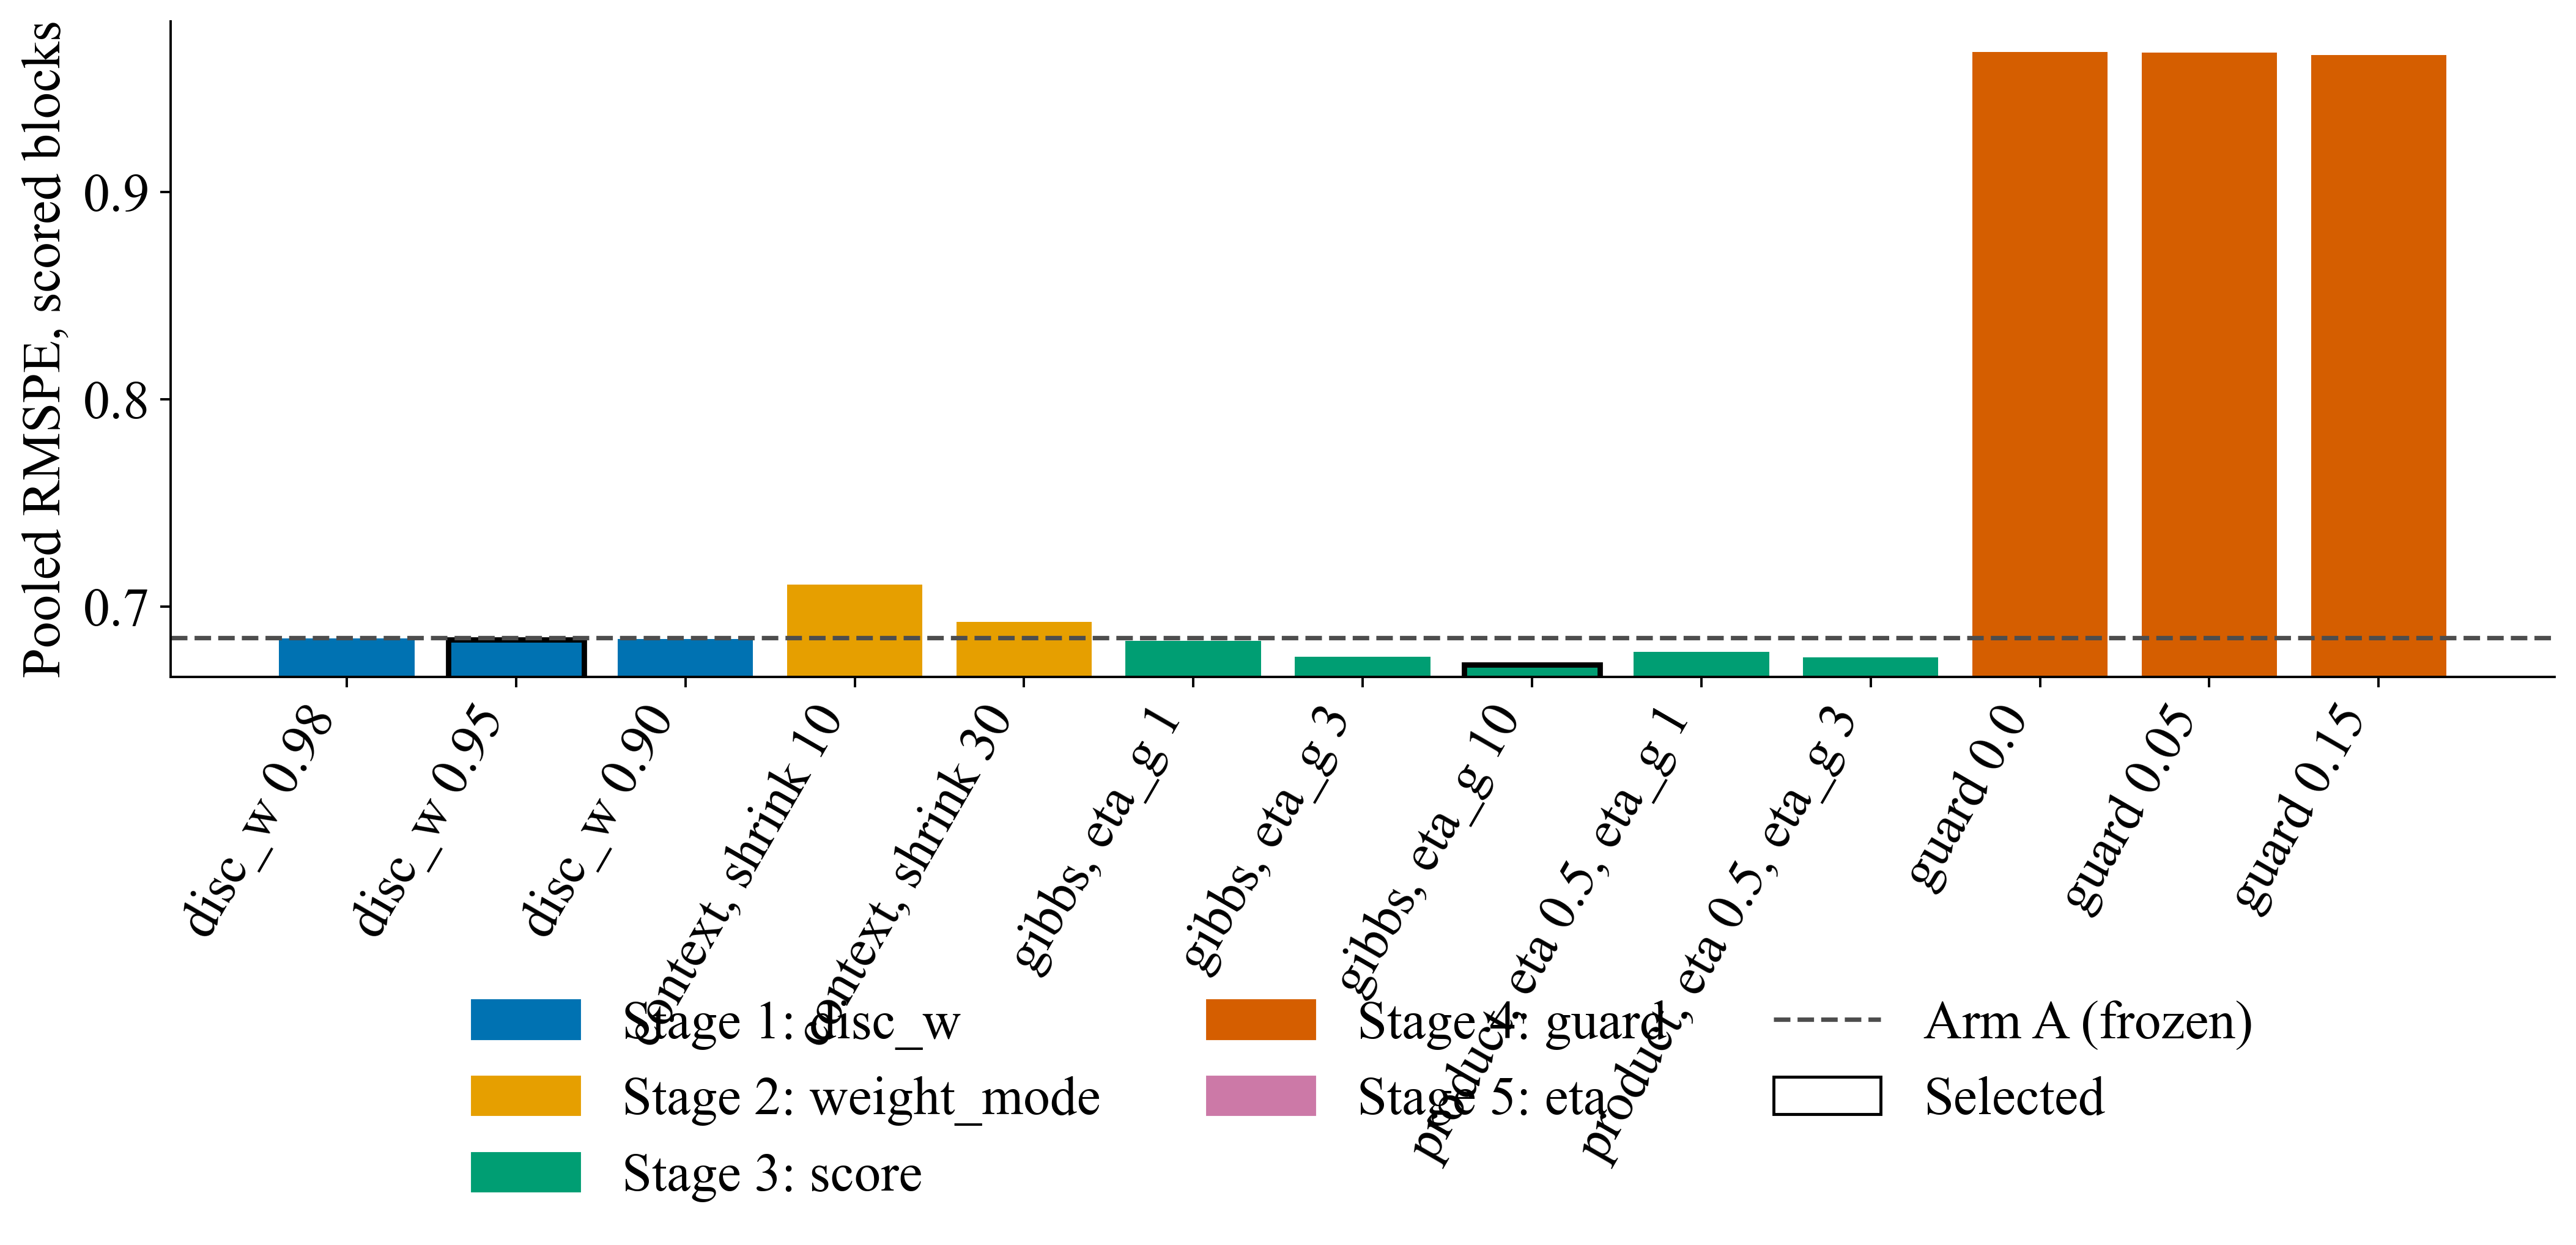

In [16]:
# NB05B_SEARCH
TOL=1e-4;TRIALS=[];inc=dict(CFG_A);inc_score=rmspe(y[scored],outA[scored]);SELECTED={}
def trial_row(stage,name,change,o,sec):return {'Stage':stage,'Candidate':name,'Change':change,'Pooled RMSPE':rmspe(y[scored],o[scored]),'RMSPE F2':rmspe(y[mask['F2']],o[mask['F2']]),'RMSPE D':rmspe(y[mask['D']],o[mask['D']]),'Seconds':sec,'Selected':False}
TRIALS.append({**trial_row(0,'arm A (incumbent)','none',outA,SEC_A),'Selected':True})
STAGES_B=[('disc_w',[('disc_w 0.98',{'disc_w':0.98}),('disc_w 0.95',{'disc_w':0.95}),('disc_w 0.90',{'disc_w':0.90})]),
 ('weight_mode',[('context, shrink 10',{'weight_mode':'context','store_shrink':10.0}),('context, shrink 30',{'weight_mode':'context','store_shrink':30.0})]),
 ('score',[('gibbs, eta_g 1',{'score':'gibbs','eta_g':1.0}),('gibbs, eta_g 3',{'score':'gibbs','eta_g':3.0}),('gibbs, eta_g 10',{'score':'gibbs','eta_g':10.0}),('product, eta 0.5, eta_g 1',{'score':'product','eta_g':1.0}),('product, eta 0.5, eta_g 3',{'score':'product','eta_g':3.0})]),
 ('guard',[('guard 0.0',{'guard':0.0}),('guard 0.05',{'guard':0.05}),('guard 0.15',{'guard':0.15})]),
 ('eta',[('eta 1.0',{'eta':1.0}),('eta 2.0',{'eta':2.0})])]
for n_stage,(stage,cands) in enumerate(STAGES_B,1):
    if stage=='eta' and inc.get('score','logmass')=='gibbs':SELECTED[stage]='skipped (the selected criterion does not use the log mass)';continue
    best_c,best_s,best_name=None,inc_score,None
    for name,c in cands:
        cfg={**inc,**c};t0=time.perf_counter();o=run_b(cfg)[0];row=trial_row(n_stage,name,json.dumps(c),o,time.perf_counter()-t0);TRIALS.append(row);print(f"stage {n_stage} {stage}: {name} -> {row['Pooled RMSPE']:.5f} ({row['Seconds']:.0f} s)",flush=True)
        if row['Pooled RMSPE']<best_s-TOL:best_c,best_s,best_name=c,row['Pooled RMSPE'],name
    if best_c is None:SELECTED[stage]='incumbent kept (arm-A value)'
    else:
        inc={**inc,**best_c};inc_score=best_s;SELECTED[stage]=best_name
        for t in TRIALS:
            if t['Stage']==n_stage and t['Candidate']==best_name:t['Selected']=True
CFG_B=inc;trials=pd.DataFrame(TRIALS);table(trials,'all_trials');CHANGES={k:v for k,v in CFG_B.items() if CFG_A.get(k)!=v}
table(pd.DataFrame([{'Stage':k,'Selected':v} for k,v in SELECTED.items()]+[{'Stage':'arm B against arm A','Selected':json.dumps(CHANGES) if CHANGES else 'identical to arm A'},{'Stage':'pooled RMSPE, arm A / arm B','Selected':f'{TRIALS[0]["Pooled RMSPE"]:.5f} / {inc_score:.5f}'}]),'selected_b')
fig,ax=plt.subplots(figsize=(12.5,7.2));cols={1:PALETTE[0],2:PALETTE[1],3:PALETTE[2],4:PALETTE[3],5:PALETTE[4]};tr=trials[trials.Stage>0].reset_index(drop=True)
ax.bar(range(len(tr)),tr['Pooled RMSPE'],color=[cols[s] for s in tr.Stage],edgecolor=['black' if s else 'none' for s in tr.Selected],linewidth=1.8);ax.axhline(TRIALS[0]['Pooled RMSPE'],color='0.3',ls='--',label='Arm A (frozen)');ax.set_xticks(range(len(tr)),tr.Candidate,rotation=60,ha='right');ax.set(ylabel='Pooled RMSPE, scored blocks');lo,hi=tr['Pooled RMSPE'].min(),max(tr['Pooled RMSPE'].max(),TRIALS[0]['Pooled RMSPE']);ax.set_ylim(lo-0.02*(hi-lo+1e-9),hi+0.05*(hi-lo+1e-9))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=cols[s],label=f'Stage {s}: {n}') for s,(n,_) in enumerate(STAGES_B,1)]+[plt.Line2D([],[],color='0.3',ls='--',label='Arm A (frozen)'),Patch(facecolor='white',edgecolor='black',label='Selected')],loc='upper center',bbox_to_anchor=(0.5,-0.42),ncol=3,frameon=False);fig.tight_layout();figure(fig,'fig_m5_arm_b_search')

### 13. Arm B against arm A, its ablations, the tuned controls of NB05 and the single agents on identical rows

Paired series-cluster bootstrap (2,000 replicates), Holm adjustment within the mechanism family and over all comparators.

In [17]:
# NB05B_BOARD
def paired_to(base,others,ids,B=2000,chunk=250):
    st_id=np.unique(ids,return_inverse=True)[1];Ns=st_id.max()+1;cnt=np.bincount(st_id,minlength=Ns).astype(float);yy=y_eval;be=np.bincount(st_id,((base-yy)/yy)**2,Ns);g=np.random.default_rng(SEED);names=list(others);oes=[np.bincount(st_id,((others[n]-yy)/yy)**2,Ns) for n in names];d=np.zeros((len(names),B))
    for a in range(0,B,chunk):
        draws=g.multinomial(Ns,np.full(Ns,1/Ns),min(chunk,B-a)).astype(float);ab=np.sqrt(draws@be/(draws@cnt))
        for j,oe in enumerate(oes):d[j,a:a+len(draws)]=ab-np.sqrt(draws@oe/(draws@cnt))
    out=[{'Comparator':n,'RMSPE comparator':np.sqrt(oe.sum()/cnt.sum()),'Difference (ABMA - comparator)':np.sqrt(be.sum()/cnt.sum())-np.sqrt(oe.sum()/cnt.sum()),'CI low':np.quantile(d[j],0.025),'CI high':np.quantile(d[j],0.975),'p':min(1.0,2*min((d[j]>=0).mean(),(d[j]<=0).mean())+2/B)} for j,(n,oe) in enumerate(zip(names,oes))]
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True);m=len(r);r['Holm p']=np.minimum(1,np.maximum.accumulate(r['p']*(m-np.arange(m))));return r.sort_values('RMSPE comparator').reset_index(drop=True)
ev=scored&pos;y_eval=y[ev];ids_eval=stream.Store.to_numpy()[ev];weeks_all=np.sort(stream.week.unique())
outB,trB=run_b(CFG_B);fc={'ABMA-B':outB,'ABMA (arm A, frozen)':outA}
PROTECTED={'No Bayes action (posterior mean of log forecast)':{'action':'median'},'Uniform weights over active agents':{'weight_mode':'uniform'},'No persistent gate':{'gate_on':False},'No reactivation':{'reactivate':False}}
for n,c in PROTECTED.items():fc['A-B: '+n]=run_b({**CFG_B,**c})[0]
BCOMP={}
if CFG_B.get('score','logmass')!='logmass':BCOMP['Log-mass weights instead of the decision-loss criterion']={'score':'logmass'}
if CFG_B.get('guard') is not None:BCOMP['No best-agent guard']={'guard':None}
if CFG_B.get('weight_mode','global')!='global':BCOMP['Chain-wide weights instead of series-specific']={'weight_mode':'global'}
if CFG_B['disc_w']!=CFG_A['disc_w']:BCOMP[f"Weight discount of arm A ({CFG_A['disc_w']})"]={'disc_w':CFG_A['disc_w']}
if CFG_B['eta']!=CFG_A['eta']:BCOMP[f"Tempering of arm A ({CFG_A['eta']})"]={'eta':CFG_A['eta']}
for n,c in BCOMP.items():fc['A-B: '+n]=run_b({**CFG_B,**c})[0]
devA=pd.read_parquet(NB05_OUT/'development_forecasts.parquet');assert devA.row_id.tolist()==stream.row_id.tolist()
for k in [c for c in devA.columns if c.startswith('C: ')]:fc[k]=devA[k].to_numpy(float)
for i,a in enumerate(AGENTS):fc['B: '+a]=Pq[:,i]
board=pd.DataFrame({k:board_row(v) for k,v in fc.items()}).T.sort_values('Pooled RMSPE').rename_axis('Model').reset_index();table(board,'development_board_b',['Pooled RMSPE','RMSE','MAE','Zero MAE'])
paired=paired_to(fc['ABMA-B'][ev],{k:v[ev] for k,v in fc.items() if k!='ABMA-B'},ids_eval).rename(columns={'Difference (ABMA - comparator)':'Difference (ABMA-B - comparator)'});table(paired,'development_paired_b')
MECH=list(PROTECTED)+list(BCOMP);rule=paired_to(fc['ABMA-B'][ev],{'A-B: '+m:fc['A-B: '+m][ev] for m in MECH},ids_eval).set_index('Comparator').loc[['A-B: '+m for m in MECH]];pa=paired.set_index('Comparator')
component=pd.DataFrame({'Component removed':MECH,'Kind':['protected']*len(PROTECTED)+['arm-B component']*len(BCOMP),'Difference (ABMA-B - ablation)':rule['Difference (ABMA - comparator)'].to_numpy(),'Holm p (mechanism family)':rule['Holm p'].to_numpy(),'Holm p (all comparators)':pa.loc[['A-B: '+m for m in MECH],'Holm p'].to_numpy(),'Significantly worse without it':((rule['Difference (ABMA - comparator)']<0)&(rule['Holm p']<0.05)).to_numpy()});table(component,'component_evidence_b')
cs=component.set_index('Component removed');RULE_MET=bool(cs.loc['No Bayes action (posterior mean of log forecast)','Significantly worse without it'] and cs.loc['Uniform weights over active agents','Significantly worse without it'])
pd.DataFrame({k:[rmspe(y[wk==w],v[wk==w]) for w in weeks_all] for k,v in fc.items()},index=weeks_all).rename_axis('Week').reset_index().to_csv(OUT/'weekly_rmspe_b.csv',index=False)

,Model,RMSPE W (warm-up),RMSPE F2,RMSPE D,Pooled RMSPE,RMSE,MAE,Zero MAE
0,C: Drift-reset NNLS (Page-Hinkley),0.938782,0.634426,0.628160,0.62950,19.20404,6.67871,1.29980
1,C: Rolling NNLS,0.938782,0.634426,0.628160,0.62950,19.20404,6.67871,1.29980
2,A-B: No persistent gate,0.667330,0.639353,0.628144,0.63055,20.59016,7.00943,1.48070
3,B: Positive-history action,0.736049,0.647312,0.652146,0.65112,20.91487,7.35438,1.83942
4,C: Best single agent,0.736049,0.647312,0.652146,0.65112,20.91487,7.35438,1.83942
5,C: Uniform average (three best agents),0.711892,0.655847,0.657905,0.65747,20.43949,6.90696,0.74805
6,C: Three boosters average,0.711892,0.655847,0.657905,0.65747,20.43949,6.90696,0.74805
7,C: Dynamic weighted majority,0.717120,0.658248,0.672089,0.66917,17.73632,6.14611,0.85153
8,ABMA-B,0.667330,0.669140,0.672699,0.67194,16.21919,5.74278,1.55597
9,A-B: Weight discount of arm A (0.99),0.667265,0.669054,0.673567,0.67261,16.18563,5.71692,1.55937


,Comparator,RMSPE comparator,Difference (ABMA-B - comparator),CI low,CI high,p,Holm p
0,C: Drift-reset NNLS (Page-Hinkley),0.62950,0.04244,0.01536,0.07538,0.001,0.029
1,C: Rolling NNLS,0.62950,0.04244,0.01536,0.07538,0.001,0.029
2,A-B: No persistent gate,0.63055,0.04140,0.01371,0.07570,0.002,0.029
3,B: Positive-history action,0.65112,0.02082,-0.00746,0.05549,0.183,1
4,C: Best single agent,0.65112,0.02082,-0.00746,0.05549,0.183,1
5,C: Uniform average (three best agents),0.65747,0.01448,-0.01345,0.04889,0.386,1
6,C: Three boosters average,0.65747,0.01448,-0.01345,0.04889,0.386,1
7,C: Dynamic weighted majority,0.66917,0.00278,-0.02200,0.03317,0.944,1
8,A-B: Weight discount of arm A (0.99),0.67261,-0.00067,-0.00132,-0.00000,0.049,0.392
9,C: Fixed-share exponential weighting,0.67420,-0.00226,-0.02635,0.02710,0.79,1


,Component removed,Kind,Difference (ABMA-B - ablation),Holm p (mechanism family),Holm p (all comparators),Significantly worse without it
0,No Bayes action (posterior mean of log forecast),protected,-0.22579,0.006,0.029,True
1,Uniform weights over active agents,protected,-0.02138,0.006,0.029,True
2,No persistent gate,protected,0.04140,0.006,0.029,False
3,No reactivation,protected,-0.04045,0.006,0.029,True
4,Log-mass weights instead of the decision-loss criterion,arm-B component,-0.01205,0.014,0.063,True
5,Weight discount of arm A (0.99),arm-B component,-0.00067,0.049,0.392,True


### 14. Weights, guard and weekly errors of arm B

,Agent,"Mean weight, arm B","Mean weight, arm A",Pooled RMSPE
0,ResNet,0.33837,0.20416,0.95024
1,Random forest,0.26591,0.20626,0.96979
2,MLP,0.19390,0.09201,0.96002
3,Croston-SBA,0.07336,0.03775,1.09838
4,Ridge,0.06506,0.17364,1.16572
5,Positive-history action,0.05810,0.00534,0.65112
6,Poisson GLM,0.00149,0.12639,1.51361
7,XGBoost,0.00114,0.00750,0.72097
8,LightGBM,0.00113,0.00751,0.72047
9,Historical mean,0.00054,0.04722,1.56785


,Share of scored rows decided by the guard,Mean active agents,Weight scope,Weight criterion,Weight discount
0,0.00000,9.78402,global,gibbs,0.95000


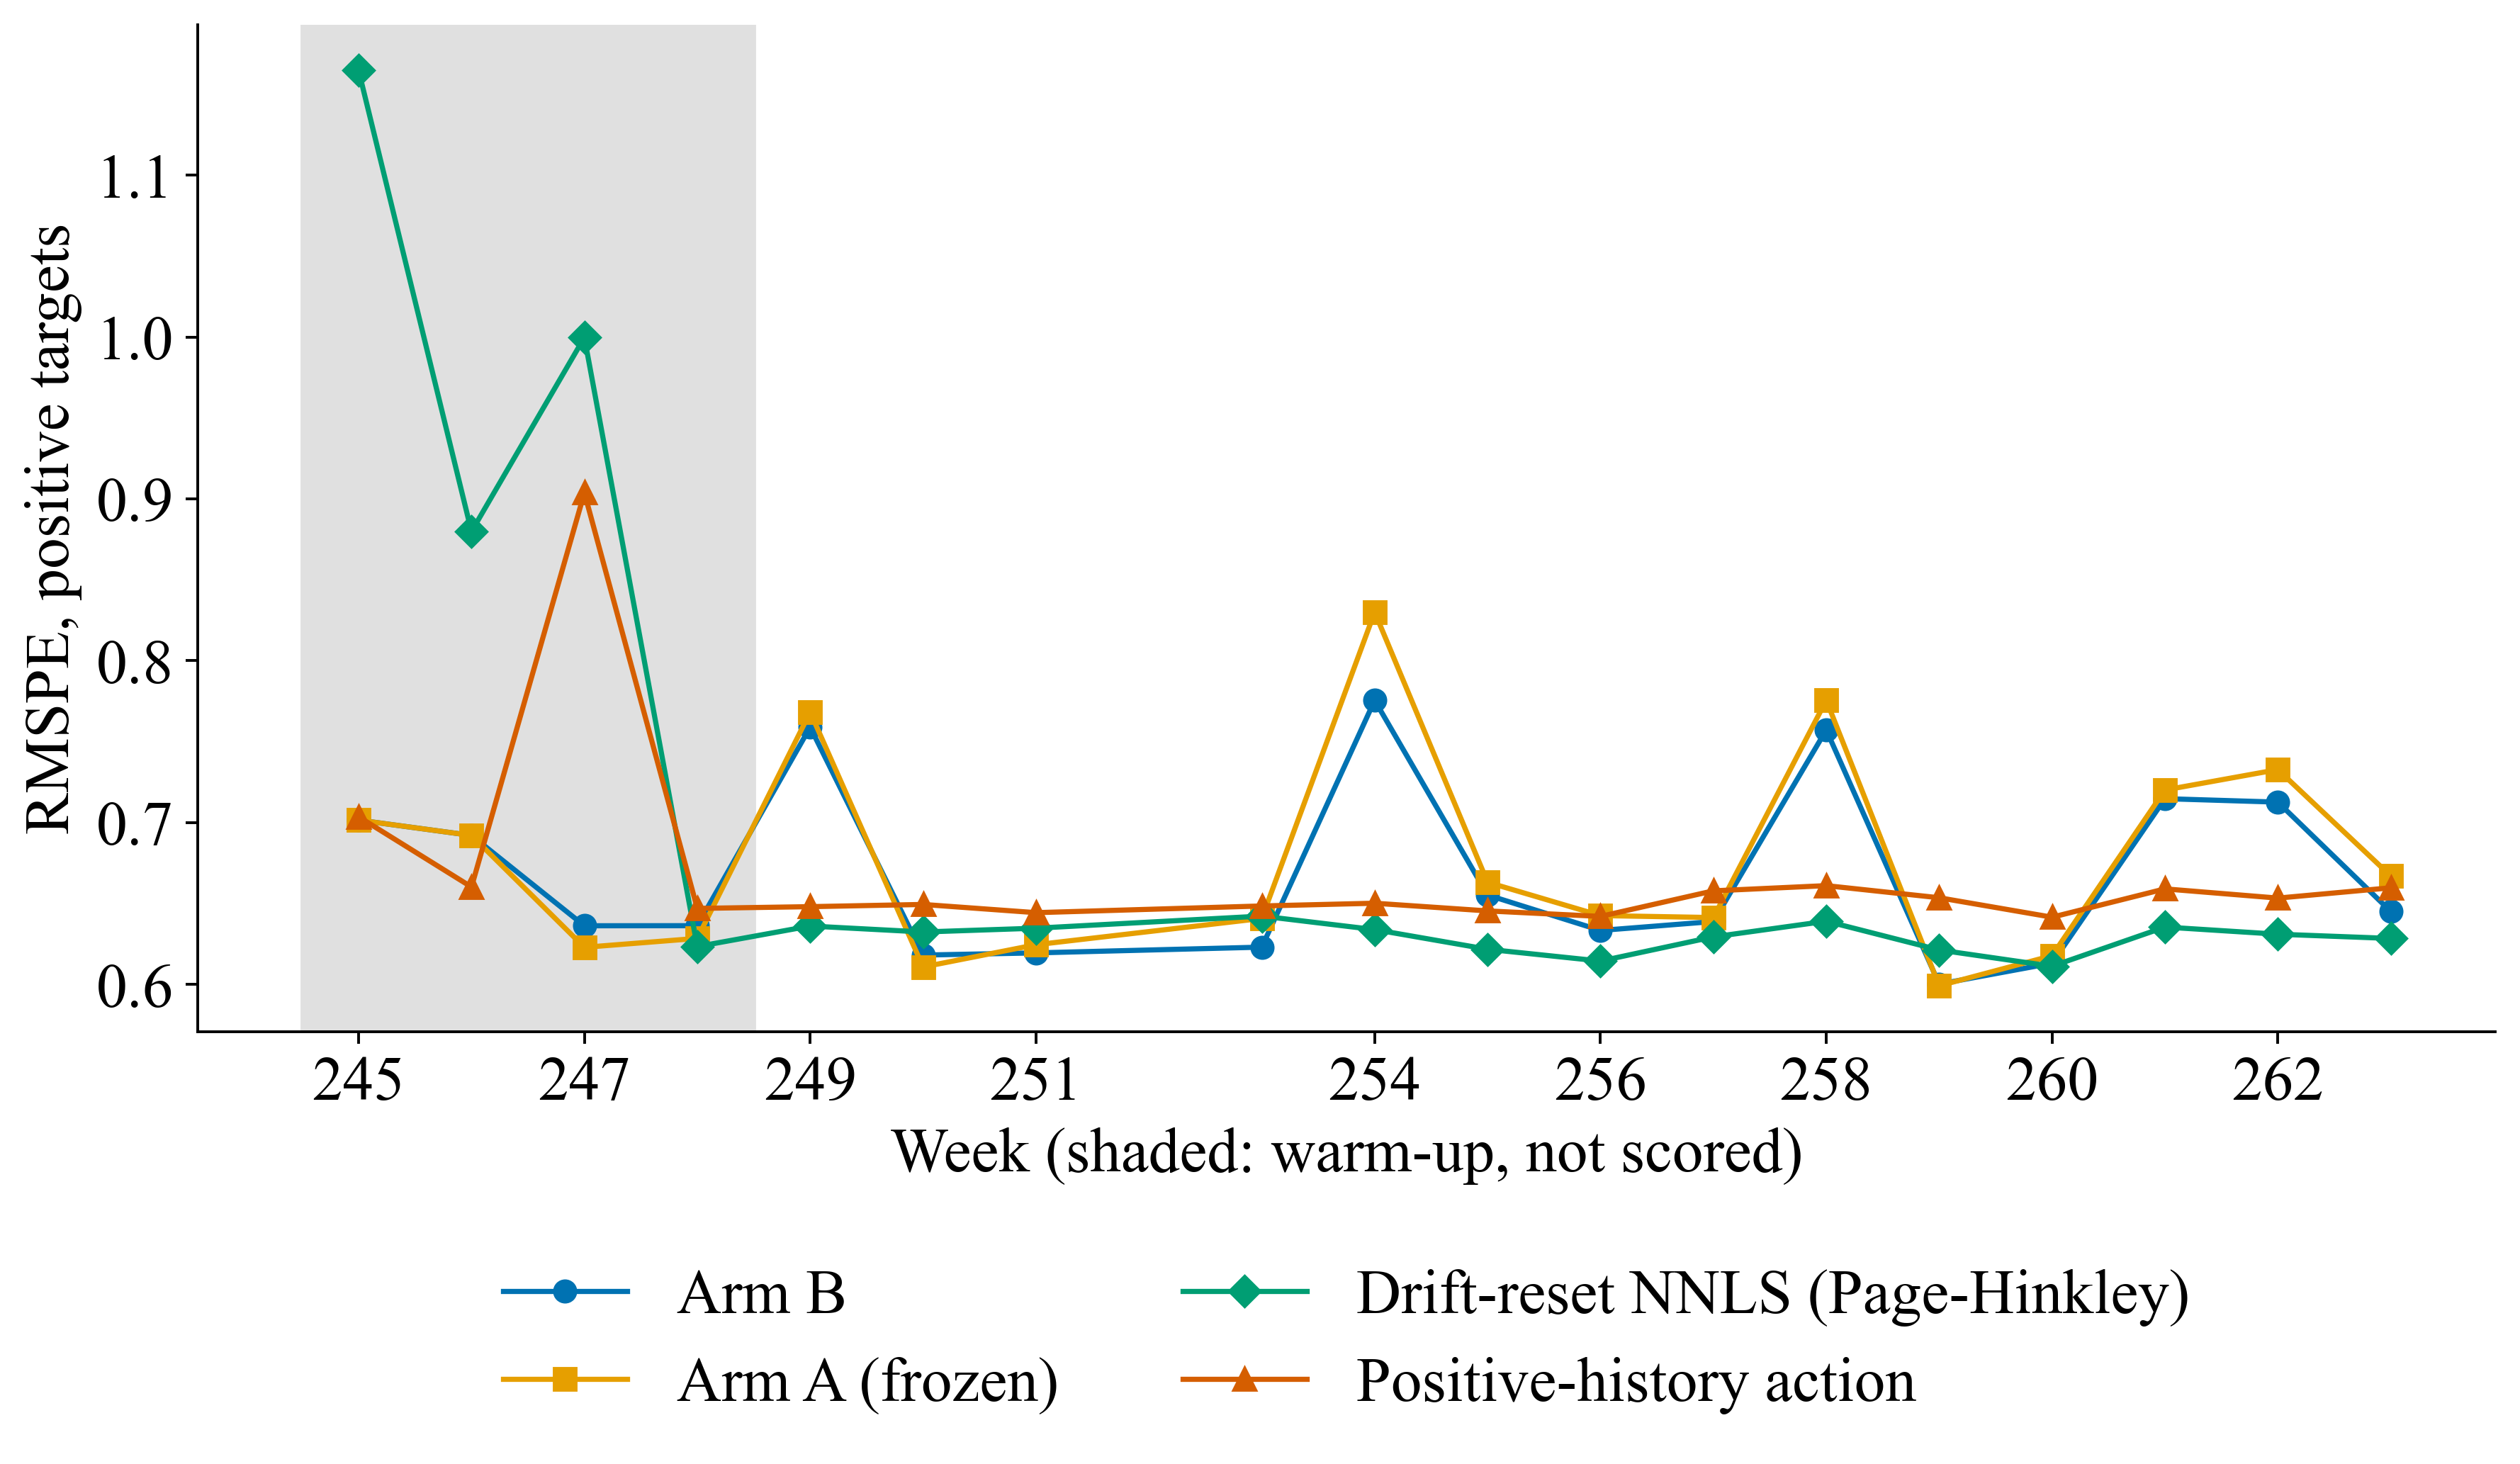

In [18]:
# NB05B_DYNAMICS
wB=pd.DataFrame(trB['W'],columns=AGENTS)[scored].mean();wA=pd.DataFrame(trA['W'],columns=AGENTS)[scored].mean();GUARD_SHARE=float(np.mean(outB[scored]!=trB['MIX'][scored]));act=trB['ACT'].sum(1)
table(pd.DataFrame({'Agent':wB.sort_values(ascending=False).index,'Mean weight, arm B':wB.sort_values(ascending=False).to_numpy(),'Mean weight, arm A':wA.reindex(wB.sort_values(ascending=False).index).to_numpy(),'Pooled RMSPE':[board_row(Pq[:,AGENTS.index(a)])['Pooled RMSPE'] for a in wB.sort_values(ascending=False).index]}),'agent_weights_b')
table(pd.DataFrame([{'Share of scored rows decided by the guard':GUARD_SHARE,'Mean active agents':float(act[scored].mean()),'Weight scope':CFG_B.get('weight_mode','global'),'Weight criterion':CFG_B.get('score','logmass'),'Weight discount':CFG_B['disc_w']}]),'dynamics_b',fmt='%.3f')
BEST_COMB=str(board[board.Model.str.startswith('C: ')&~board.Model.str.contains('Best single')].iloc[0].Model);BEST_B=str(board[board.Model.str.startswith('B: ')].iloc[0].Model)
fig,ax=plt.subplots(figsize=(10.5,6.4))
for (n,v),col,mk in zip({'Arm B':outB,'Arm A (frozen)':outA,BEST_COMB[3:]:fc[BEST_COMB],BEST_B[3:]:fc[BEST_B]}.items(),PALETTE,'osD^'):ax.plot(weeks_all,[rmspe(y[wk==w],v[wk==w]) for w in weeks_all],color=col,marker=mk,label=n)
ax.axvspan(244.5,248.5,color='0.88',zorder=0);ax.set(xlabel='Week (shaded: warm-up, not scored)',ylabel='RMSPE, positive targets');ax.set_xticks(weeks_all[::2]);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_m5_arm_b_weekly')

### 15. Predictive intervals of arm B with the frozen scale

In [19]:
# NB05B_INTERVALS
def mix_q_b(mk,q,scale=FROZEN['pi_scale']):return mixture_quantile(trB['W'][mk],trB['MU'][mk],trB['SG'][mk],q,count=(trB['P'][mk],trB['LAW']*scale,trB['LAW_IDX'][mk]))
pis=[]
for b in SCORED+['Pooled (F2+D)']:
    mk=scored if b.startswith('Pooled') else mask[b];lo,hi=mix_q_b(mk,0.05),mix_q_b(mk,0.95);yy=y[mk];cov=float(np.mean((yy>=lo)&(yy<=hi)));width=hi-lo
    pis.append({'Block':b,'Rows':int(mk.sum()),'PICP90':cov,'Coverage error':abs(cov-0.9),'MPIW90':float(width.mean()),'Interval score':float(np.mean(width+20*np.maximum(lo-yy,0)+20*np.maximum(yy-hi,0))),'Zero-target coverage':float(np.mean(lo[yy==0]<=0))})
table(pd.DataFrame(pis),'interval_coverage_b')

,Block,Rows,PICP90,Coverage error,MPIW90,Interval score,Zero-target coverage
0,F2,82323,0.94177,0.04177,14.22655,24.56193,0.94357
1,D,301851,0.92639,0.02639,12.75986,27.57751,0.94123
2,Pooled (F2+D),384174,0.92968,0.02968,13.07415,26.93131,0.94174


### 16. Freeze of arm B for the sealed evaluation

In [20]:
# NB05B_FREEZE
FROZEN_B={'arm':'B','abma_cfg':CFG_B,'arm_a_cfg':CFG_A,'changes_against_arm_a':CHANGES,'selected':SELECTED,'component_ablations':BCOMP,'pi_scale':FROZEN['pi_scale'],'agents':AGENTS,'development_pooled_rmspe':{k:float(rmspe(y[scored],v[scored])) for k,v in fc.items()},'search_trials':int(len(trials)-1),'guard_share_scored':GUARD_SHARE,'rule_met':RULE_MET}
dump(BASE/'Configs/m5_frozen_b.json',FROZEN_B)
stream[['row_id','id','week','quantity','block']].assign(**{k:v.astype(np.float32) for k,v in fc.items() if not k.startswith(('C: ','B: '))}).to_parquet(OUT/'development_forecasts_b.parquet',index=False)